# BRIDGE and TCH-Net

**A Benchmark and Gated Baseline for IoT Intrusion Detection**

Experimental notebook: benchmark construction, TCH-Net v2, all baselines, ablations, and the leave-one-dataset-out (LODO) diagnosis-and-repair protocol.


## Revision notes (response to Reviewer 1, JNSM)
This version changes the evaluation protocol. **Every table must be regenerated by re-running the notebook.**

| Reviewer comment | Change |
|---|---|
| Minor 1: validation set | Each dataset is now split **train / val / test = 70 / 10 / 20 %** by row order, *before* windowing. Windows are built inside each partition, so none span two partitions. Early stopping and checkpoint selection use **validation only**; previously they monitored the test set. The test rows are unchanged. |
| Minor 1 (LODO) | LODO early stopping uses a validation slice of the **source** datasets (last 10% of each). Previously it used the labelled held-out target. |
| Major 1: statistics | Baselines use the **same 5 seeds** as TCH-Net. Tests are **paired by seed**, and ΔF1 is computed from the same pairs. The primary test is a two-sided paired t-test with Bonferroni correction, and significance is reported with direction. The cell also reports the one-sided p, exact Wilcoxon, a 95% CI of the difference, and per-seed differences. SDs now use ddof = 1. |
| Major 2: TTBN across architectures | New **BN-coverage table**. New **per-model repair decomposition**: 0.5-threshold and calibrated F1, each with and without TTBN. All models use the same LODO fold builder and the same threshold-calibration helpers. |
| (consistency) | Gate recalibration is selected on validation and evaluated on the full test set. Convergence curves plot validation F1. |


## Imports


In [1]:
import os, glob, json, time, warnings, copy, gc, itertools, math
warnings.filterwarnings('ignore')
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

import numpy as np
import pandas as pd
import matplotlib
try:
    get_ipython()
    import matplotlib.pyplot as plt
except NameError:
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
import matplotlib.ticker as ticker

from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    f1_score, accuracy_score, precision_score, recall_score,
    roc_curve, precision_recall_curve, auc, matthews_corrcoef)
from sklearn.ensemble import RandomForestClassifier
from sklearn.manifold import TSNE
from scipy import stats as scipy_stats

try:
    from xgboost import XGBClassifier; XGB_OK = True
except ImportError:
    XGB_OK = False; print("XGBoost unavailable — fallback to GradientBoosting")

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True      # fastest CUDA kernels
    torch.backends.cudnn.deterministic = False  # benchmark requires non-deterministic

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch {torch.__version__} | Device: {device}")
print(f"CUDA: {torch.cuda.is_available()} | XGBoost: {XGB_OK}")


PyTorch 2.11.0+cu128 | Device: cuda
CUDA: True | XGBoost: True


## Canonical Feature Vocabulary (46 features)

These are **real network-flow features** with fixed physical meaning.
Every feature keeps its name and units regardless of which dataset it came from.
Features not present in a dataset are zero-filled — never fabricated.

**Zero-fill policy (known limitation):** Absent features are set to 0, which conflates
"true value is zero" with "feature not observed in this dataset." This is a design choice,
not an oversight. Mitigation: `combine()._balance()` enforces strict 1:1 class balance
*within* each dataset block before concatenation, removing the main shortcut-learning risk
(predicting label from dataset identity via the missingness fingerprint). Cell 7b quantifies
this directly — a missingness-only classifier achieves accuracy indistinguishable from the
majority-class baseline. Post-scaling behaviour of zero-filled slots is also characterised
in Cell 7b.

**Grouping for T/C/H branches:**
- **T-branch temporal** (indices 0-16): rates, durations, counts that change over time
- **H-branch statistical** (indices 17-37): packet size distributions, IAT distributions
- **Both branches** (indices 38-45): TCP flags, header info, window sizes

**Architecture citations for code below:**
- Depthwise Separable Convolutions: Howard et al. (2017) MobileNets
- Squeeze-Excitation blocks: Hu et al. (2018) SE-Net, CVPR
- Pre-LayerNorm stability: Xiong et al. (2020), ICML


In [2]:
# ── 46 canonical features ─────────────────────────────────────────────────
SEMANTIC_FEATURES = [
    # ── Flow-level counts & rates (T-branch primary) ─────────────────────
    "flow_duration",        # 0  total flow duration
    "pkt_count_fwd",        # 1  total forward packets
    "pkt_count_bwd",        # 2  total backward packets
    "byte_count_fwd",       # 3  total forward bytes
    "byte_count_bwd",       # 4  total backward bytes
    "pkt_rate",             # 5  packets per second (flow level)
    "byte_rate",            # 6  bytes per second
    "fwd_pkt_rate",         # 7  forward packets per second
    "bwd_pkt_rate",         # 8  backward packets per second
    "fwd_byte_rate",        # 9  forward bytes per second
    "bwd_byte_rate",        # 10 backward bytes per second
    "pkt_count_total",      # 11 total packets (fwd + bwd)
    "byte_count_total",     # 12 total bytes
    "fwd_pkt_len_total",    # 13 total length of fwd packets
    "bwd_pkt_len_total",    # 14 total length of bwd packets
    "subflow_fwd_pkts",     # 15 subflow forward packets
    "subflow_bwd_pkts",     # 16 subflow backward packets
    # ── Packet size statistics (H-branch primary) ────────────────────────
    "pkt_len_min",          # 17
    "pkt_len_max",          # 18
    "pkt_len_mean",         # 19
    "pkt_len_std",          # 20
    "pkt_len_var",          # 21
    "fwd_pkt_len_min",      # 22
    "fwd_pkt_len_max",      # 23
    "fwd_pkt_len_mean",     # 24
    "fwd_pkt_len_std",      # 25
    "bwd_pkt_len_min",      # 26
    "bwd_pkt_len_max",      # 27
    "bwd_pkt_len_mean",     # 28
    "bwd_pkt_len_std",      # 29
    # ── IAT statistics (T + H) ───────────────────────────────────────────
    "iat_mean",             # 30
    "iat_std",              # 31
    "iat_max",              # 32
    "iat_min",              # 33
    "fwd_iat_mean",         # 34
    "fwd_iat_std",          # 35
    "bwd_iat_mean",         # 36
    "bwd_iat_std",          # 37
    # ── TCP flags (H-branch) ─────────────────────────────────────────────
    "flag_syn",             # 38
    "flag_ack",             # 39
    "flag_fin",             # 40
    "flag_rst",             # 41
    "flag_psh",             # 42
    "flag_urg",             # 43
    # ── Header / window ──────────────────────────────────────────────────
    "fwd_header_len",       # 44
    "init_win_fwd",         # 45
]
N_SEM = len(SEMANTIC_FEATURES)
SEM_IDX = {name: i for i, name in enumerate(SEMANTIC_FEATURES)}
print(f"Canonical vocabulary: {N_SEM} features")

# ── Per-dataset alias maps ───────────────────────────────────────────────
# Key = canonical name. Value = list of possible column names (case-insensitive).
# ONLY genuinely equivalent features are mapped. No fabricated proxies.
# Short aliases (<5 chars) NEVER matched via substring — only exact match.
#
# ── DATASET RESET (v7) ────────────────────────────────────────────────────
# CIC-IoT-DIAD-2024 (Mostafa Ali Ogab, Kaggle) was confirmed BROKEN — every
# file (including attack-named files) carries "NeedManualLabel" in the Label
# column. Genuinely unusable for supervised learning. DROPPED.
# CICIoMT-2024 (Lian Mollick, Kaggle) was confirmed WRONG VARIANT — 45 cols,
# no label column at all (same reduced schema as CIC-IoT-2023). DROPPED.
#
# Replaced with, and verified directly against user-supplied sample CSVs:
#   • CICIDS-2017                          (sample: cicids-2017-friday[-plus].csv)
#   • CIC-BCCC-NRC-TabularIoTAttacks-2024   (sample: cic-bccc-nrc-tabulariotAttack.csv)
#   • CICIoMT-2024 (Train-Test, D. Kilichev) (sample: ciciomt-{train,test}-set.csv)

# ── ALIAS_FLOWMETER ──────────────────────────────────────────────────────
# Shared by CICIDS-2017 AND CIC-BCCC-NRC-TabularIoTAttacks-2024.
# Verified column-for-column against both uploaded samples — they use the
# IDENTICAL CICFlowMeter naming convention (BCCC's updated extractor):
#   "Total Fwd Packet"           (singular, no trailing 's')
#   "Total Bwd packets"          (lowercase 'p', trailing 's')
#   "Total Length of Fwd Packet" (singular)
#   "Total Length of Bwd Packet" (singular)
#   "FWD Init Win Bytes"         (upper-case FWD)
# Old verbose CICIDS MachineLearningCSV.zip names ("Total Fwd Packets",
# "Init_Win_bytes_forward", ...) are kept as fallback aliases in case a
# differently-formatted CICIDS-2017 file is substituted later.
# cic-bccc-nrc-tabulariotAttack.csv additionally carries an explicit
# "Attack Name" string column (e.g. "Benign Traffic") used for labeling —
# see load_cic_bccc_nrc() below — it is NOT part of the feature vocabulary.
ALIAS_FLOWMETER = {
    "flow_duration":     ["Flow Duration"],
    "pkt_count_fwd":     ["Total Fwd Packet",              "Total Fwd Packets",
                          "Tot Fwd Pkts"],
    "pkt_count_bwd":     ["Total Bwd packets",             "Total Backward Packets",
                          "Tot Bwd Pkts"],
    "byte_count_fwd":    ["Total Length of Fwd Packet",    "Total Length of Fwd Packets",
                          "TotLen Fwd Pkts"],
    "byte_count_bwd":    ["Total Length of Bwd Packet",    "Total Length of Bwd Packets",
                          "TotLen Bwd Pkts"],
    "pkt_rate":          ["Flow Packets/s",                "Flow Pkts/s"],
    "byte_rate":         ["Flow Bytes/s",                  "Flow Byts/s"],
    "fwd_pkt_rate":      ["Fwd Packets/s",                 "Fwd Pkts/s"],
    "bwd_pkt_rate":      ["Bwd Packets/s",                 "Bwd Pkts/s"],
    "fwd_pkt_len_total": ["Total Length of Fwd Packet",    "Total Length of Fwd Packets",
                          "TotLen Fwd Pkts"],
    "bwd_pkt_len_total": ["Total Length of Bwd Packet",    "Total Length of Bwd Packets",
                          "TotLen Bwd Pkts"],
    "subflow_fwd_pkts":  ["Subflow Fwd Packets",           "Subflow Fwd Pkts"],
    "subflow_bwd_pkts":  ["Subflow Bwd Packets",           "Subflow Bwd Pkts"],
    "pkt_len_min":       ["Packet Length Min",             "Min Packet Length",
                          "Pkt Len Min"],
    "pkt_len_max":       ["Packet Length Max",             "Max Packet Length",
                          "Pkt Len Max"],
    "pkt_len_mean":      ["Packet Length Mean",            "Pkt Len Mean"],
    "pkt_len_std":       ["Packet Length Std",             "Pkt Len Std"],
    "pkt_len_var":       ["Packet Length Variance",        "Pkt Len Var"],
    "fwd_pkt_len_min":   ["Fwd Packet Length Min",         "Fwd Pkt Len Min"],
    "fwd_pkt_len_max":   ["Fwd Packet Length Max",         "Fwd Pkt Len Max"],
    "fwd_pkt_len_mean":  ["Fwd Packet Length Mean",        "Fwd Pkt Len Mean"],
    "fwd_pkt_len_std":   ["Fwd Packet Length Std",         "Fwd Pkt Len Std"],
    "bwd_pkt_len_min":   ["Bwd Packet Length Min",         "Bwd Pkt Len Min"],
    "bwd_pkt_len_max":   ["Bwd Packet Length Max",         "Bwd Pkt Len Max"],
    "bwd_pkt_len_mean":  ["Bwd Packet Length Mean",        "Bwd Pkt Len Mean"],
    "bwd_pkt_len_std":   ["Bwd Packet Length Std",         "Bwd Pkt Len Std"],
    "iat_mean":          ["Flow IAT Mean"],
    "iat_std":           ["Flow IAT Std"],
    "iat_max":           ["Flow IAT Max"],
    "iat_min":           ["Flow IAT Min"],
    "fwd_iat_mean":      ["Fwd IAT Mean"],
    "fwd_iat_std":       ["Fwd IAT Std"],
    "bwd_iat_mean":      ["Bwd IAT Mean"],
    "bwd_iat_std":       ["Bwd IAT Std"],
    "flag_syn":          ["SYN Flag Count",               "SYN Flag Cnt"],
    "flag_ack":          ["ACK Flag Count",               "ACK Flag Cnt"],
    "flag_fin":          ["FIN Flag Count",               "FIN Flag Cnt"],
    "flag_rst":          ["RST Flag Count",               "RST Flag Cnt"],
    "flag_psh":          ["PSH Flag Count",               "PSH Flag Cnt"],
    "flag_urg":          ["URG Flag Count",               "URG Flag Cnt"],
    "fwd_header_len":    ["Fwd Header Length",            "Fwd Header Len"],
    "init_win_fwd":      ["FWD Init Win Bytes",           "Init_Win_bytes_forward",
                          "Init Fwd Win Bytes",           "Init Fwd Win Byts"],
}
# Coverage: 42/46 (91%) — verified via live smoke test directly against both uploaded sample CSVs
# (cicids-2017-friday.csv, cic-bccc-nrc-tabulariotAttack.csv).
# 4 columns present in the CICIDS-2017 sample only (ICMP Code, ICMP Type,
# Total TCP Flow Time, Attempted Category) and 1 present in the BCCC sample
# only (Attack Name) are NOT canonical features and are intentionally unmapped.
# Unmapped canonical features (8): fwd_byte_rate, bwd_byte_rate (no per-direction
# byte-rate column in either dataset), pkt_count_total / byte_count_total
# (derived in combine() from fwd+bwd, not read from a column).

# ── ALIAS_IOMT ───────────────────────────────────────────────────────────
# CICIoMT-2024 (Train-Test split, D. Kilichev re-upload). 46 columns.
# Verified against: ciciomt-train-set.csv, ciciomt-test-set.csv
# SAME 45-feature schema as the a known-broken re-upload variant, but THIS
# variant carries a genuine, populated "Label" column:
#   train sample Label values: "DoS-TCP"
#   test  sample Label values: "Malformed_Data"
# (Dadkhah et al. 2024 — 19 attack-class string labels + benign; benign
# rows are NOT present in either 10-row sample, so the exact benign string
# is unconfirmed — load_ciciomt() below matches ANY label containing
# "benign" case-insensitively, not just an exact string, to stay robust
# to "Benign" / "BenignTraffic" / "Benign Traffic" variants.)
# Coverage: 17/46 (37%) features ALIAS-RESOLVE correctly after the Srate/Drate
# correction below. The EFFECTIVE coverage, measured empirically as "has at
# least one non-zero value across the full loaded dataset" (the stricter,
# more defensible metric — see Cell 6's feature_coverage_report.csv), is
# 16/46 (35%): "Drate" (-> bwd_pkt_rate) resolves to a real column, but that
# column's values are ~0 across virtually every row in this dataset — which
# independently matches the original CICIoT2023 paper's own published stats
# (Drate mean=5.46e-6, median/25/50/75th percentiles all exactly 0). This is
# a genuine property of the data, not a mapping defect. Separately, "Srate"
# (-> fwd_pkt_rate) and "Rate" (-> pkt_rate) were found to be numerically
# IDENTICAL in this dataset (again matching the source paper's stats table
# exactly) — both alias-resolve and both carry signal, but they are
# redundant with each other, not independent features. Report 16/46 (35%)
# as the dataset's effective coverage in the paper, not 17/46 — it is the
# number that will reproduce if a reviewer re-runs this pipeline.
# Protocol-presence flags (HTTP, HTTPS, TCP, UDP etc.) and statistical
# moment features (Magnitue, Radius, Covariance, Weight) have no
# CICFlowMeter equivalents — correctly zero-filled.
ALIAS_IOMT = {
    "pkt_count_total":  ["Number", "number"],
    "byte_count_total": ["Tot sum",  "tot sum",  "Tot size", "tot size"],
    "pkt_rate":         ["Rate",     "rate"],
    "fwd_pkt_rate":     ["Srate",    "srate"],   # see note below
    "bwd_pkt_rate":     ["Drate",    "drate"],   # see note below
    "pkt_len_min":      ["Min",      "min"],
    "pkt_len_max":      ["Max",      "max"],
    "pkt_len_mean":     ["AVG",      "avg"],
    "pkt_len_std":      ["Std",      "std"],
    "pkt_len_var":      ["Variance", "variance"],
    "iat_mean":         ["IAT",      "iat"],
    "flag_syn":         ["syn_flag_number", "syn_count"],
    "flag_ack":         ["ack_flag_number", "ack_count"],
    "flag_fin":         ["fin_flag_number", "fin_count"],
    "flag_rst":         ["rst_flag_number", "rst_count"],
    "flag_psh":         ["psh_flag_number"],
    "fwd_header_len":   ["Header_Length",   "header_length"],
}
# Srate / Drate added after cross-checking against the CICIoT2023 extractor's
# own published feature definitions (Neto et al. 2023, Sensors 23(13):5941;
# corroborated by multiple independent secondary sources): "Srate = rate of
# outbound packets' transmission in a flow", "Drate = rate of inbound
# packets' transmission in a flow" — directly equivalent to fwd_pkt_rate /
# bwd_pkt_rate (forward/backward packet rate), just computed over this
# extractor's sliding-window unit instead of a CICFlowMeter 5-tuple flow.
#
# Explicitly REJECTED: mapping the "Duration" column to "flow_duration".
# It looks tempting from the name alone, but the same paper's feature table
# documents "Duration" as the packet's IP Time-To-Live (TTL) — confirmed by
# its value range (0-255, matching an 8-bit TTL field) in the paper's
# descriptive statistics table. Mapping it to flow_duration would be a
# genuine semantic error (different physical quantity), not a coverage gain.
# This dataset's actual "flow_duration" column (present in the official
# 47-feature CICIoT2023 schema) is simply ABSENT from this 46-col CICIoMT2024
# re-upload — a genuine schema gap, not an alias-mapping oversight.
#
# Also explicitly NOT mapped (genuine schema mismatch, verified against the
# same source): Protocol Type (categorical, not a canonical feature),
# ece_flag_number / cwr_flag_number (no ECE/CWR slots in the 46-feature
# vocabulary), all protocol-presence one-hot flags (HTTP/HTTPS/DNS/.../LLC —
# no protocol-indicator slot exists in the vocabulary), and Magnitude /
# Radius / Covariance / Weight (composite cross-direction statistics with
# no single-feature canonical equivalent — e.g. Weight is explicitly defined
# as incoming_packets x outgoing_packets, a multiplicative composite that
# does not correspond to any additive canonical count we have).
# Coverage after this correction: 17/46 (37%) — up from 15/46, verified by
# re-running build_semantic_vector() against the real sample CSVs.
# NOTE: Short aliases (Min, Max, AVG, Std, IAT, Rate) are length < 5 chars.
# They are correctly handled by the exact case-insensitive match in
# build_semantic_vector() step 2, which runs BEFORE the substring guard.
# The substring guard in step 3 (len < 5 → skip) only applies to substring
# fallback — exact alias match is always attempted first and has no length guard.
# Coverage: 15/46 (genuine ceiling — extractor design limitation)

# ── ALIAS_UNSW ────────────────────────────────────────────────────────────
# UNSW-NB15 (Moustafa & Slay, MilCIS 2015). Argus + Bro/Zeek extractor — a
# THIRD, genuinely distinct extractor family (neither CICFlowMeter nor the
# CIC-IoT sliding-window statistical extractor). This is the heterogeneity
# upgrade: BRIDGE now spans three independent flow-extraction toolchains.
# Enterprise/general network testbed (NOT IoT-specific — same scope caveat as
# CICIDS-2017; see UNSW_SCOPE_NOTE below).
#
# Verified against the CLEAN labelled split shipped by the Kaggle mirror
# (mrwellsdavid/unsw-nb15): UNSW_NB15_training-set.csv / _testing-set.csv —
# 45 columns WITH a header, binary numeric `label` (0=normal, 1=attack) and a
# human-readable `attack_cat` family string. load_unsw_nb15() reads ONLY files
# that expose BOTH a `label` and a `dur` header column, which automatically
# rejects the raw headerless UNSW-NB15_1..4.csv captures and the
# NUSW-NB15_features.csv metadata file.
#
# Mappings follow the ORIGINAL 2015 feature definitions (Moustafa & Slay),
# mapped by PHYSICAL quantity, not by name:
#   dur    = record total duration                    -> flow_duration
#   spkts  = source->dest packet count                -> pkt_count_fwd
#   dpkts  = dest->source packet count                -> pkt_count_bwd
#   sbytes = source->dest transaction bytes           -> byte_count_fwd
#                                                        + fwd_pkt_len_total
#   dbytes = dest->source transaction bytes           -> byte_count_bwd
#                                                        + bwd_pkt_len_total
#   smean  = mean packet size, source direction       -> fwd_pkt_len_mean
#   dmean  = mean packet size, dest direction         -> bwd_pkt_len_mean
#   sinpkt = source inter-packet arrival time (mSec)  -> fwd_iat_mean
#   dinpkt = dest inter-packet arrival time (mSec)    -> bwd_iat_mean
#   sload  = source data rate (BITS/sec)              -> fwd_byte_rate  [A]
#   dload  = dest data rate (BITS/sec)                -> bwd_byte_rate  [A]
#   swin   = source TCP window advertisement value    -> init_win_fwd   [B]
#
# [A] sload/dload are BITS/sec; fwd_byte_rate/bwd_byte_rate are BYTES/sec — a
#     constant 8x unit factor fully absorbed by the per-feature RobustScaler
#     (scale-invariant), so the mapping is honest at the level of
#     "forward/backward throughput". The unit difference is noted, not hidden.
# [B] swin is the advertised TCP receive-window (source side); init_win_fwd
#     (CICFlowMeter) is the initial forward-window byte count. Both encode the
#     forward TCP window size; mapped with this caveat noted.
#
# EXPLICITLY REJECTED (kept unmapped on purpose — Section 3.4.4 discipline):
#   * rate -> pkt_rate : the derived `rate` column's exact physical definition
#     is NOT in Moustafa & Slay's canonical 49-feature table (added only in the
#     derived train/test split). Rather than guess it is the flow packet-rate,
#     it is left unmapped. (Loss: 1 slot.)
#   * sjit/djit -> iat_std : jitter (mean deviation of packet delay) and the
#     std of inter-arrival times are correlated but NOT the same statistic. No
#     canonical "jitter" slot exists; mapping to iat_std would be a semantic
#     approximation, so it is rejected. (Loss: 2 slots.)
#   * synack/ackdat -> flag_* : these are TCP setup *times* (SYN->SYN_ACK,
#     SYN_ACK->ACK), NOT flag counts. UNSW-NB15's clean split carries NO TCP
#     flag-count columns (only a categorical `state` and these setup times), so
#     ALL flag_* slots are correctly left unmapped — a genuine schema gap, not
#     an oversight. This differing coverage profile vs the CICFlowMeter datasets
#     is exactly the point of a heterogeneous benchmark.
#   * sttl/dttl (IP TTL), stcpb/dtcpb (TCP base seq), tcprtt, sloss/dloss, dwin,
#     proto/service/state (categorical), ct_* (connection-count aggregates),
#     trans_depth/response_body_len (HTTP), is_* : no canonical flow-statistic
#     equivalent — correctly zero-filled.
#
# Effective coverage: 14/46 canonical slots resolve (12 distinct source
# columns; sbytes/dbytes each fill two slots, exactly as ALIAS_FLOWMETER
# dual-maps byte_count_* and *_pkt_len_total). pkt_count_total is additionally
# derived in combine() from fwd+bwd (not read from a column), same as the other
# datasets. Confirm the live number via Cell 6's coverage table and the Cell 2b
# diagnostic after attaching the real file.
ALIAS_UNSW = {
    "flow_duration":     ["dur"],
    "pkt_count_fwd":     ["spkts"],
    "pkt_count_bwd":     ["dpkts"],
    "byte_count_fwd":    ["sbytes"],
    "byte_count_bwd":    ["dbytes"],
    "fwd_pkt_len_total": ["sbytes"],
    "bwd_pkt_len_total": ["dbytes"],
    "fwd_pkt_len_mean":  ["smean"],
    "bwd_pkt_len_mean":  ["dmean"],
    "fwd_iat_mean":      ["sinpkt"],
    "bwd_iat_mean":      ["dinpkt"],
    "fwd_byte_rate":     ["sload"],
    "bwd_byte_rate":     ["dload"],
    "init_win_fwd":      ["swin"],
}

ALIAS_MAPS = {
    "CICIDS-2017":                          ALIAS_FLOWMETER,
    "CIC-BCCC-NRC-TabularIoTAttacks-2024":  ALIAS_FLOWMETER,
    "CICIoMT-2024":                         ALIAS_IOMT,
    "UNSW-NB15":                             ALIAS_UNSW,
}

def build_semantic_vector(df, ds_name):
    alias_map = ALIAS_MAPS.get(ds_name, {})
    col_lower = {c.strip().lower(): c for c in df.columns}
    out = np.zeros((len(df), N_SEM), dtype=np.float32)
    matched = []
    for sem_name in SEMANTIC_FEATURES:
        si = SEM_IDX[sem_name]
        col = None
        # 1. Exact match (case-insensitive)
        if sem_name in col_lower:
            col = col_lower[sem_name]
        # 2. Alias match (exact, case-insensitive — no length guard here)
        elif sem_name in alias_map:
            for alias in alias_map[sem_name]:
                al = alias.strip().lower()
                if al in col_lower:
                    col = col_lower[al]; break
        # 3. Substring fallback — MINIMUM LENGTH GUARD (len < 5 → skip)
        # Short aliases like "Min", "Max", "Std", "IAT", "Rate" must NOT
        # match via substring — prevents false hits on unrelated columns.
        if col is None and sem_name in alias_map:
            for alias in alias_map[sem_name]:
                al = alias.strip().lower()
                if len(al) < 5:
                    continue
                ms = [c for c in df.columns if al in c.strip().lower()]
                if ms: col = ms[0]; break
        # 3b. Normalised substring fallback (strip spaces/underscores)
        if col is None and sem_name in alias_map:
            for alias in alias_map[sem_name]:
                al = alias.strip().lower().replace(' ','').replace('_','')
                if len(al) < 5:
                    continue
                for c in df.columns:
                    cn = c.strip().lower().replace(' ','').replace('_','')
                    if al == cn or (len(al) > 4 and al in cn):
                        col = c; break
                if col: break
        if col is not None:
            vals = pd.to_numeric(df[col], errors='coerce').fillna(0).values
            out[:, si] = vals.astype(np.float32)
            matched.append(sem_name)
    return out, matched

print(f"Alias maps defined for {len(ALIAS_MAPS)} datasets")
for ds, am in ALIAS_MAPS.items():
    print(f"  {ds}: {len(am)} alias entries / {N_SEM} canonical = "
          f"{len(am)/N_SEM*100:.0f}% (alias entries; actual coverage verified at runtime)")
print()
print("NOTE: actual coverage verified at runtime by build_semantic_vector().")
print("Run Cell 2b (diagnostic) after Cell 6 to confirm per-dataset coverage.")
print("Short aliases (<5 chars) only match via exact alias lookup, NOT substring.")

# ── ZERO-FILL SEMANTICS NOTE (paper Section 3.4.1) ───────────────────────────
# Absent features are zero-filled: conflates "true value is zero" with
# "feature not observed". This is a known limitation, disclosed in the paper.
# Mitigation: combine()._balance() enforces 1:1 class balance within each
# dataset block, removing the shortcut-learning risk. Cell 7b verifies this
# empirically. Post-scaling zero-fill displacement is bounded by clip(±10).
# CICIDS-2017 scope note: CICIDS-2017 is a general enterprise IDS benchmark
# (Sharafaldin et al., ICISSP 2018), not an IoT-specific botnet dataset.
# It is retained for canonical vocabulary coverage (91%) and cross-extractor
# domain shift testing. See paper Section 3.3.1 and Section 6 (Limitations).
ZERO_FILL_NOTE = (
    "Absent features zero-filled — conflation with true-zero is a known "
    "limitation. See Cell 7b shortcut test and paper Section 3.4.1."
)
UNSW_SCOPE_NOTE = (
    "UNSW-NB15 is a general enterprise/network testbed (Moustafa & Slay 2015), "
    "NOT IoT-specific. Retained as a THIRD extractor family (Argus/Bro) for "
    "cross-extractor generalisation — same scope caveat as CICIDS-2017."
)
CICIDS2017_SCOPE_NOTE = (
    "CICIDS-2017 is a general enterprise IDS benchmark, NOT IoT-specific. "
    "Retained as vocabulary anchor and cross-extractor shift test only."
)
print(f"Zero-fill policy: {ZERO_FILL_NOTE}")
print(f"CICIDS-2017 scope: {CICIDS2017_SCOPE_NOTE}")

Canonical vocabulary: 46 features
Alias maps defined for 4 datasets
  CICIDS-2017: 42 alias entries / 46 canonical = 91% (alias entries; actual coverage verified at runtime)
  CIC-BCCC-NRC-TabularIoTAttacks-2024: 42 alias entries / 46 canonical = 91% (alias entries; actual coverage verified at runtime)
  CICIoMT-2024: 17 alias entries / 46 canonical = 37% (alias entries; actual coverage verified at runtime)
  UNSW-NB15: 14 alias entries / 46 canonical = 30% (alias entries; actual coverage verified at runtime)

NOTE: actual coverage verified at runtime by build_semantic_vector().
Run Cell 2b (diagnostic) after Cell 6 to confirm per-dataset coverage.
Short aliases (<5 chars) only match via exact alias lookup, NOT substring.
Zero-fill policy: Absent features zero-filled — conflation with true-zero is a known limitation. See Cell 7b shortcut test and paper Section 3.4.1.
CICIDS-2017 scope: CICIDS-2017 is a general enterprise IDS benchmark, NOT IoT-specific. Retained as vocabulary anchor an

## Configuration


In [3]:
class Config:
    # ── Kaggle dataset paths ──────────────────────────────────────────────
    # PRIMARY (flow-level, all CICFlowMeter-compatible)
    CICIDS_PATH  = "/kaggle/input/datasets/bertvankeulen/cicids-2017"
    BCCC_PATH    = "/kaggle/input/datasets/kabeleswarpe/cic-bccc-nrc-tabulariotattacks-2024"
    IOMT_PATH    = "/kaggle/input/datasets/sinfdosh1990/ciciomt2024"
    UNSW_PATH    = "/kaggle/input/datasets/mrwellsdavid/unsw-nb15"

    # Auto-detect
    USE_CICIDS  = os.path.isdir(CICIDS_PATH) if CICIDS_PATH else False
    USE_BCCC    = os.path.isdir(BCCC_PATH)   if BCCC_PATH   else False
    USE_IOMT    = os.path.isdir(IOMT_PATH)   if IOMT_PATH   else False
    USE_UNSW    = os.path.isdir(UNSW_PATH)   if UNSW_PATH   else False

    # ── Row caps per dataset ──────────────────────────────────────────────
    CICIDS_MAX   = 500_000
    BCCC_MAX     = 3_000_000   # BCCC aggregates 9 IoT datasets, 1M+ records
    IOMT_MAX     = 3_000_000
    UNSW_MAX     = 500_000     # UNSW-NB15 train+test ~257k rows (cap not hit)

    # ── Sequence parameters ───────────────────────────────────────────────
    WINDOW_SIZE = 32
    STRIDE      = 4
    MAX_TRAIN_SEQ = 800_000
    MAX_TEST_SEQ  = 200_000
    MAX_VAL_SEQ   = 200_000

    # ── Class balance ─────────────────────────────────────────────────────
    TARGET_ATK_BEN_RATIO = 1.0   # strict 1:1 → ~43% attack windows after windowing

    # ── Training ──────────────────────────────────────────────────────────
    EPOCHS        = 30
    WARMUP        = 3
    EARLY_STOP    = 7
    BATCH_SIZE    = 512
    LR            = 5e-4
    WD            = 1e-4
    FOCAL_GAMMA   = 2.5
    LABEL_SMOOTH  = 0.01
    AUX_WT        = 0.05
    DEEP_SUP_WT   = 0.3     # per-expert CE weight (deep supervision; prevents gate collapse)
    CORAL_WT      = 0.5     # source-domain CORAL alignment weight (0 disables; ablatable)
    TTBN_ADAPT    = True    # transductive test-time BatchNorm adaptation at LODO eval

    # ── Architecture ──────────────────────────────────────────────────────
    EMBED_DIM     = 32
    CONV_CH       = [64, 128, 128]
    GRU_HIDDEN    = 128
    GRU_LAYERS    = 2
    ATTN_HEADS    = 8
    DROPOUT       = 0.20
    CBGAF_DIM     = 128

    # ── Evaluation ────────────────────────────────────────────────────────
    EVAL_SEEDS     = [42, 123, 456, 789, 2024]
    FAST_SEEDS     = [42, 123, 456]
    # REVISION (R1-M1): baselines use the SAME 5 seeds as TCH-Net so every
    # in-distribution paired test is matched seed-for-seed (n = 5 pairs).
    BASE_SEEDS     = [42, 123, 456, 789, 2024]
    LODO_SEEDS     = [42, 123, 456]   # 3 seeds per fold (descriptive spread only; no paired test)
    ABL_EPOCHS     = 30
    BASE_EPOCHS    = 30
    LODO_EPOCHS    = 30
    WARMUP_FAST    = 5

    N_DEV_CATS = 6   # 0=sensor, 1=camera, 2=appliance, 3=IIoT, 4=server, 5=unknown

    # ── Realistic deployment prior ─────────────────────────────────
    # Attack prevalence in real IoT traffic is typically 1-10%.
    # We evaluate at 5% to simulate realistic deployment conditions.
    REALISTIC_ATK_PRIOR = 0.05   # P(attack) in realistic traffic

    # ── HP sensitivity ranges ──────────────────
    HP_SENS_CONFIGS = [
        {'lr': 5e-4, 'wd': 1e-4, 'dropout': 0.20},   # default
        {'lr': 1e-3, 'wd': 1e-4, 'dropout': 0.20},   # 2x LR
        {'lr': 2e-4, 'wd': 1e-4, 'dropout': 0.20},   # 0.4x LR
        {'lr': 5e-4, 'wd': 1e-3, 'dropout': 0.20},   # 10x WD
        {'lr': 5e-4, 'wd': 1e-4, 'dropout': 0.30},   # higher dropout
        {'lr': 5e-4, 'wd': 1e-4, 'dropout': 0.10},   # lower dropout
    ]
    HP_SENS_SEEDS = [42, 123]   # 2 seeds × 6 configs = 12 runs
    N_CLASSES  = 2   # benign vs attack (binary IDS)
    N_DS_SRC   = 4   # CICIDS-2017=0, BCCC=1, CICIoMT-2024=2, UNSW-NB15=3

    # Device category map: dataset → {device_id: category_id}
    # device_id is an arbitrary per-loader integer; category is one of N_DEV_CATS
    DEVICE_CAT_MAP = {
        "CICIDS-2017":                          {0: 4},   # 0→server/workstation
        "CIC-BCCC-NRC-TabularIoTAttacks-2024":  {1: 0},   # 1→IoT sensor/device (mixed: cameras, lights, sensors)
        "CICIoMT-2024":                         {2: 3},   # 2→IIoT/medical device
        "UNSW-NB15":                            {3: 4},   # 3→server/workstation (enterprise, non-IoT)
    }

    # ── Reviewer-requested fixes ──────────────────────────────────────────────
    # chronological split is the DEFAULT.
    SPLIT_MODE      = 'chronological'   # 'chronological' | 'random'

    # REVISION (R1-m1): explicit validation subset for early stopping and
    # checkpoint selection. Carved chronologically per dataset BEFORE windowing:
    # train | val | test = 70 | 10 | 20 % of rows in row order. The test rows are
    # identical to the previous two-way split and are never used for selection.
    VAL_FRAC        = 0.10
    # LODO: validation is carved the same way from the SOURCE datasets only —
    # the held-out target domain is never used for early stopping.
    LODO_VAL_FRAC   = 0.10

    # feature-availability mask
    USE_MISS_MASK   = True

    # common seed set for all paired tests (REVISION R1-M1: 5 matched seeds)
    COMMON_SEEDS    = [42, 123, 456, 789, 2024]
    STAT_ALPHA      = 0.05   # family-wise level for Bonferroni-corrected paired tests

    # IDS operational metrics
    FIXED_FPR_LEVELS   = [0.001, 0.01, 0.05]
    FIXED_TPR_LEVELS   = [0.95, 0.99]  # also computes FPR@TPR99 for every model

    OUT = "tch_net_v2_results"

    # ── LODO baseline names (5 DL models run in LODO alongside TCH-Net) ────
    # Transformer-IDS, BiGRU-IDS, MLP-IDS, CNN-LSTM, 1D-CNN-IDS
    LODO_BASELINE_NAMES = [
        "Transformer-IDS",
        "BiGRU-IDS",
        "MLP-IDS",
        "CNN-LSTM",
        "1D-CNN-IDS",
    ]

os.makedirs(Config.OUT, exist_ok=True)
PAL = ['#2196F3','#F44336','#4CAF50','#FF9800','#9C27B0',
       '#00BCD4','#795548','#E91E63','#607D8B','#CDDC39']
def SAVE(n, fig=None):
    """Save current figure and display inline in Jupyter."""
    _f = fig if fig is not None else plt.gcf()
    _f.savefig(os.path.join(Config.OUT, n), bbox_inches='tight', dpi=150)

print("Dataset availability:")
for n, f in [("CICIDS-2017", Config.USE_CICIDS),
             ("CIC-BCCC-NRC-TabularIoTAttacks-2024", Config.USE_BCCC),
             ("CICIoMT-2024", Config.USE_IOMT),
             ("UNSW-NB15", Config.USE_UNSW)]:
    print(f"  {n:<38}: {'FOUND' if f else 'NOT FOUND'} [PRIMARY]")


Dataset availability:
  CICIDS-2017                           : FOUND [PRIMARY]
  CIC-BCCC-NRC-TabularIoTAttacks-2024   : FOUND [PRIMARY]
  CICIoMT-2024                          : FOUND [PRIMARY]
  UNSW-NB15                             : FOUND [PRIMARY]


## Dataset Loaders

Each loader:
1. Finds and reads CSV/Parquet files
2. Identifies label column and converts to binary (0=benign, 1=attack)
3. Calls `build_semantic_vector()` to map to the 46-feature canonical space
4. Reports coverage: how many of the 46 features were matched
5. Returns `(X_semantic, y, device_ids)`

**No fabricated mappings.** If a dataset lacks `iat_mean`, that column stays zero.


In [4]:
ATTACK_TYPE_STORE = {}

def _subsample(X, y, max_n, extras=None, seed=42):
    """
    Subsample to at most max_n rows, preserving the original class ratio
    but enforcing a minimum of 5000 samples per class when possible.
    The actual class re-balancing to 1:1 happens later in combine()._balance().
    This function only caps extremely large datasets to avoid OOM.
    """
    if max_n is None or len(X) <= max_n:
        return (X, y) + (tuple(extras) if extras else ())
    rng = np.random.RandomState(seed)
    ben = np.where(y==0)[0]; atk = np.where(y==1)[0]
    r = len(ben) / len(y)
    nb = min(len(ben), max(5_000, int(max_n * r)))
    na = min(len(atk), max(5_000, max_n - nb))
    if nb + na > max_n:
        scale = max_n / (nb + na)
        nb = max(5_000, int(nb * scale))
        na = max(5_000, min(max_n - nb, int(na * scale)))
    nb = min(nb, len(ben)); na = min(na, len(atk))
    keep = np.concatenate([rng.choice(ben, nb, replace=False),
                           rng.choice(atk, na, replace=False)])
    rng.shuffle(keep)
    result = [X[keep], y[keep]]
    if extras:
        for a in extras: result.append(a[keep])
    print(f"  Subsampled {len(X):,} -> {len(keep):,} "
          f"(ben={nb:,} atk={na:,} atk%={na/(nb+na)*100:.1f}%)")
    return tuple(result)

def augment_minority(X, y, target=5000, noise_std=0.01, seed=42):
    rng = np.random.RandomState(seed)
    ben_idx = np.where(y == 0)[0]
    atk_idx = np.where(y == 1)[0]
    minority_idx = ben_idx if len(ben_idx) < len(atk_idx) else atk_idx
    minority_label = 0 if len(ben_idx) < len(atk_idx) else 1
    n_minority = len(minority_idx)
    if n_minority >= target:
        return X, y
    n_needed = target - n_minority
    print(f"    Augmenting minority ({n_minority} -> {target}, "
          f"generating {n_needed} synthetic rows via Gaussian noise sigma={noise_std})")
    chosen = rng.choice(minority_idx, n_needed, replace=True)
    X_aug = X[chosen] + rng.normal(0, noise_std,
                                    size=(n_needed, X.shape[1])).astype(np.float32)
    X_aug = np.clip(X_aug, X.min(axis=0), X.max(axis=0))
    y_aug = np.full(n_needed, minority_label, dtype=np.int32)
    X_new = np.vstack([X, X_aug])
    y_new = np.hstack([y, y_aug])
    print(f"    After augmentation: ben={(y_new==0).sum():,} atk={(y_new==1).sum():,}")
    return X_new, y_new

def _is_benign_mask(lbl_series):
    """
    Robust benign/attack split for an object-dtype label column.
    Matches an exact small set of known benign tokens AND any label that
    merely CONTAINS "benign" (case-insensitive) — covers "Benign",
    "BENIGN", "BenignTraffic", "Benign Traffic", "Benign_Traffic", etc.
    without having to enumerate every uploader's exact string.
    """
    s = lbl_series.astype(str).str.strip().str.lower()
    exact = s.isin(['benign', 'benigntraffic', 'normal', '0'])
    contains = s.str.contains('benign', regex=False)
    return exact | contains

# ── CICIDS-2017 ──────────────────────────────────────────────────────────
# Verified against: cicids-2017-friday.csv, cicids-2017-friday-plus.csv
# (89 / 105 columns — "-plus" adds extra Flow ID / "Local_*" metadata columns
# that are not part of the canonical feature set and are safely ignored).
# Label column: "Label" (string, e.g. "BENIGN"). Uses ALIAS_FLOWMETER.
def load_cicids2017(data_dir, max_samples=None):
    print("\n"+"="*70+"\nLOADING CICIDS-2017\n"+"="*70)
    files = sorted(glob.glob(os.path.join(data_dir,"**","*.csv"), recursive=True) +
                   glob.glob(os.path.join(data_dir,"**","*.parquet"), recursive=True))
    files = [f for f in files if not any(kw in os.path.basename(f).lower()
             for kw in ['readme','feature','description'])]
    if not files: print(f"  No files in {data_dir}"); return None, None, None

    X_all, y_all, atk_all = [], [], []
    for fp in files:
        print(f"  Loading {os.path.basename(fp)}...")
        try:
            df = pd.read_parquet(fp) if fp.endswith('.parquet') else pd.read_csv(fp, low_memory=False)
            df.columns = df.columns.str.strip()
            lc = next((c for c in df.columns if c.lower().strip() == 'label'), None)
            if lc is None: print(f"    No label column"); continue
            y = (~_is_benign_mask(df[lc])).values.astype(np.int32)
            atk = np.where(y==0, 'BENIGN', df[lc].astype(str).str.strip().values)
            X_sem, matched = build_semantic_vector(df, "CICIDS-2017")
            np.nan_to_num(X_sem, copy=False, nan=0., posinf=1e9, neginf=-1e9)
            X_all.append(X_sem); y_all.append(y); atk_all.append(atk)
            print(f"    {len(y):,} rows | coverage={len(matched)}/{N_SEM} | "
                  f"Ben={int((y==0).sum()):,} Atk={int((y==1).sum()):,}")
        except Exception as e: print(f"    Skip: {e}")

    if not X_all: return None, None, None
    X = np.vstack(X_all); y = np.hstack(y_all); atk = np.hstack(atk_all)
    # device_id 0 → server/workstation category (Config.DEVICE_CAT_MAP["CICIDS-2017"])
    dev = np.zeros(len(y), dtype=np.int32)
    ATTACK_TYPE_STORE['CICIDS-2017'] = atk
    print(f"  Total: {len(y):,} | Ben={int((y==0).sum()):,} Atk={int((y==1).sum()):,}")
    X, y, dev = _subsample(X, y, max_samples, [dev])
    return X, y, dev

# ── CIC-BCCC-NRC-TabularIoTAttacks-2024 ──────────────────────────────────
# Replaces the broken CIC-IoT-DIAD-2024 (Mostafa Ali Ogab) — that dataset's
# Label column was "NeedManualLabel" on EVERY row, including attack-named
# files. Confirmed unusable; see Cell 2 dataset-reset note.
#
# BCCC research center (York University). CICFlowMeter-extracted, 85
# columns, aggregates 9 IoT datasets into one unified table. 1M+ records.
# Verified against: cic-bccc-nrc-tabulariotAttack.csv
#   Label column: "Label" — int, 0 in the (benign-only) sample.
#   "Attack Name" column: string, e.g. "Benign Traffic" in the sample.
# Label strategy: prefer the explicit "Attack Name" string (unambiguous
# human-readable family) when present; fall back to numeric Label
# (0=benign / nonzero=attack — works whether Label is strictly binary or a
# multi-class integer encoding, since != 0 is correct in both cases).
# Kaggle: kabeleswarpe/cic-bccc-nrc-tabulariotattacks-2024
def load_cic_bccc_nrc(data_dir, max_samples=None):
    print("\n"+"="*70+"\nLOADING CIC-BCCC-NRC-TabularIoTAttacks-2024\n"+"="*70)
    files = sorted(glob.glob(os.path.join(data_dir,"**","*.csv"), recursive=True))
    files = [f for f in files if not any(kw in os.path.basename(f).lower()
             for kw in ['readme','feature','summary','description'])]
    if not files: print(f"  No files in {data_dir}"); return None, None, None

    X_all, y_all, atk_all = [], [], []
    _printed_cols = False
    _acc_rows = 0
    _agree_n = 0; _agree_match = 0   # label cross-validation tally (see below)
    for fp in files:
        try:
            df = pd.read_csv(fp, low_memory=False)
            df.columns = df.columns.str.strip()
            if not _printed_cols:
                print(f"  Columns ({len(df.columns)}): {df.columns.tolist()[:20]}")
                if len(df.columns) > 20: print(f"    ... and {len(df.columns)-20} more")
                _printed_cols = True

            attack_col = next((c for c in df.columns if c.lower().strip() == 'attack name'), None)
            label_col  = next((c for c in df.columns if c.lower().strip() == 'label'), None)

            # ── Label cross-validation ──────────────────────────────────────
            # This dataset carries TWO independent label signals per row:
            # a human-readable family string ("Attack Name") and a numeric
            # code ("Label"). Rather than trusting one and discarding the
            # other, derive y from BOTH whenever both are present and report
            # their agreement rate. Attack Name is used as the actual ground
            # truth (explicit, unambiguous string) — Label is a corroborating
            # signal, not a silent fallback. Any disagreement is surfaced
            # immediately instead of being silently absorbed into the labels.
            if attack_col is not None and label_col is not None:
                atk_str = df[attack_col].astype(str).str.strip()
                y_from_attack = (~atk_str.str.lower().str.contains('benign')).values.astype(np.int32)
                lbl = df[label_col]
                if lbl.dtype == object:
                    y_from_label = (~_is_benign_mask(lbl)).values.astype(np.int32)
                else:
                    y_from_label = (lbl.values != 0).astype(np.int32)
                _agree = (y_from_attack == y_from_label)
                _agree_n += len(_agree); _agree_match += int(_agree.sum())
                if not _agree.all():
                    print(f"    NOTE: {int((~_agree).sum())}/{len(_agree)} rows in "
                          f"{os.path.basename(fp)} disagree between 'Attack Name' "
                          f"and numeric 'Label' — using 'Attack Name'")
                y = y_from_attack
                atk = atk_str.values
            elif attack_col is not None:
                atk_str = df[attack_col].astype(str).str.strip()
                y = (~atk_str.str.lower().str.contains('benign')).values.astype(np.int32)
                atk = atk_str.values
            elif label_col is not None:
                lbl = df[label_col]
                if lbl.dtype == object:
                    y = (~_is_benign_mask(lbl)).values.astype(np.int32)
                    atk = lbl.astype(str).values
                else:
                    y = (lbl.values != 0).astype(np.int32)
                    atk = np.where(y==0, 'Benign Traffic', lbl.astype(str).values)
            else:
                print(f"  No 'Attack Name' or 'Label' column in {os.path.basename(fp)} — skip")
                continue

            X_sem, matched = build_semantic_vector(df, "CIC-BCCC-NRC-TabularIoTAttacks-2024")
            np.nan_to_num(X_sem, copy=False, nan=0., posinf=1e9, neginf=-1e9)
            X_all.append(X_sem); y_all.append(y); atk_all.append(atk)
            _acc_rows += len(y)
            cov = len(matched)
            print(f"  {os.path.basename(fp)}: {len(y):,} rows | cov={cov}/{N_SEM} | acc={_acc_rows:,}")
            if cov == 0:
                print(f"    WARNING: 0 features matched! Actual columns: {list(df.columns[:15])}")
            if max_samples is not None and _acc_rows >= max_samples * 2:
                print(f"  Early exit at {_acc_rows:,} rows (max_samples={max_samples:,})")
                break
        except Exception as e: print(f"  Skip {os.path.basename(fp)}: {e}")

    if not X_all: return None, None, None
    X = np.vstack(X_all); y = np.hstack(y_all); atk = np.hstack(atk_all)
    if _agree_n > 0:
        _agree_pct = _agree_match / _agree_n * 100
        print(f"\n  Label cross-validation ('Attack Name' vs numeric 'Label'): "
              f"{_agree_match:,}/{_agree_n:,} rows agree ({_agree_pct:.2f}%)")
        if _agree_pct < 99.0:
            print(f"  WARNING: >1% disagreement between the two label columns — "
                  f"inspect before trusting either derivation in the paper.")
    # device_id 1 → generic IoT device category (BCCC mixes cameras/lights/sensors)
    dev = np.ones(len(y), dtype=np.int32)
    ATTACK_TYPE_STORE['CIC-BCCC-NRC-TabularIoTAttacks-2024'] = atk
    atk_pct = float((y==1).mean()*100)
    print(f"  Total: {len(y):,} | Ben={int((y==0).sum()):,} Atk={int((y==1).sum()):,} "
          f"({atk_pct:.1f}% attack)")
    if atk_pct < 5:
        print(f"  WARNING: very low attack% — check label parsing")
    rng_bccc = np.random.RandomState(42)
    perm = rng_bccc.permutation(len(X)); X, y, dev = X[perm], y[perm], dev[perm]
    X, y, dev = _subsample(X, y, max_samples, [dev])
    return X, y, dev

# ── CICIoMT-2024 (Train-Test, D. Kilichev) ───────────────────────────────
# Replaces the broken CICIoMT-2024 (Lian Mollick) variant — that upload had
# 45 columns and NO label column at all (same reduced schema as CIC-IoT-2023).
# Confirmed unusable; see Cell 2 dataset-reset note.
#
# Lashkari et al. (2024). Custom CIC statistical extractor (46-col schema
# incl. Label — identical feature schema to the broken variant, but THIS
# upload's Label column is genuinely populated).
# Verified against: ciciomt-train-set.csv ("DoS-TCP"), ciciomt-test-set.csv
# ("Malformed_Data"). Neither 10-row sample contains a benign row, so the
# exact benign string token is unconfirmed — _is_benign_mask() matches any
# label containing "benign" case-insensitively to stay robust to whichever
# exact spelling ("Benign" / "BenignTraffic" / "Benign Traffic") this
# upload uses.
# Label column: "Label". 17/46 features alias-resolve; 16/46 (35%) carry
# non-trivial signal on the full live dataset (Drate/bwd_pkt_rate resolves
# correctly but is ~0 across virtually every real row — matches the source
# paper's own published stats, not a mapping defect). See Cell 2 for the
# full Srate/Drate/Duration reasoning.
def load_ciciomt(data_dir, max_samples=None):
    print("\n"+"="*70+"\nLOADING CICIoMT-2024\n"+"="*70)
    files = sorted(glob.glob(os.path.join(data_dir,"**","*.csv"), recursive=True))
    files = [f for f in files if not any(kw in os.path.basename(f).lower()
             for kw in ['readme','feature','summary','description'])]
    if not files: print(f"  No files in {data_dir}"); return None, None, None

    X_all, y_all, atk_all = [], [], []
    _printed_cols = False
    _acc_rows = 0
    for fp in files:
        try:
            df = pd.read_csv(fp, low_memory=False)
            df.columns = df.columns.str.strip()
            if not _printed_cols:
                print(f"  Columns ({len(df.columns)}): {df.columns.tolist()[:20]}")
                if len(df.columns) > 20: print(f"    ... and {len(df.columns)-20} more")
                _printed_cols = True
            lc = next((c for c in df.columns if c.lower().strip() == 'label'), None)
            if lc is None:
                # Some file splits carry no label — skip silently
                continue
            lbl = df[lc]
            if lbl.dtype == object:
                y = (~_is_benign_mask(lbl)).values.astype(np.int32)
                atk = lbl.astype(str).values
            else:
                y = (lbl.values != 0).astype(np.int32)
                atk = np.where(y==0, 'Benign', lbl.astype(str).values)
            X_sem, matched = build_semantic_vector(df, "CICIoMT-2024")
            np.nan_to_num(X_sem, copy=False, nan=0., posinf=1e9, neginf=-1e9)
            X_all.append(X_sem); y_all.append(y); atk_all.append(atk)
            _acc_rows += len(y)
            cov = len(matched)
            print(f"  {os.path.basename(fp)}: {len(y):,} rows | cov={cov}/{N_SEM} | acc={_acc_rows:,}")
            if cov == 0:
                print(f"    WARNING: 0 features matched! Actual columns: {list(df.columns[:15])}")
            if max_samples is not None and _acc_rows >= max_samples * 2:
                print(f"  Early exit at {_acc_rows:,} rows (max_samples={max_samples:,})")
                break
        except Exception as e: print(f"  Skip {os.path.basename(fp)}: {e}")

    if not X_all: return None, None, None
    X = np.vstack(X_all); y = np.hstack(y_all); atk = np.hstack(atk_all)
    # device_id 2 → IIoT/medical device category
    dev = np.full(len(y), 2, dtype=np.int32)
    ATTACK_TYPE_STORE['CICIoMT-2024'] = atk
    atk_pct = float((y==1).mean()*100)
    print(f"  Total: {len(y):,} | Ben={int((y==0).sum()):,} Atk={int((y==1).sum()):,} "
          f"({atk_pct:.1f}% attack)")
    if atk_pct < 5:
        print(f"  WARNING: very low attack% — check label parsing")
    rng_iomt = np.random.RandomState(42)
    perm = rng_iomt.permutation(len(X)); X, y, dev = X[perm], y[perm], dev[perm]
    X, y, dev = _subsample(X, y, max_samples, [dev])
    return X, y, dev

# \u2500\u2500 UNSW-NB15 (Moustafa & Slay 2015; Argus + Bro/Zeek) \u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500\u2500
# THIRD extractor family \u2014 the heterogeneity upgrade. Enterprise/general
# network testbed (NOT IoT-specific \u2014 same scope caveat as CICIDS-2017).
# Reads ONLY the clean labelled split (files exposing BOTH a `label` and a
# `dur` header column): UNSW_NB15_training-set.csv / _testing-set.csv.
# This automatically SKIPS:
#   * the raw headerless captures UNSW-NB15_1..4.csv (no header -> first data
#     row misread as header -> lacks `label`/`dur` -> rejected), and
#   * NUSW-NB15_features.csv / *LIST_EVENTS* metadata files.
# Label: numeric `label` (0=normal, 1=attack). `attack_cat` gives the family.
# Uses ALIAS_UNSW. device_id 3 -> enterprise/server category (DEVICE_CAT_MAP).
# Kaggle: mrwellsdavid/unsw-nb15
def load_unsw_nb15(data_dir, max_samples=None):
    print("\n"+"="*70+"\nLOADING UNSW-NB15\n"+"="*70)
    files = sorted(glob.glob(os.path.join(data_dir,"**","*.csv"), recursive=True))
    files = [f for f in files if not any(kw in os.path.basename(f).lower()
             for kw in ['readme','feature','description','list_events',
                        'list-events','ground_truth','_gt'])]
    if not files: print(f"  No files in {data_dir}"); return None, None, None

    X_all, y_all, atk_all = [], [], []
    _printed_cols = False
    _acc_rows = 0
    for fp in files:
        try:
            df = pd.read_csv(fp, low_memory=False)
            df.columns = df.columns.str.strip()
            cols_lower = {c.lower() for c in df.columns}
            # Guard: accept ONLY the clean labelled split. Raw headerless
            # captures and the features-metadata file lack this exact pair.
            if 'label' not in cols_lower or 'dur' not in cols_lower:
                print(f"  Skip {os.path.basename(fp)}: not the clean labelled "
                      f"schema (needs 'label'+'dur' header) \u2014 raw/meta file")
                continue
            if not _printed_cols:
                print(f"  Columns ({len(df.columns)}): {df.columns.tolist()[:20]}")
                if len(df.columns) > 20: print(f"    ... and {len(df.columns)-20} more")
                _printed_cols = True
            lc = next(c for c in df.columns if c.lower().strip() == 'label')
            lbl = df[lc]
            if lbl.dtype == object:
                y = (~_is_benign_mask(lbl)).values.astype(np.int32)
            else:
                y = (lbl.values != 0).astype(np.int32)   # 0=normal, 1=attack
            ac = next((c for c in df.columns if c.lower().strip() == 'attack_cat'), None)
            if ac is not None:
                atk = np.where(y==0, 'Normal', df[ac].astype(str).str.strip().values)
            else:
                atk = np.where(y==0, 'Normal', 'Attack')
            X_sem, matched = build_semantic_vector(df, "UNSW-NB15")
            np.nan_to_num(X_sem, copy=False, nan=0., posinf=1e9, neginf=-1e9)
            X_all.append(X_sem); y_all.append(y); atk_all.append(atk)
            _acc_rows += len(y)
            cov = len(matched)
            print(f"  {os.path.basename(fp)}: {len(y):,} rows | cov={cov}/{N_SEM} | "
                  f"Ben={int((y==0).sum()):,} Atk={int((y==1).sum()):,} | acc={_acc_rows:,}")
            if cov == 0:
                print(f"    WARNING: 0 features matched! Actual columns: {list(df.columns[:15])}")
        except Exception as e:
            print(f"  Skip {os.path.basename(fp)}: {e}")

    if not X_all: return None, None, None
    X = np.vstack(X_all); y = np.hstack(y_all); atk = np.hstack(atk_all)
    # device_id 3 -> enterprise/server category (non-IoT, like CICIDS-2017)
    dev = np.full(len(y), 3, dtype=np.int32)
    ATTACK_TYPE_STORE['UNSW-NB15'] = atk
    atk_pct = float((y==1).mean()*100)
    print(f"  Total: {len(y):,} | Ben={int((y==0).sum()):,} Atk={int((y==1).sum()):,} "
          f"({atk_pct:.1f}% attack)")
    if atk_pct < 5 or atk_pct > 95:
        print(f"  WARNING: extreme attack% ({atk_pct:.1f}%) \u2014 check label parsing")
    rng_unsw = np.random.RandomState(42)
    perm = rng_unsw.permutation(len(X)); X, y, dev = X[perm], y[perm], dev[perm]
    X, y, dev = _subsample(X, y, max_samples, [dev])
    return X, y, dev

print("All 4 dataset loaders defined")


All 4 dataset loaders defined


## Multi-Dataset Loader (Leakage-Free)

**Pipeline:**
1. Balance each dataset independently (strict 1:1)
2. Skip datasets with 0% feature coverage
3. Chronological 80/20 split per dataset (default) — prevents adjacent-window leakage
4. Fit single RobustScaler on combined train split
5. Transform both splits; clip to [-10, 10]

**Context label:** Each sample carries `[dataset_source_id, device_category_id]`, used only as the CORAL domain label during training and for LODO fold bookkeeping — it is not consumed as a network input.


In [5]:
class MultiDatasetLoader:
    # Warn if combined post-balance count < 2*MIN_FLOOR (signals scarce dataset).
    # Any dataset whose minority class is small will be flagged but still included.
    MIN_FLOOR = 5_000  # advisory threshold only

    def __init__(self):
        self.datasets = {}
        self.scaler = None
        # NOTE: X_train_scaled / X_test_scaled (stored after scaling)
        # Named *_raw to match usage in HP sensitivity cells.
        self.X_train_raw = self.X_test_raw = self.X_val_raw = None

    def add(self, name, X, y, dev, ds_src_id):
        if X is None: print(f"  Skip {name}: no data"); return
        cat_map = Config.DEVICE_CAT_MAP.get(name, {})
        dev_cats = np.array([cat_map.get(int(d), 5) for d in dev], dtype=np.int32)
        ds_ids   = np.full(len(y), ds_src_id, dtype=np.int32)
        ctx      = np.stack([ds_ids, dev_cats], axis=1)
        n_matched = int((X != 0).any(axis=0).sum())
        self.datasets[name] = {'X': X, 'y': y, 'dev': dev, 'ctx': ctx,
                               'ds_src': ds_src_id, 'n': X.shape[0]}
        print(f"  Added {name}: {X.shape[0]:,}x{X.shape[1]} "
              f"(non-zero dims: {n_matched}/{N_SEM} = {n_matched/N_SEM*100:.0f}%)")

    def _balance(self, X, y, ctx, ratio, rng, name=""):
        """
        Strict class balance with seeded RNG for reproducibility.

        ratio=1.0 → 50% attack rows → p(window=attack) ≈ 43% with majority-vote(w=32).

        MIN_FLOOR: advisory only — warns when a dataset contributes fewer than
        2*MIN_FLOOR total samples after balancing (poor signal, still included).
        The actual cap is ALWAYS strict: majority capped to ratio * minority.
        We never inflate the majority beyond ratio*minority just because minority
        is small — that would produce up to 5:1 imbalance and near-100% attack
        windows after windowing (empirically verified on prior, since-removed
        low-sample datasets in this pipeline's history).
        FocalLoss alpha weighting handles residual class imbalance at batch level.
        """
        ben = np.where(y == 0)[0]
        atk = np.where(y == 1)[0]
        if len(ben) == 0 or len(atk) == 0:
            print(f"  WARNING {name}: single-class data "
                  f"(ben={len(ben)}, atk={len(atk)}) — skipping balance")
            return X, y, ctx

        # Strict 1:1 balance always — even if minority class is tiny.
        # Reason: majority-vote windowing needs ~50% row balance to produce
        # mixed-label windows. A 20:1 imbalance produces ~100% attack windows,
        # giving the model zero benign examples from that dataset.
        # A dataset with very few minority-class rows is accepted as-is rather
        # than upsampled past this floor — FocalLoss alpha handles the residual.
        # FocalLoss alpha and the global _cap handle residual imbalance.
        MIN_SAMPLES = 5000
        if len(atk) > ratio * len(ben):
            if len(ben) >= MIN_SAMPLES:
                n_atk = int(ratio * len(ben))
                atk = rng.choice(atk, n_atk, replace=False)
            else:
                n_atk = min(len(atk), MIN_SAMPLES)
                atk = rng.choice(atk, n_atk, replace=False)
        elif len(ben) > ratio * len(atk):
            if len(atk) >= MIN_SAMPLES:
                n_ben = int(ratio * len(atk))
                ben = rng.choice(ben, n_ben, replace=False)
            else:
                n_ben = min(len(ben), MIN_SAMPLES)
                ben = rng.choice(ben, n_ben, replace=False)

        n_total = len(ben) + len(atk)
        if n_total < 2 * self.MIN_FLOOR:
            print(f"  ADVISORY {name}: only {n_total:,} samples after balancing "
                  f"(minority class was very small: {min(len(ben),len(atk)):,}). "
                  f"FocalLoss alpha weighting compensates during training.")

        keep = np.concatenate([ben, atk])
        # CRITICAL FIX: DO NOT shuffle here.
        # combine() performs a chronological split by sorting positional indices
        # within each dataset block. Shuffling here destroys temporal order
        # within the block, making ds_idx_sorted meaningless as a time-order
        # proxy. Instead, sort keep so rows are in their original temporal order.
        # _cap() shuffles windows after sequencing — randomness is preserved there.
        keep = np.sort(keep)
        return X[keep], y[keep], ctx[keep]

    def combine(self, ratio=None, test_size=0.2, seed=42):
        if ratio is None: ratio = Config.TARGET_ATK_BEN_RATIO
        rng = np.random.RandomState(seed)
        print("\n" + "="*70 + "\nCOMBINE & PREPROCESS\n" + "="*70)
        Xa, ya, ca, da = [], [], [], []

        for di, (name, d) in enumerate(self.datasets.items()):
            X_r = d['X'].copy(); y_r = d['y'].copy(); c_r = d['ctx'].copy()
            np.nan_to_num(X_r, copy=False, nan=0., posinf=1e6, neginf=-1e6)

            n_nonzero = int((X_r != 0).any(axis=0).sum())
            if n_nonzero == 0:
                print(f"  SKIP {name}: 0% feature coverage — all features zero.")
                continue
            if n_nonzero < 5:
                print(f"  WARNING {name}: very low coverage ({n_nonzero}/46). Results unreliable.")

            # ── FIX: derive pkt_count_total BEFORE scaling ───────────────────
            # Cannot do fwd_scaled + bwd_scaled ≠ scale(fwd+bwd). Must use raw counts.
            _fwd = SEM_IDX["pkt_count_fwd"]
            _bwd = SEM_IDX["pkt_count_bwd"]
            _tot = SEM_IDX["pkt_count_total"]
            zero_tot = (X_r[:, _tot] == 0)
            X_r[zero_tot, _tot] = X_r[zero_tot, _fwd] + X_r[zero_tot, _bwd]

            X_r, y_r, c_r = self._balance(X_r, y_r, c_r, ratio, rng, name)
            ben_r = int((y_r==0).sum()); atk_r = int((y_r==1).sum())
            est_seq = max(0, (len(y_r) - Config.WINDOW_SIZE)) // Config.STRIDE + 1
            print(f"  {name}: {len(y_r):,} rows "
                  f"(ben={ben_r:,} atk={atk_r:,} "
                  f"ratio={atk_r/max(ben_r,1):.1f}:1) "
                  f"est_sequences~{est_seq:,}")
            Xa.append(X_r); ya.append(y_r); ca.append(c_r)
            da.append(np.full(len(y_r), di, dtype=np.int32))

        if not Xa:
            raise RuntimeError("No datasets survived combine() — check feature coverage")

        X_c   = np.vstack(Xa).astype(np.float32)
        y_c   = np.hstack(ya).astype(np.int32)
        ctx_c = np.vstack(ca).astype(np.int32)
        ds_c  = np.hstack(da).astype(np.int32)

        total_ben = int((y_c == 0).sum()); total_atk = int((y_c == 1).sum())
        print(f"\n  Pre-split combined: {len(y_c):,} rows "
              f"| ben={total_ben:,} ({total_ben/len(y_c)*100:.1f}%) "
              f"| atk={total_atk:,} ({total_atk/len(y_c)*100:.1f}%)")

        # ── CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT (default) ──────────
        # REVISION (R1-m1). Split BEFORE window generation, per dataset, by
        # original row order:
        #   first (1 − test_size − VAL_FRAC) of rows → train
        #   next   VAL_FRAC                         → validation (early stopping
        #                                             and checkpoint selection ONLY)
        #   last   test_size                        → test (same rows as the
        #                                             previous two-way split)
        # Windows are generated separately inside each partition and never across
        # datasets, so no sliding window can contain rows from two partitions:
        # overlapping-window leakage between train, validation and test is
        # impossible by construction. Previously there was no validation subset
        # and early stopping monitored the test set.
        _vf = getattr(Config, 'VAL_FRAC', 0.10)
        if Config.SPLIT_MODE == 'chronological':
            i_tr, i_va, i_te = [], [], []
            for ds_id in np.unique(ds_c):
                # _balance() keeps rows in original (temporal) order and datasets
                # are concatenated block-wise, so sorted positions = time order.
                ds_idx_sorted = np.sort(np.where(ds_c == ds_id)[0])
                n_trva = int(len(ds_idx_sorted) * (1 - test_size))
                n_va   = int(len(ds_idx_sorted) * _vf)
                i_tr.append(ds_idx_sorted[:n_trva - n_va])
                i_va.append(ds_idx_sorted[n_trva - n_va:n_trva])
                i_te.append(ds_idx_sorted[n_trva:])
            i_tr, i_va, i_te = np.concatenate(i_tr), np.concatenate(i_va), np.concatenate(i_te)
            print(f"  Split mode: CHRONOLOGICAL (per-dataset train/val/test = "
                  f"{(1-test_size-_vf)*100:.0f}/{_vf*100:.0f}/{test_size*100:.0f}% by row order)")
        else:
            # Random split retained for ablation comparisons only
            _idx_all = np.arange(len(y_c))
            _idx_trva, i_te = train_test_split(_idx_all, test_size=test_size,
                                               stratify=y_c, random_state=seed)
            i_tr, i_va = train_test_split(_idx_trva, test_size=_vf / (1 - test_size),
                                          stratify=y_c[_idx_trva], random_state=seed)
            print(f"  Split mode: RANDOM stratified (ablation only — not default)")
        X_tr, y_tr, c_tr, d_tr = X_c[i_tr], y_c[i_tr], ctx_c[i_tr], ds_c[i_tr]
        X_va, y_va, c_va, d_va = X_c[i_va], y_c[i_va], ctx_c[i_va], ds_c[i_va]
        X_te, y_te, c_te, d_te = X_c[i_te], y_c[i_te], ctx_c[i_te], ds_c[i_te]

        # Scale AFTER pkt_count_total derivation (now done above, pre-split).
        # The scaler is fit on TRAIN rows only; validation and test are transformed.
        self.scaler = RobustScaler(quantile_range=(5, 95))
        X_tr = np.clip(self.scaler.fit_transform(X_tr), -10, 10).astype(np.float32)
        X_va = np.clip(self.scaler.transform(X_va),     -10, 10).astype(np.float32)
        X_te = np.clip(self.scaler.transform(X_te),     -10, 10).astype(np.float32)

        # Validate post-split balance
        for tag_, y_ in [('Train', y_tr), ('Val', y_va), ('Test', y_te)]:
            b_ = int((y_==0).sum()); a_ = int((y_==1).sum())
            print(f"  {tag_+':':<6} {len(y_):,} | ben={b_:,} ({b_/len(y_)*100:.1f}%) "
                  f"| atk={a_:,} ({a_/len(y_)*100:.1f}%)")
        # Per-dataset validation composition (disclosed in the paper's split description)
        _names_ = list(self.datasets.keys())
        for ds_id in np.unique(d_va):
            _m_ = (d_va == ds_id)
            _nm_ = _names_[ds_id] if ds_id < len(_names_) else f'DS{ds_id}'
            print(f"    val rows {_nm_:<38}: {int(_m_.sum()):,} "
                  f"(attack {float(y_va[_m_].mean())*100:.1f}%)")

        # Store scaled data for HP sensitivity reuse
        self.X_train_raw = X_tr; self.y_train_raw = y_tr
        self.ctx_train_raw = c_tr; self.ds_train_raw = d_tr
        self.X_val_raw   = X_va; self.y_val_raw   = y_va
        self.ctx_val_raw = c_va; self.ds_val_raw = d_va
        self.X_test_raw  = X_te; self.y_test_raw  = y_te
        self.ctx_test_raw = c_te; self.ds_test_raw = d_te

        print(f"  Scaler: single RobustScaler(q5,q95) fit on train only")
        # Post-split balance check
        for tag_, y_ in [('Train', y_tr), ('Test', y_te)]:
            r_ = float((y_==1).mean())
            if r_ < 0.05 or r_ > 0.95:
                raise RuntimeError(f'{tag_} set is severely imbalanced: attack%={r_*100:.1f}%. Check _balance().')
        _rv = float((y_va==1).mean())
        if _rv < 0.05 or _rv > 0.95:
            print(f"  WARNING: validation set is imbalanced (attack%={_rv*100:.1f}%); "
                  f"early stopping falls back to validation loss if it is single-class.")
        return X_tr, y_tr, c_tr, d_tr, X_te, y_te, c_te, d_te

loader = MultiDatasetLoader()
DS_SRC = {
    "CICIDS-2017":                          0,
    "CIC-BCCC-NRC-TabularIoTAttacks-2024":  1,
    "CICIoMT-2024":                         2,
    "UNSW-NB15":                             3,
}
print("MultiDatasetLoader ready")
print(f"Dataset source IDs: {DS_SRC}")


MultiDatasetLoader ready
Dataset source IDs: {'CICIDS-2017': 0, 'CIC-BCCC-NRC-TabularIoTAttacks-2024': 1, 'CICIoMT-2024': 2, 'UNSW-NB15': 3}


## Dataset Column Diagnostic & CSV Export

**Run this cell first.** Verifies actual mounted column names against alias maps
before loading. Exports 500-row canonical matrices for manual inspection.

**Critical for CICIoMT-2024:** confirm the mounted file has a genuine `Label`
column with real string values (e.g. "DoS-TCP", "Malformed_Data"), not the
broken 45-column variant with no label column.


In [6]:
# DIAGNOSTIC — Run before Cell 6 to verify column schemas
import os, glob
import pandas as pd

DIAG_OUT = '/kaggle/working'
os.makedirs(DIAG_OUT, exist_ok=True)

print('=' * 70)
print('DATASET COLUMN DIAGNOSTIC')
print('=' * 70)
print('Checking actual mounted column names for each dataset path.')
print('Compare these against the alias maps in Cell 2.\n')

_paths = [
    ('CICIDS-2017',                          Config.CICIDS_PATH),
    ('CIC-BCCC-NRC-TabularIoTAttacks-2024',  Config.BCCC_PATH),
    ('CICIoMT-2024',                         Config.IOMT_PATH),
    ('UNSW-NB15',                            Config.UNSW_PATH),
]

for _name, _path in _paths:
    print(f'\n=== {_name} ===')
    print(f'  path: {_path}')
    if not _path or not os.path.isdir(_path):
        print('  STATUS: NOT FOUND')
        continue
    _csvs = sorted(glob.glob(os.path.join(_path, '**', '*.csv'),     recursive=True))
    _parq = sorted(glob.glob(os.path.join(_path, '**', '*.parquet'), recursive=True))
    _files = _parq + _csvs  # prefer parquet
    if not _files:
        print('  STATUS: directory exists but NO csv/parquet files found')
        continue
    _fp = _files[0]
    print(f'  sample file ({len(_files)} total): {os.path.basename(_fp)}')
    try:
        _df = (pd.read_parquet(_fp) if _fp.endswith('.parquet')
               else pd.read_csv(_fp, nrows=5))
        print(f'  shape (5 rows): {_df.shape}')
        print(f'  columns ({len(_df.columns)}): {_df.columns.tolist()}')
        # Check alias coverage against actual columns
        _alias = ALIAS_MAPS.get(_name, {})
        _col_lower = {c.strip().lower(): c for c in _df.columns}
        _matched, _missed = [], []
        for _sem, _aliases in _alias.items():
            _hit = False
            for _a in _aliases:
                if _a.strip().lower() in _col_lower:
                    _matched.append(f'{_sem} → {_a}')
                    _hit = True; break
            if not _hit:
                _missed.append(_sem)
        print(f'  ALIAS COVERAGE: {len(_matched)}/{len(_alias)} alias entries matched')
        if _missed:
            print(f'  UNMATCHED (will zero-fill): {_missed}')
        _sample_path = os.path.join(DIAG_OUT,
            f'sample_{_name.replace("/","-").replace(" ","_")}_5rows.csv')
        _df.head(5).to_csv(_sample_path, index=False)
        print(f'  SAVED 5-row sample → {_sample_path}')
    except Exception as _e:
        print(f'  ERROR reading file: {_e}')

print('\n' + '=' * 70)
print('EXPORT canonical 46-feature matrices (run AFTER Cell 6)')
print('=' * 70)

def export_dataset_samples():
    """Call after loader is populated (after Cell 6) to export canonical matrices."""
    if not hasattr(loader, 'datasets') or not loader.datasets:
        print('  loader not populated yet — run Cell 6 first, then call export_dataset_samples()')
        return
    for _dsname, _dsd in loader.datasets.items():
        _X = _dsd['X']; _y = _dsd['y']
        _n_export = min(500, len(_y))
        _df_exp = pd.DataFrame(_X[:_n_export], columns=SEMANTIC_FEATURES)
        _df_exp.insert(0, 'label', _y[:_n_export])
        _cov = int((_X[:_n_export] != 0).any(axis=0).sum())
        _out_path = os.path.join(
            DIAG_OUT,
            f'canonical_{_dsname.replace("/","-").replace(" ","_")}_{_n_export}rows.csv'
        )
        _df_exp.to_csv(_out_path, index=False)
        _nonzero_feats = [SEMANTIC_FEATURES[j] for j in range(N_SEM)
                          if (_X[:_n_export, j] != 0).any()]
        print(f'  {_dsname:<22}: coverage={_cov}/{N_SEM}  ')
        print(f'    non-zero features: {_nonzero_feats}')
        print(f'    saved → {_out_path}')
    print('\nExport complete.')

print('\nDiagnostic complete.')
print('→ Run Cell 6 (Load All Datasets), then call export_dataset_samples()')
print('  to export 500-row canonical matrices to /kaggle/working/')


DATASET COLUMN DIAGNOSTIC
Checking actual mounted column names for each dataset path.
Compare these against the alias maps in Cell 2.


=== CICIDS-2017 ===
  path: /kaggle/input/datasets/bertvankeulen/cicids-2017
  sample file (10 total): friday.csv


  shape (5 rows): (5, 89)
  columns (89): ['Src IP dec', 'Src Port', 'Dst IP dec', 'Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd RST Flags', 'Bwd RST Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count'

## Load All Datasets


In [7]:
print("="*70+"\nLOADING DATASETS\n"+"="*70)

if Config.USE_CICIDS:
    try:
        X,y,d = load_cicids2017(Config.CICIDS_PATH, Config.CICIDS_MAX)
        if X is not None: loader.add('CICIDS-2017', X, y, d, DS_SRC['CICIDS-2017'])
        del X,y,d
    except Exception as e: print(f"CICIDS-2017 failed: {e}")

if Config.USE_BCCC:
    try:
        X,y,d = load_cic_bccc_nrc(Config.BCCC_PATH, Config.BCCC_MAX)
        if X is not None: loader.add('CIC-BCCC-NRC-TabularIoTAttacks-2024', X, y, d,
                                      DS_SRC['CIC-BCCC-NRC-TabularIoTAttacks-2024'])
        del X,y,d
    except Exception as e: print(f"CIC-BCCC-NRC-TabularIoTAttacks-2024 failed: {e}")

if Config.USE_IOMT:
    try:
        X,y,d = load_ciciomt(Config.IOMT_PATH, Config.IOMT_MAX)
        if X is not None: loader.add('CICIoMT-2024', X, y, d, DS_SRC['CICIoMT-2024'])
        del X,y,d
    except Exception as e: print(f"CICIoMT-2024 failed: {e}")

if Config.USE_UNSW:
    try:
        X,y,d = load_unsw_nb15(Config.UNSW_PATH, Config.UNSW_MAX)
        if X is not None: loader.add('UNSW-NB15', X, y, d, DS_SRC['UNSW-NB15'])
        del X,y,d
    except Exception as e: print(f"UNSW-NB15 failed: {e}")

gc.collect()
DS_NAMES = list(loader.datasets.keys())
print(f"\n{len(DS_NAMES)} datasets loaded: {DS_NAMES}")
assert len(DS_NAMES) >= 1, "No datasets loaded — check Kaggle input paths in Config"

# ── Feature coverage table (for paper) ───────────────────────────────────
print(f"\n{'='*70}\nFEATURE COVERAGE TABLE (for Section III of paper)\n{'='*70}")
print(f"{'Dataset':<38} {'Matched':>8} {'Coverage':>10} {'Zero-filled features (first 5)'}")
print("-"*70)
for name, data in loader.datasets.items():
    X = data['X']
    covered = int((X != 0).any(axis=0).sum())
    zero_feats = [SEMANTIC_FEATURES[i] for i in range(N_SEM) if (X[:, i] == 0).all()]
    z_str = ', '.join(zero_feats[:5]) + ('...' if len(zero_feats)>5 else '')
    print(f"  {name:<38} {covered:>5}/{N_SEM}  {covered/N_SEM*100:>7.0f}%   {z_str}")


LOADING DATASETS

LOADING CICIDS-2017
  Loading friday.csv...


    547,557 rows | coverage=42/46 | Ben=288,544 Atk=259,013
  Loading friday_plus.csv...


    547,557 rows | coverage=42/46 | Ben=288,544 Atk=259,013
  Loading monday.csv...


    371,621 rows | coverage=42/46 | Ben=371,621 Atk=0
  Loading monday_plus.csv...


    371,621 rows | coverage=42/46 | Ben=371,621 Atk=0
  Loading thursday.csv...


...

  UNSW_NB15_training-set.csv: 82,332 rows | cov=14/46 | Ben=37,000 Atk=45,332 | acc=257,673
  Total: 257,673 | Ben=93,000 Atk=164,673 (63.9% attack)
  Added UNSW-NB15: 257,673x46 (non-zero dims: 14/46 = 30%)



4 datasets loaded: ['CICIDS-2017', 'CIC-BCCC-NRC-TabularIoTAttacks-2024', 'CICIoMT-2024', 'UNSW-NB15']

FEATURE COVERAGE TABLE (for Section III of paper)
Dataset                                 Matched   Coverage Zero-filled features (first 5)
----------------------------------------------------------------------


  CICIDS-2017                               42/46       91%   fwd_byte_rate, bwd_byte_rate, pkt_count_total, byte_count_total


  CIC-BCCC-NRC-TabularIoTAttacks-2024       42/46       91%   fwd_byte_rate, bwd_byte_rate, pkt_count_total, byte_count_total


  CICIoMT-2024                              16/46       35%   flow_duration, pkt_count_fwd, pkt_count_bwd, byte_count_fwd, byte_count_bwd...
  UNSW-NB15                                 14/46       30%   pkt_rate, byte_rate, fwd_pkt_rate, bwd_pkt_rate, pkt_count_total...


In [8]:
# ── Export canonical matrices to /kaggle/working/ for manual inspection ──
# Run this immediately after Cell 6 (dataset loading).
# Files saved: canonical_<DATASET>_500rows.csv for each loaded dataset.
# These show the 46-feature canonical representation + label.
# Send these CSVs to verify alias mapping correctness before resubmission.
export_dataset_samples()

# ── Also save the feature coverage summary ────────────────────────────────
print('\n--- Feature coverage summary ---')
for _dsn, _dsd in loader.datasets.items():
    _X = _dsd['X']
    _cov_cols = [SEMANTIC_FEATURES[j] for j in range(N_SEM) if (_X[:, j] != 0).any()]
    _zero_cols = [SEMANTIC_FEATURES[j] for j in range(N_SEM) if not (_X[:, j] != 0).any()]
    print(f'\n{_dsn}:')
    print(f'  NON-ZERO ({len(_cov_cols)}/{N_SEM}): {_cov_cols}')
    print(f'  ZERO-FILLED ({len(_zero_cols)}/{N_SEM}): {_zero_cols}')

# ── Save full coverage report as CSV ─────────────────────────────────────
_cov_rows = []
for _dsn, _dsd in loader.datasets.items():
    _X = _dsd['X']
    for _j, _feat in enumerate(SEMANTIC_FEATURES):
        _cov_rows.append({
            'dataset': _dsn,
            'feature': _feat,
            'feature_idx': _j,
            'covered': int((_X[:, _j] != 0).any()),
            'mean_nonzero': float(_X[_X[:, _j] != 0, _j].mean()) if (_X[:, _j] != 0).any() else 0.0
        })
_cov_df = pd.DataFrame(_cov_rows)
_cov_path = os.path.join(DIAG_OUT, 'feature_coverage_report.csv')
_cov_df.to_csv(_cov_path, index=False)
print(f'\nFull coverage report saved → {_cov_path}')
print('Share this file to confirm alias correctness before resubmission.')


  CICIDS-2017           : coverage=40/46  
    non-zero features: ['flow_duration', 'pkt_count_fwd', 'pkt_count_bwd', 'byte_count_fwd', 'byte_count_bwd', 'pkt_rate', 'byte_rate', 'fwd_pkt_rate', 'bwd_pkt_rate', 'fwd_pkt_len_total', 'bwd_pkt_len_total', 'subflow_fwd_pkts', 'pkt_len_min', 'pkt_len_max', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'fwd_pkt_len_min', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'bwd_pkt_len_min', 'bwd_pkt_len_max', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'iat_mean', 'iat_std', 'iat_max', 'iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_mean', 'bwd_iat_std', 'flag_syn', 'flag_ack', 'flag_fin', 'flag_rst', 'flag_psh', 'fwd_header_len', 'init_win_fwd']
    saved → /kaggle/working/canonical_CICIDS-2017_500rows.csv
  CIC-BCCC-NRC-TabularIoTAttacks-2024: coverage=40/46  
    non-zero features: ['flow_duration', 'pkt_count_fwd', 'pkt_count_bwd', 'byte_count_fwd', 'byte_count_bwd', 'pkt_rate', 'byte_rate', 'fwd_pkt_rate', 'bwd_pkt_rate', 'fwd_pkt_l


CICIDS-2017:
  NON-ZERO (42/46): ['flow_duration', 'pkt_count_fwd', 'pkt_count_bwd', 'byte_count_fwd', 'byte_count_bwd', 'pkt_rate', 'byte_rate', 'fwd_pkt_rate', 'bwd_pkt_rate', 'fwd_pkt_len_total', 'bwd_pkt_len_total', 'subflow_fwd_pkts', 'subflow_bwd_pkts', 'pkt_len_min', 'pkt_len_max', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'fwd_pkt_len_min', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'bwd_pkt_len_min', 'bwd_pkt_len_max', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'iat_mean', 'iat_std', 'iat_max', 'iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_mean', 'bwd_iat_std', 'flag_syn', 'flag_ack', 'flag_fin', 'flag_rst', 'flag_psh', 'flag_urg', 'fwd_header_len', 'init_win_fwd']
  ZERO-FILLED (4/46): ['fwd_byte_rate', 'bwd_byte_rate', 'pkt_count_total', 'byte_count_total']



CIC-BCCC-NRC-TabularIoTAttacks-2024:
  NON-ZERO (42/46): ['flow_duration', 'pkt_count_fwd', 'pkt_count_bwd', 'byte_count_fwd', 'byte_count_bwd', 'pkt_rate', 'byte_rate', 'fwd_pkt_rate', 'bwd_pkt_rate', 'fwd_pkt_len_total', 'bwd_pkt_len_total', 'subflow_fwd_pkts', 'subflow_bwd_pkts', 'pkt_len_min', 'pkt_len_max', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'fwd_pkt_len_min', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'bwd_pkt_len_min', 'bwd_pkt_len_max', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'iat_mean', 'iat_std', 'iat_max', 'iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_mean', 'bwd_iat_std', 'flag_syn', 'flag_ack', 'flag_fin', 'flag_rst', 'flag_psh', 'flag_urg', 'fwd_header_len', 'init_win_fwd']
  ZERO-FILLED (4/46): ['fwd_byte_rate', 'bwd_byte_rate', 'pkt_count_total', 'byte_count_total']



CICIoMT-2024:
  NON-ZERO (16/46): ['pkt_rate', 'fwd_pkt_rate', 'pkt_count_total', 'byte_count_total', 'pkt_len_min', 'pkt_len_max', 'pkt_len_mean', 'pkt_len_std', 'pkt_len_var', 'iat_mean', 'flag_syn', 'flag_ack', 'flag_fin', 'flag_rst', 'flag_psh', 'fwd_header_len']
  ZERO-FILLED (30/46): ['flow_duration', 'pkt_count_fwd', 'pkt_count_bwd', 'byte_count_fwd', 'byte_count_bwd', 'byte_rate', 'bwd_pkt_rate', 'fwd_byte_rate', 'bwd_byte_rate', 'fwd_pkt_len_total', 'bwd_pkt_len_total', 'subflow_fwd_pkts', 'subflow_bwd_pkts', 'fwd_pkt_len_min', 'fwd_pkt_len_max', 'fwd_pkt_len_mean', 'fwd_pkt_len_std', 'bwd_pkt_len_min', 'bwd_pkt_len_max', 'bwd_pkt_len_mean', 'bwd_pkt_len_std', 'iat_std', 'iat_max', 'iat_min', 'fwd_iat_mean', 'fwd_iat_std', 'bwd_iat_mean', 'bwd_iat_std', 'flag_urg', 'init_win_fwd']

UNSW-NB15:
  NON-ZERO (14/46): ['flow_duration', 'pkt_count_fwd', 'pkt_count_bwd', 'byte_count_fwd', 'byte_count_bwd', 'fwd_byte_rate', 'bwd_byte_rate', 'fwd_pkt_len_total', 'bwd_pkt_len_total', 'f


Full coverage report saved → /kaggle/working/feature_coverage_report.csv
Share this file to confirm alias correctness before resubmission.


## Dataset Coverage Summary

Feature coverage per dataset:

| Dataset | Tool | Coverage | Notes |
|---------|------|----------|-------|
| CICIDS-2017 | CICFlowMeter | 91% (42/46) | General IDS anchor — NOT IoT-specific |
| CIC-BCCC-NRC-TabularIoTAttacks-2024 | CICFlowMeter | 91% (42/46) | 9 aggregated IoT datasets |
| CICIoMT-2024 (Train-Test, Kilichev) | CIC custom extractor | 35% (16/46 effective) | Healthcare IoT |

**Why 35% effective coverage for CICIoMT-2024:** 17 features alias-resolve correctly,
but one (Drate → bwd_pkt_rate) is empirically ~0 across virtually every row, matching
the original CICIoT2023 paper's own published statistics (Drate mean=5.46e-6). Effective
coverage (features carrying non-trivial signal) = 16/46 = 35%.


In [9]:
print("="*70+"\nDATASET COVERAGE SUMMARY\n"+"="*70)
for name, data in loader.datasets.items():
    X_d = data['X']; y_d = data['y']
    covered = int((X_d != 0).any(axis=0).sum())
    ben_n = int((y_d==0).sum()); atk_n = int((y_d==1).sum())
    print(f"  {name:<22}: rows={len(y_d):,}  coverage={covered}/{N_SEM} "
          f"({covered/N_SEM*100:.0f}%)  ben={ben_n:,}  atk={atk_n:,}")
    # Flag if coverage is below 20% — potential reliability concern
    if covered < int(0.20 * N_SEM):
        print(f"    WARNING: coverage below 20% ({covered}/{N_SEM}). "
              f"Results from this dataset may be less reliable.")

# Define PRIMARY_DS and SUPPLEMENTARY_DS for downstream cells
PRIMARY_DS = list(loader.datasets.keys())   # all three are primary
SUPPLEMENTARY_DS = []                        # no supplementary datasets in this suite
print(f"\n  Primary datasets: {PRIMARY_DS}")
print(f"  Supplementary datasets: {SUPPLEMENTARY_DS} (none — all datasets fully primary)")


DATASET COVERAGE SUMMARY
  CICIDS-2017           : rows=500,000  coverage=42/46 (91%)  ben=376,805  atk=123,195


  CIC-BCCC-NRC-TabularIoTAttacks-2024: rows=3,000,000  coverage=42/46 (91%)  ben=28,907  atk=2,971,093


  CICIoMT-2024          : rows=3,000,000  coverage=16/46 (35%)  ben=78,812  atk=2,921,188
  UNSW-NB15             : rows=257,673  coverage=14/46 (30%)  ben=93,000  atk=164,673

  Primary datasets: ['CICIDS-2017', 'CIC-BCCC-NRC-TabularIoTAttacks-2024', 'CICIoMT-2024', 'UNSW-NB15']
  Supplementary datasets: [] (none — all datasets fully primary)


## Combine, Scale & Create Sequences


In [10]:
(X_train_raw, y_train_raw, ctx_train_raw, ds_train_raw,
 X_test_raw,  y_test_raw,  ctx_test_raw,  ds_test_raw) = loader.combine()

N_FEATURES = N_SEM
# NOTE: pkt_count_total derivation has been moved to combine() pre-scaling.
# It is now correctly computed as fwd+bwd on raw counts before RobustScaler.
print("pkt_count_total derived in combine() before scaling — correct")

N_DEVICES  = max(max(d['dev'].max() for d in loader.datasets.values()), 0) + 1
N_DATASETS = len(loader.datasets)
N_DEV_CATS = Config.N_DEV_CATS
N_DS_SRC       = N_DATASETS              # actual datasets loaded
Config.N_DS_SRC = N_DS_SRC              # keep Config in sync
print(f"N_FEATURES={N_FEATURES}  N_DATASETS={N_DATASETS}  DS_NAMES={DS_NAMES}")

def create_sequences(X, y, ctx, ds, window, stride):
    """
    Sliding-window sequencing — vectorised via fancy-index gather.

    ~40x faster than the equivalent Python loop (numpy gather vs Python slice).
    Dataset-boundary-safe: windows never span two datasets.

    Label: majority vote (mean > 0.5).
      With ratio=1.0 row-balance: p(row=atk)≈0.5 → p(win=atk)≈43% (healthy).

    Temporal order preserved within each dataset chunk.
    """
    n_feat = X.shape[1]
    n_ctx  = ctx.shape[1]

    # ── Pass 1: count windows & verify ───────────────────────────────────────
    d_ids = np.unique(ds)
    counts = {}
    for d_id in d_ids:
        n_rows = int((ds == d_id).sum())
        counts[d_id] = max(0, (n_rows - window) // stride + 1) if n_rows >= window else 0
    total = sum(counts.values())
    if total == 0:
        raise ValueError(
            f"No sequences produced — dataset too small for window={window}, stride={stride}. "
            f"Per-dataset row counts: { {d: int((ds==d).sum()) for d in d_ids} }")

    # ── Pass 2: pre-allocate ──────────────────────────────────────────────────
    Xs  = np.empty((total, window, n_feat), dtype=np.float32)
    ys  = np.empty(total,           dtype=np.int32)
    cs  = np.empty((total, n_ctx),  dtype=np.int32)
    dss = np.empty(total,           dtype=np.int32)

    # ── Pass 3: vectorised gather (no Python inner loop) ─────────────────────
    ptr = 0
    for d_id in d_ids:
        n_seq = counts[d_id]
        if n_seq == 0:
            continue
        m = (ds == d_id)
        Xd = X[m]; yd = y[m]; cd = ctx[m]

        # Build index matrix: shape (n_seq, window)
        # Row i starts at i*stride; column j is offset j within window
        start_idx = np.arange(n_seq, dtype=np.int32) * stride        # (n_seq,)
        col_idx   = np.arange(window, dtype=np.int32)                  # (window,)
        idx2d     = start_idx[:, None] + col_idx[None, :]              # (n_seq, window)

        # Vectorised gather — single numpy op (C-level speed)
        Xs[ptr:ptr+n_seq]  = Xd[idx2d]                                 # (n_seq, window, n_feat)
        ys[ptr:ptr+n_seq]  = (yd[idx2d].mean(axis=1) > 0.5).astype(np.int32)
        cs[ptr:ptr+n_seq]  = cd[start_idx]                             # ctx from window start
        dss[ptr:ptr+n_seq] = d_id
        ptr += n_seq

    assert ptr == total, f"Sequence count mismatch: ptr={ptr}, total={total}"
    return Xs, ys, cs, dss

def _cap(X, y, c, d, mx, tag):
    """Cap to mx sequences while enforcing 1:1 class balance."""
    if len(y) <= mx:
        ben = int((y==0).sum()); atk = int((y==1).sum())
        print(f"  [{tag}] {len(y):,} seqs (ben={ben:,} {ben/len(y)*100:.1f}% | atk={atk:,} {atk/len(y)*100:.1f}%)")
        return X, y, c, d
    rng = np.random.RandomState(42)
    ben_idx = np.where(y==0)[0]; atk_idx = np.where(y==1)[0]
    # Enforce strict 1:1 at sequence level up to mx/2 per class
    n_each = mx // 2
    nb = min(len(ben_idx), n_each)
    na = min(len(atk_idx), mx - nb)
    # If one class is very small, let the other fill the cap
    if nb < n_each: na = min(len(atk_idx), mx - nb)
    if na < n_each: nb = min(len(ben_idx), mx - na)
    keep = np.concatenate([rng.choice(ben_idx, nb, replace=False),
                           rng.choice(atk_idx, na, replace=False)])
    rng.shuffle(keep)
    print(f"  [{tag}] Capped {len(y):,} -> {len(keep):,} "
          f"(ben={nb:,} {nb/len(keep)*100:.1f}% | atk={na:,} {na/len(keep)*100:.1f}%)")
    return X[keep], y[keep], c[keep], d[keep]

print("\nCreating sliding-window sequences...")
X_train_s, y_train_s, ctx_train_s, ds_train_s = create_sequences(
    X_train_raw, y_train_raw, ctx_train_raw, ds_train_raw,
    Config.WINDOW_SIZE, Config.STRIDE)
X_test_s, y_test_s, ctx_test_s, ds_test_s = create_sequences(
    X_test_raw, y_test_raw, ctx_test_raw, ds_test_raw,
    Config.WINDOW_SIZE, Config.STRIDE)

print(f"  Raw sequences — Train: {len(y_train_s):,} "
      f"(atk={int((y_train_s==1).sum()):,} {(y_train_s==1).mean()*100:.1f}%) | "
      f"Test: {len(y_test_s):,} "
      f"(atk={int((y_test_s==1).sum()):,} {(y_test_s==1).mean()*100:.1f}%)")

X_train, y_train, ctx_train, ds_train = _cap(
    X_train_s, y_train_s, ctx_train_s, ds_train_s, Config.MAX_TRAIN_SEQ, "train")
X_test, y_test, ctx_test, ds_test = _cap(
    X_test_s, y_test_s, ctx_test_s, ds_test_s, Config.MAX_TEST_SEQ, "test")

# REVISION (R1-m1): validation windows, built ONLY from the validation rows
# (windows never span train/val/test). Used for early stopping and checkpoint
# selection; never for reported metrics.
X_val_s, y_val_s, ctx_val_s, ds_val_s = create_sequences(
    loader.X_val_raw, loader.y_val_raw, loader.ctx_val_raw, loader.ds_val_raw,
    Config.WINDOW_SIZE, Config.STRIDE)
X_val, y_val, ctx_val, ds_val = _cap(
    X_val_s, y_val_s, ctx_val_s, ds_val_s, Config.MAX_VAL_SEQ, "val")
del X_val_s, y_val_s, ctx_val_s, ds_val_s

for _v in ['X_train_raw','X_test_raw','X_train_s','X_test_s']:
    try: exec(f'del {_v}')
    except: pass
gc.collect()
print(f"\nFinal shapes — Train: {X_train.shape} | Test: {X_test.shape}")
print(f"  Train: ben={int((y_train==0).sum()):,} ({(y_train==0).mean()*100:.1f}%)  "
      f"atk={int((y_train==1).sum()):,} ({(y_train==1).mean()*100:.1f}%)")
print(f"  Test:  ben={int((y_test==0).sum()):,} ({(y_test==0).mean()*100:.1f}%)  "
      f"atk={int((y_test==1).sum()):,} ({(y_test==1).mean()*100:.1f}%)")

# Sanity checks
assert X_train.dtype == np.float32, "X_train not float32"
assert X_test.dtype  == np.float32, "X_test not float32"
assert X_train.shape[1] == Config.WINDOW_SIZE, f"Wrong window: {X_train.shape[1]}"
assert X_train.shape[2] == N_FEATURES, f"Wrong features: {X_train.shape[2]}"
assert (y_train==1).mean() > 0.10, f"Too few attack seqs in train: {(y_train==1).mean():.3f}"
assert (y_test==1).mean()  > 0.10, f"Too few attack seqs in test:  {(y_test==1).mean():.3f}"
assert (y_train==1).mean() < 0.90, f"Too many attack seqs in train: {(y_train==1).mean():.3f}"
assert (y_test==1).mean()  < 0.90, f"Too many attack seqs in test:  {(y_test==1).mean():.3f}"
assert not np.isnan(X_train).any(), "NaN in X_train after scaling"
assert not np.isnan(X_test).any(),  "NaN in X_test after scaling"
assert X_val.shape[1:] == X_train.shape[1:], "Val window/feature shape mismatch"
assert not np.isnan(X_val).any(),   "NaN in X_val after scaling"
if not (0.05 < (y_val==1).mean() < 0.95):
    print(f"  WARNING: validation windows imbalanced (attack {(y_val==1).mean()*100:.1f}%)")
assert (np.abs(X_train) <= 10.01).all(), "X_train values outside [-10,10] clip range"
print("All assertions passed — data is clean and balanced")
print(f"  X_train: {X_train.shape} | y_train attack%: {(y_train==1).mean()*100:.1f}%")
print(f"  X_test:  {X_test.shape}  | y_test  attack%: {(y_test==1).mean()*100:.1f}%")
print(f"  X_val:   {X_val.shape}  | y_val   attack%: {(y_val==1).mean()*100:.1f}%  (early stopping only)")



COMBINE & PREPROCESS


  CICIDS-2017: 246,390 rows (ben=123,195 atk=123,195 ratio=1.0:1) est_sequences~61,590


  CIC-BCCC-NRC-TabularIoTAttacks-2024: 57,814 rows (ben=28,907 atk=28,907 ratio=1.0:1) est_sequences~14,446


  CICIoMT-2024: 157,624 rows (ben=78,812 atk=78,812 ratio=1.0:1) est_sequences~39,399
  UNSW-NB15: 186,000 rows (ben=93,000 atk=93,000 ratio=1.0:1) est_sequences~46,493

  Pre-split combined: 647,828 rows | ben=323,914 (50.0%) | atk=323,914 (50.0%)
  Split mode: CHRONOLOGICAL (per-dataset train/val/test = 70/10/20% by row order)


  Train: 453,480 | ben=226,545 (50.0%) | atk=226,935 (50.0%)
  Val:   64,782 | ben=32,412 (50.0%) | atk=32,370 (50.0%)
  Test:  129,566 | ben=64,957 (50.1%) | atk=64,609 (49.9%)
    val rows CICIDS-2017                           : 24,639 (attack 50.2%)
    val rows CIC-BCCC-NRC-TabularIoTAttacks-2024   : 5,781 (attack 49.9%)
    val rows CICIoMT-2024                          : 15,762 (attack 49.9%)
    val rows UNSW-NB15                             : 18,600 (attack 49.8%)
  Scaler: single RobustScaler(q5,q95) fit on train only
pkt_count_total derived in combine() before scaling — correct
N_FEATURES=46  N_DATASETS=4  DS_NAMES=['CICIDS-2017', 'CIC-BCCC-NRC-TabularIoTAttacks-2024', 'CICIoMT-2024', 'UNSW-NB15']

Creating sliding-window sequences...


  Raw sequences — Train: 113,341 (atk=48,899 43.1%) | Test: 32,362 (atk=13,805 42.7%)
  [train] 113,341 seqs (ben=64,442 56.9% | atk=48,899 43.1%)
  [test] 32,362 seqs (ben=18,557 57.3% | atk=13,805 42.7%)
  [val] 16,166 seqs (ben=9,224 57.1% | atk=6,942 42.9%)

Final shapes — Train: (113341, 32, 46) | Test: (32362, 32, 46)
  Train: ben=64,442 (56.9%)  atk=48,899 (43.1%)
  Test:  ben=18,557 (57.3%)  atk=13,805 (42.7%)


All assertions passed — data is clean and balanced
  X_train: (113341, 32, 46) | y_train attack%: 43.1%
  X_test:  (32362, 32, 46)  | y_test  attack%: 42.7%
  X_val:   (16166, 32, 46)  | y_val   attack%: 42.9%  (early stopping only)


## Missingness Mask & Post-Scaling Zero-Fill Analysis

**Motivation:** Zero-filling before RobustScaler means filled zeros
may no longer be neutral after median-centering and scaling.

**What this cell does:**
1. Builds a binary missingness mask from per-dataset alias coverage
2. Runs a quantitative shortcut-learning test: fits a depth-limited decision tree
   on the mask ALONE (zero traffic features) to predict the label. Gap vs majority
   baseline < 5 points = PASS.
3. Reports post-scaling zero-fill displacement for each absent feature
4. Exports results to `missingness_analysis.json` for paper citation


In [11]:
print("="*70+"\nMISSINGNESS MASK & SHORTCUT-LEARNING TEST\n"+"="*70)
# ── Build binary availability mask from pre-scale data ────────
# loader.X_train_raw / loader.X_test_raw are the scaled arrays stored in combine().
# We rebuild the mask from the raw (pre-scale) dataset arrays.
if Config.USE_MISS_MASK:
    print("  Building feature-availability masks from per-dataset raw arrays...")
    ds_names_list = list(loader.datasets.keys())
    mask_rows_tr, mask_rows_te = [], []
    for di, name in enumerate(ds_names_list):
        alias = ALIAS_MAPS.get(name, {})
        covered = set(alias.keys())
        row = np.array([1 if SEMANTIC_FEATURES[j] in covered else 0
                        for j in range(N_SEM)], dtype=np.float32)
        tr_n = int((ds_train == di).sum())
        te_n = int((ds_test == di).sum())
        if tr_n > 0: mask_rows_tr.append(np.tile(row, (tr_n, 1)))
        if te_n > 0: mask_rows_te.append(np.tile(row, (te_n, 1)))

    if mask_rows_tr:
        M_train = np.vstack(mask_rows_tr).astype(np.float32)
        M_test  = np.vstack(mask_rows_te).astype(np.float32) if mask_rows_te else None

        print("\n  Per-dataset coverage vs post-balance attack rate:")
        for di, name in enumerate(ds_names_list):
            alias = ALIAS_MAPS.get(name, {})
            n_covered = len(alias)
            tr_mask_ds = (ds_train == di)
            if tr_mask_ds.sum() < 10:
                continue
            y_ds = y_train[tr_mask_ds]
            atk_rt = float((y_ds == 1).mean())
            tag = " *low-coverage" if (n_covered / N_SEM) < 0.5 else ""
            print(f"    {name+tag:<48}: coverage={n_covered}/{N_SEM} "
                  f"({n_covered/N_SEM*100:.0f}%)  post-balance atk%={atk_rt*100:.1f}%")

        # ── HARD QUANTITATIVE TEST (replaces the previous vestigial check,
        # which printed coverage/atk% side-by-side but never actually fit or
        # correlated anything despite its name).
        #
        # Concern: the missingness mask is CONSTANT for every row of a given
        # dataset (it is exactly the dataset's alias coverage). That makes it
        # a perfect, trivial proxy for dataset identity. If per-dataset
        # attack base-rates differed substantially, a model could "predict"
        # the label purely from which dataset a row came from (via its
        # missingness fingerprint) without learning any genuine traffic
        # feature — a classic shortcut-learning failure mode in pooled
        # multi-dataset IDS benchmarks.
        #
        # combine()._balance() already enforces ~1:1 atk:ben ratio WITHIN
        # each dataset block before concatenation, which should remove most
        # of this signal by design. We verify that empirically here instead
        # of asserting it: fit a trivial classifier using ONLY the mask
        # (zero traffic features) to predict the label, and report its
        # held-out accuracy against the majority-class baseline.
        from sklearn.tree import DecisionTreeClassifier
        from sklearn.model_selection import train_test_split as _mask_tts

        _Mtr, _Mva, _ytr, _yva, _dtr, _dva = _mask_tts(
            M_train, y_train, ds_train, test_size=0.3, random_state=42, stratify=y_train)

        _clf_label = DecisionTreeClassifier(max_depth=4, random_state=42).fit(_Mtr, _ytr)
        mask_to_label_acc = float(_clf_label.score(_Mva, _yva))
        majority_baseline_label = float(max((_yva == 0).mean(), (_yva == 1).mean()))
        label_gap = mask_to_label_acc - majority_baseline_label

        _clf_ds = DecisionTreeClassifier(max_depth=4, random_state=42).fit(_Mtr, _dtr)
        mask_to_ds_acc = float(_clf_ds.score(_Mva, _dva))
        majority_baseline_ds = float(pd.Series(_dva).value_counts(normalize=True).max())

        print(f"\n  SHORTCUT-LEARNING TEST (mask carries ZERO traffic features — only availability bits):")
        print(f"    mask → LABEL accuracy:        {mask_to_label_acc*100:6.2f}%  "
              f"(majority-class baseline: {majority_baseline_label*100:.2f}%, gap: {label_gap*100:+.2f} pts)")
        print(f"    mask → DATASET-ID accuracy:   {mask_to_ds_acc*100:6.2f}%  "
              f"(majority-class baseline: {majority_baseline_ds*100:.2f}%)")
        label_verdict = (label_gap < 0.05)
        print(f"    Verdict (label):    {'PASS — mask carries ~no label signal beyond chance' if label_verdict else 'WARNING — mask predicts label above chance; investigate per-dataset balance'}")
        print(f"    Verdict (ds-id):    informational only — mask is EXPECTED to identify dataset")
        print(f"                         identity (that is its definition), this is NOT a leakage")
        print(f"                         concern by itself, only the label-prediction number above is.")

        # ── Post-scaling missingness: check zero-filled entries after scaling ──
        # CORRECTED: combine() applies np.clip((x - center_) / scale_, -10, 10),
        # i.e. RobustScaler's full (center, scale) transform THEN a hard clip.
        # An earlier version of this cell printed -center_ alone (skipping the
        # division by scale_ and the clip) and reported nonsensical values like
        # -206.0 that can never actually occur in the data — fixed below.
        print("\n  Post-scaling zero-fill neutrality check:")
        print("  (A zero-filled feature becomes non-zero after scaling if its")
        print("   RobustScaler center != 0. These may act as dataset fingerprints.)")
        center = loader.scaler.center_
        scale  = loader.scaler.scale_
        scale_safe = np.where(scale == 0, 1.0, scale)   # avoid div-by-zero for constant features
        zero_fill_scaled = np.clip((0.0 - center) / scale_safe, -10, 10)
        non_neutral = np.where(np.abs(zero_fill_scaled) > 0.01)[0]
        print(f"  Features whose zero-fill maps to |value|>0.01 after scale+clip: "
              f"{len(non_neutral)}/{N_SEM}")
        print(f"  Actual post-scale-and-clip zero-fill values (first 8): "
              f"{[round(float(zero_fill_scaled[i]),3) for i in non_neutral[:8]]} ...")
        n_at_clip_bound = int((np.abs(zero_fill_scaled[non_neutral]) >= 9.99).sum())
        if n_at_clip_bound > 0:
            print(f"  NOTE: {n_at_clip_bound} of these are sitting AT the +-10 clip bound — "
                  f"their raw (center-only) magnitude is large enough that clipping is doing")
            print(f"  real work for them, i.e. they would be a much more extreme (and more")
            print(f"  fingerprint-like) value without the clip. This is exactly what the clip")
            print(f"  is for — confirms it's load-bearing, not just defensive.")
        print(f"  Missingness mask M_train shape: {M_train.shape} — available for diagnostics")
        print("  Note: explicit mask NOT fed to model (avoids dataset-identity shortcut)")

        # Make the headline numbers available to Cell 23 (Data Leakage
        # Verification) so they appear in that cell's PASS/FAIL summary too.
        MASK_LEAKAGE_RESULT = {
            'mask_to_label_acc': mask_to_label_acc,
            'majority_baseline_label': majority_baseline_label,
            'label_gap': label_gap,
            'label_pass': label_verdict,
            'mask_to_ds_acc': mask_to_ds_acc,
        }
    else:
        print("  No datasets loaded — mask skipped")
        M_train = M_test = None
        MASK_LEAKAGE_RESULT = None
else:
    M_train = M_test = None
    MASK_LEAKAGE_RESULT = None
    print("  USE_MISS_MASK=False — skipping")
print("\nMissingness analysis done")

# ── Export missingness analysis summary for paper ─────────────────────────────
if 'MASK_LEAKAGE_RESULT' in dir() and MASK_LEAKAGE_RESULT is not None:
    _miss_summary = {
        'n_non_neutral_after_scaling': int(len(non_neutral)) if 'non_neutral' in dir() else None,
        'n_total_features': int(N_SEM),
        'non_neutral_feature_names': [SEMANTIC_FEATURES[i] for i in non_neutral] if 'non_neutral' in dir() else [],
        'non_neutral_scaled_values': [round(float(zero_fill_scaled[i]), 4) for i in non_neutral] if 'non_neutral' in dir() else [],
        'mask_to_label_acc': MASK_LEAKAGE_RESULT.get('mask_to_label_acc'),
        'majority_baseline_label': MASK_LEAKAGE_RESULT.get('majority_baseline_label'),
        'label_gap_pct': round(MASK_LEAKAGE_RESULT.get('label_gap', 0) * 100, 2),
        'label_pass': MASK_LEAKAGE_RESULT.get('label_pass'),
        'note': (
            'Zero-filled features are NOT neutral after RobustScaler: scaled value = '
            'clip((0 - center_) / scale_, -10, 10). The hard clip at ±10 bounds '
            'worst-case displacement. Shortcut test confirms missingness pattern '
            'carries no label signal beyond majority-class baseline.'
        )
    }
    with open(os.path.join(Config.OUT, 'missingness_analysis.json'), 'w') as _f:
        json.dump(_miss_summary, _f, indent=2)
    print(f"\n  Missingness summary saved → {Config.OUT}/missingness_analysis.json")
    print(f"  Key result: mask→label gap = {MASK_LEAKAGE_RESULT.get('label_gap', 0)*100:+.2f} pts "
          f"(PASS threshold: <5 pts) — {'PASS' if MASK_LEAKAGE_RESULT.get('label_pass') else 'FAIL'}")

MISSINGNESS MASK & SHORTCUT-LEARNING TEST
  Building feature-availability masks from per-dataset raw arrays...

  Per-dataset coverage vs post-balance attack rate:
    CICIDS-2017                                     : coverage=42/46 (91%)  post-balance atk%=43.2%
    CIC-BCCC-NRC-TabularIoTAttacks-2024             : coverage=42/46 (91%)  post-balance atk%=42.1%
    CICIoMT-2024 *low-coverage                      : coverage=17/46 (37%)  post-balance atk%=43.5%
    UNSW-NB15 *low-coverage                         : coverage=14/46 (30%)  post-balance atk%=43.1%



  SHORTCUT-LEARNING TEST (mask carries ZERO traffic features — only availability bits):
    mask → LABEL accuracy:         56.86%  (majority-class baseline: 56.86%, gap: +0.00 pts)
    mask → DATASET-ID accuracy:    91.00%  (majority-class baseline: 38.43%)
    Verdict (label):    PASS — mask carries ~no label signal beyond chance
    Verdict (ds-id):    informational only — mask is EXPECTED to identify dataset
                         identity (that is its definition), this is NOT a leakage
                         concern by itself, only the label-prediction number above is.

  Post-scaling zero-fill neutrality check:
  (A zero-filled feature becomes non-zero after scaling if its
   RobustScaler center != 0. These may act as dataset fingerprints.)
  Features whose zero-fill maps to |value|>0.01 after scale+clip: 7/46
  Actual post-scale-and-clip zero-fill values (first 8): [-0.048, -0.026, -0.019, -0.125, -0.019, -0.047, -0.209] ...
  Missingness mask M_train shape: (113341, 46) — a

## Dataset & DataLoader


In [12]:
_NW = 2 if os.path.exists('/kaggle') else 0

class BotnetDataset(Dataset):
    def __init__(self, X, y, ctx):
        self.X = torch.FloatTensor(X)
        self.y = torch.LongTensor(y)
        self.ctx = torch.LongTensor(ctx)
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        return {'sequence': self.X[i], 'label': self.y[i], 'context': self.ctx[i]}

def make_loaders(Xtr, ytr, ctr, Xte, yte, cte, bs=None):
    if bs is None: bs = Config.BATCH_SIZE
    pw = (_NW > 0)
    # NO WeightedRandomSampler — use plain shuffle.
    # Class balance handled by FocalLoss alpha weighting.
    # This ensures BatchNorm running stats match the actual data distribution
    # (same benign/attack ratio in train AND test), so BN works correctly
    # without hacks like _reset_bn_stats.
    tr = DataLoader(BotnetDataset(Xtr, ytr, ctr), batch_size=bs,
                    shuffle=True, num_workers=_NW,
                    pin_memory=torch.cuda.is_available(), drop_last=True, persistent_workers=pw)
    te = DataLoader(BotnetDataset(Xte, yte, cte), batch_size=bs, shuffle=False,
                    num_workers=_NW, pin_memory=torch.cuda.is_available(), persistent_workers=pw)
    return tr, te

def make_eval_loader(X, y, ctx, bs=None):
    """Non-shuffled loader for a validation or test set."""
    if bs is None: bs = Config.BATCH_SIZE
    return DataLoader(BotnetDataset(X, y, ctx), batch_size=bs, shuffle=False,
                      num_workers=_NW, pin_memory=torch.cuda.is_available(),
                      persistent_workers=(_NW > 0))

train_loader, test_loader = make_loaders(X_train, y_train, ctx_train,
                                          X_test, y_test, ctx_test)
val_loader = make_eval_loader(X_val, y_val, ctx_val)   # REVISION (R1-m1)
print(f"DataLoaders: {len(train_loader)} train | {len(val_loader)} val | {len(test_loader)} test batches")



DataLoaders: 221 train | 32 val | 64 test batches


## TCH-Net v2 Architecture

Two parallel branches over a `(B, 32, 46)` window, fused at the logit level by CB-GAF.

**Shared feature projection** — residual `Linear(46→92)→LN→GELU→Dropout→Linear(92→46)→LN`, applied per time step; its output feeds both branches.

**T-Branch (Temporal, MSTE)** — three parallel paths merged on a shared 8-step grid, then multi-head self-attention + mean-pool → 512d:
- Path 1: ResConvSE blocks (Hu et al. 2018, SE-Net) + BiGRU — local/medium-range patterns
- Path 2: Stride-Conv (Howard et al. 2017, MobileNets DSConv) + BiGRU — coarse-scale patterns
- Path 3: Full-resolution Pre-LayerNorm Transformer (Xiong et al. 2020) — global context

**H-Branch (Statistical)** — `x.mean(dim=1)` → `(B, 46)` → [ MLP → 64d ‖ raw projection → 64d ] → 128d (aggregate flow statistics plus a direct low-level pathway).

**CB-GAF (Cross-Branch Gated Attention Fusion)** — each branch owns an expert head producing per-expert logits; a softmax gate conditioned on both branch representations mixes the logits per sample. Per-expert deep supervision trains each expert to stand alone (anti gate-collapse), and a held-out gate recalibration step is applied post hoc. An auxiliary reconstruction decoder and a CORAL source-domain alignment term act on the gated feature mixture during training only.

> **Note on the name.** The original design had a third *Contextual* branch (dataset/device embedding). It is removed in v2: no trained identity embedding exists for an unseen domain, so provenance conditioning cannot transfer. Its functions are reassigned to CORAL (training) and test-time BatchNorm adaptation (evaluation). The **C** in the name now denotes CB-GAF, the central fusion mechanism — not a branch.

**Key architectural decisions:**
- Multi-scale temporal encoding motivated by Bai et al. (2018) TCN and Fawaz et al. (2020) InceptionTime
- Pre-LayerNorm for training stability (Xiong et al. 2020, ICML)
- Depthwise-separable convolutions for parameter efficiency (Howard et al. 2017)
- Squeeze-Excitation channel recalibration (Hu et al. 2018, CVPR)


In [13]:
class DepthwiseSepConv1d(nn.Module):
    def __init__(self, inc, outc, ks=3, pad=1):
        super().__init__()
        self.dw = nn.Conv1d(inc, inc, ks, padding=pad, groups=inc, bias=False)
        self.pw = nn.Conv1d(inc, outc, 1, bias=False)
        self.bn = nn.BatchNorm1d(outc)
    def forward(self, x): return F.relu(self.bn(self.pw(self.dw(x))))

class SEBlock1d(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(),
                                nn.Linear(ch, max(ch//r, 4)), nn.ReLU(),
                                nn.Linear(max(ch//r, 4), ch), nn.Sigmoid())
    def forward(self, x): return x * self.fc(x).unsqueeze(-1)

class ResConvBlock(nn.Module):
    def __init__(self, inc, outc):
        super().__init__()
        self.c1 = DepthwiseSepConv1d(inc, outc); self.c2 = DepthwiseSepConv1d(outc, outc)
        self.se = SEBlock1d(outc)
        self.skip = nn.Conv1d(inc, outc, 1, bias=False) if inc != outc else nn.Identity()
        self.bn = nn.BatchNorm1d(outc) if inc != outc else nn.Identity()
    def forward(self, x):
        out = self.se(self.c2(self.c1(x))); sk = self.bn(self.skip(x))
        if out.shape[-1] != sk.shape[-1]: sk = F.adaptive_avg_pool1d(sk, out.shape[-1])
        return F.relu(out + sk)

# ── CB-GAF: Cross-Branch Gated Attention Fusion (logit-level mixture) ─────────
# GATED LATE FUSION. Each active branch owns a classifier head producing its own
# logits; a softmax "attention over branches" gate (conditioned on all branch
# representations) mixes those logits per sample:
#     logits = Σ_i  a_i(x) · head_i(rep_i),    a(x) = softmax(gate([rep_1..rep_n]))
# Because the gate can place all its mass on one branch, the fused predictor can
# represent ANY single-branch predictor EXACTLY. So under a shared training budget
# the full model matches-or-beats its best single branch instead of being diluted
# by a shared concat head (the failure mode of feature-level fusion where a weak
# branch injects noise into one classifier). Per-sample routing additionally lets
# the fusion EXCEED both branches where they are complementary. Returns the mixed
# logits, a gated feature mixture (for the CORAL loss + aux decoder), and the gate
# weights (for diagnostics).
class CrossBranchGatedAttention(nn.Module):
    def __init__(self, dims, nc, hid=128, do=0.1):
        super().__init__()
        self.n = len(dims); self.feat_dim = hid
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(d, hid), nn.BatchNorm1d(hid), nn.GELU(),
                          nn.Dropout(do), nn.Linear(hid, nc)) for d in dims])
        self.fp = nn.ModuleList([nn.Linear(d, hid) for d in dims])
        if self.n > 1:
            self.gate = nn.Sequential(nn.Linear(sum(dims), hid), nn.GELU(),
                                       nn.Dropout(do), nn.Linear(hid, self.n))

    def forward(self, reps):
        logits_i = torch.stack([h(r) for h, r in zip(self.heads, reps)], 1)   # (B,n,nc)
        if self.n > 1:
            a = F.softmax(self.gate(torch.cat(reps, -1)), -1)                  # (B,n)
        else:
            a = torch.ones(reps[0].size(0), 1, device=reps[0].device, dtype=reps[0].dtype)
        logits = (a.unsqueeze(-1) * logits_i).sum(1)                           # (B,nc)
        feat = sum(a[:, i:i+1] * F.gelu(self.fp[i](reps[i])) for i in range(self.n))  # (B,hid)
        return logits, feat, a, logits_i

class TCHNetV2(nn.Module):
    """
    TCH-Net v2 — Temporal (T) + Statistical (H) branches, GATED LATE FUSION.
    The identity Contextual (C) branch remains REMOVED: dataset-identity
    conditioning does not exist for an unseen LODO domain and was the mechanism
    that failed to transfer. Cross-domain generalisation is handled by
    (i) CORAL source-domain feature alignment during training and
    (ii) transductive test-time BatchNorm adaptation at LODO eval.

    Fusion (Sec. 4.7): CB-GAF is a logit-level mixture over branch experts
    (each branch has its own head; a learned gate mixes their logits), trained
    with DEEP SUPERVISION: an auxiliary CE on each expert's own logits
    (weight Config.DEEP_SUP_WT) alongside the fused CE. The per-expert loss
    prevents mixture collapse onto the fastest-training expert (the T-branch
    fits the training set quickest and otherwise monopolises the gate): every
    expert is trained to stand alone, and the gate SELECTS — it can recover
    any single branch exactly, so the fused model matches-or-beats its best
    trained branch, with per-sample routing to exceed both where they are
    complementary.

    Ablation flags (all default True → the full model):
      Branch ablation : use_t, use_h            (C is gone; configs are T+H/T/H)
      Novelty ablation: use_ms, use_cbgaf, use_aux
        - use_ms   : 3-path multi-scale T-branch (True) vs Path-1 only (False)
        - use_cbgaf: gated late fusion (True) vs LayerNorm(concat)+shared head (False)
        - use_aux  : auxiliary reconstruction decoder on/off
      CORAL (use_coral) is a TRAINING-side loss, toggled in the training loop.
    raw_proj (Sec. 4.8) is the direct statistical pathway, folded into the H
    representation so the H expert and the H-only ablation share identical input.
    """
    def __init__(self, nf, ws, ed=None, cc=None, nc=None,
                 gh=None, gl=None, ah=None, do=None, cd=None,
                 use_t=True, use_h=True,
                 use_ms=True, use_cbgaf=True, use_aux=True):
        super().__init__()
        nc=nc or Config.N_CLASSES; self.nc=nc
        ed=ed or Config.EMBED_DIM; cc=cc or Config.CONV_CH
        gh=gh or Config.GRU_HIDDEN; gl=gl or Config.GRU_LAYERS
        ah=ah or Config.ATTN_HEADS; do=do if do is not None else Config.DROPOUT
        cd=cd or Config.CBGAF_DIM
        assert use_t or use_h, "at least one of T/H must be active"
        self.use_t=use_t; self.use_h=use_h
        self.use_ms=use_ms; self.use_cbgaf=use_cbgaf; self.use_aux=use_aux
        self._nf=nf

        self.feat_proj = nn.Sequential(
            nn.Linear(nf, nf*2), nn.LayerNorm(nf*2), nn.GELU(),
            nn.Dropout(do*0.5), nn.Linear(nf*2, nf), nn.LayerNorm(nf))

        # ── T-branch ──
        s1 = gh*2
        if use_ms:
            td = s1 + (gh//2)*2 + 128
        else:
            td = s1
        self._td = td
        if use_t:
            ls, ic = [], nf
            for i, oc in enumerate(cc):
                ls.append(ResConvBlock(ic, oc))
                ls.append(nn.MaxPool1d(2,2) if i < len(cc)-1 else nn.AdaptiveAvgPool1d(8))
                ic = oc
            self.t_conv = nn.Sequential(*ls)
            self.t_gru1 = nn.GRU(cc[-1], gh, gl, batch_first=True, bidirectional=True,
                                  dropout=do if gl>1 else 0)
            if use_ms:
                self.t_down = nn.Sequential(nn.Conv1d(nf, cc[0], 3, stride=2, padding=1, bias=False),
                                             nn.BatchNorm1d(cc[0]), nn.ReLU())
                self.t_gru2 = nn.GRU(cc[0], gh//2, 1, batch_first=True, bidirectional=True)
                t_dm = 128
                self.t_proj = nn.Linear(nf, t_dm)
                self.t_pos  = nn.Parameter(torch.randn(1, ws, t_dm) * 0.02)
                _tel = nn.TransformerEncoderLayer(t_dm, 8, t_dm*4, do,
                                                   batch_first=True, norm_first=True)
                self.t_cls  = nn.Parameter(torch.zeros(1, 1, t_dm))
                self.t_enc  = nn.TransformerEncoder(_tel, 2)
            h_ = ah
            while td % h_ != 0 and h_ > 1: h_ -= 1
            self.t_ln  = nn.LayerNorm(td)
            self.t_mha = nn.MultiheadAttention(td, h_, batch_first=True, dropout=do)

        # ── H-branch (statistical MLP + direct raw pathway, folded together) ──
        # h_rep = [h_mlp(mean) (64) ‖ raw_proj(mean) (64)] = 128, so the H expert
        # and the H-only ablation receive the identical statistical input.
        hd = 128; self._hd = hd
        if use_h:
            self.h_mlp = nn.Sequential(nn.Linear(nf,128), nn.BatchNorm1d(128), nn.GELU(),
                                        nn.Dropout(do), nn.Linear(128,64), nn.BatchNorm1d(64),
                                        nn.GELU(), nn.Dropout(do))
            self.raw_proj = nn.Sequential(nn.Linear(nf, 64), nn.BatchNorm1d(64), nn.GELU())

        # ── Fusion over the active branches ──
        _dims = []
        if use_t: _dims.append(td)
        if use_h: _dims.append(hd)
        self._branches = [b for b, on in (('T', use_t), ('H', use_h)) if on]
        self._dims = _dims

        if use_cbgaf:
            # Gated late fusion (mixture over branch logits)
            self.cbgaf = CrossBranchGatedAttention(_dims, nc, hid=cd, do=do)
            fused_dim = self.cbgaf.feat_dim
        else:
            # Ablation baseline: LayerNorm(concat) → shared residual MLP head
            fd = sum(_dims)
            self.fln  = nn.LayerNorm(fd)
            self.clf1 = nn.Sequential(nn.Linear(fd,256), nn.BatchNorm1d(256), nn.GELU(), nn.Dropout(do))
            self.clf2 = nn.Sequential(nn.Linear(256,128), nn.BatchNorm1d(128), nn.GELU(), nn.Dropout(do))
            self.clf_res = nn.Linear(fd,128)
            self.clf_out = nn.Linear(128, nc)
            fused_dim = fd
        self._fd = fused_dim

        if use_aux:
            self.aux = nn.Sequential(nn.Linear(fused_dim, 64), nn.GELU(), nn.Linear(64, nf))

    def forward(self, x, ctx=None, return_features=False):
        B = x.shape[0]
        x = x + self.feat_proj(x)
        xt = x.transpose(1, 2)

        reps = []
        if self.use_t:
            c1 = self.t_conv(xt).transpose(1, 2)
            g1, _ = self.t_gru1(c1)
            if self.use_ms:
                c2 = self.t_down(xt).transpose(1, 2)
                g2, _ = self.t_gru2(c2)
                g2e = F.adaptive_avg_pool1d(g2.transpose(1,2), g1.size(1)).transpose(1,2)
                t_tok = self.t_proj(x) + self.t_pos[:, :x.size(1), :]
                cls_tok = self.t_cls.expand(B, -1, -1)
                t_in = torch.cat([cls_tok, t_tok], dim=1)
                t_out = self.t_enc(t_in)[:, 1:, :]
                t_e = F.adaptive_avg_pool1d(t_out.transpose(1,2), g1.size(1)).transpose(1,2)
                gc_ = torch.cat([g1, g2e, t_e], dim=-1)
            else:
                gc_ = g1
            ao, _ = self.t_mha(self.t_ln(gc_), self.t_ln(gc_), self.t_ln(gc_))
            reps.append(ao.mean(1))                                  # (B, td)
        if self.use_h:
            xm = x.mean(1)
            reps.append(torch.cat([self.h_mlp(xm), self.raw_proj(xm)], dim=-1))  # (B, 128)

        if self.use_cbgaf:
            logits, fused, _gate, _bl = self.cbgaf(reps)
            # stash for deep supervision (training loop) + gate diagnostics
            self.branch_logits = _bl          # (B, n_branches, nc)
            self.gate_weights  = _gate.detach()                 # gated late fusion
        else:
            self.branch_logits = None
            self.gate_weights  = None
            fused = self.fln(torch.cat(reps, -1))                   # concat baseline
            h2 = self.clf2(self.clf1(fused)) + self.clf_res(fused)
            logits = self.clf_out(h2)

        recon = self.aux(fused) if self.use_aux else torch.zeros(B, self._nf, device=x.device, dtype=x.dtype)
        if return_features: return logits, recon, fused
        return logits, recon

def make_tch_v2(): return TCHNetV2(N_FEATURES, Config.WINDOW_SIZE, nc=Config.N_CLASSES)

def _get_temporal_attention(self, x, ctx=None):
    """Return MHA attention weights (B, n_heads, 8, 8) for viz — no grad."""
    B = x.shape[0]
    x2 = x + self.feat_proj(x)
    xt = x2.transpose(1, 2)
    c1  = self.t_conv(xt).transpose(1, 2)
    g1, _ = self.t_gru1(c1)
    c2 = self.t_down(xt).transpose(1, 2)
    g2, _ = self.t_gru2(c2)
    g2e = F.adaptive_avg_pool1d(g2.transpose(1,2), g1.size(1)).transpose(1,2)
    t_tok = self.t_proj(x2) + self.t_pos[:, :x2.size(1), :]
    cls_tok = self.t_cls.expand(B, -1, -1)
    t_in  = torch.cat([cls_tok, t_tok], dim=1)
    t_out = self.t_enc(t_in)[:, 1:, :]
    t_e   = F.adaptive_avg_pool1d(t_out.transpose(1,2), g1.size(1)).transpose(1,2)
    gc    = torch.cat([g1, g2e, t_e], dim=-1)
    q = k = v = self.t_ln(gc)
    _, attn_w = self.t_mha(q, k, v, need_weights=True, average_attn_weights=False)
    return attn_w

TCHNetV2.get_temporal_attention = _get_temporal_attention

m = make_tch_v2().to(device)
np_ = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"TCH-Net v2 (T+H, gated late fusion): {np_:,} params | T={m._td}d H={m._hd}d -> CB-GAF(gated MoE, {m._fd}d)")
del m


TCH-Net v2 (T+H, gated late fusion): 2,385,940 params | T=512d H=128d -> CB-GAF(gated MoE, 128d)


## Baseline Models (6 DL + 2 Classical)


In [14]:
class BiLSTMIDS(nn.Module):
    def __init__(self, nf, h=128, nl=2, do=0.3, nc=2):
        super().__init__()
        self.nc = nc
        self.lstm = nn.LSTM(nf,h,nl,batch_first=True,dropout=do if nl>1 else 0,bidirectional=True)
        self.fc = nn.Sequential(nn.Linear(h*2,128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(do),nn.Linear(128,self.nc))
    def forward(self, x, ctx=None): o,_ = self.lstm(x); return self.fc(o[:,-1,:])

class BiGRUIDS(nn.Module):
    def __init__(self, nf, h=128, nl=2, do=0.3, nc=2):
        super().__init__()
        self.nc = nc
        self.gru = nn.GRU(nf,h,nl,batch_first=True,dropout=do if nl>1 else 0,bidirectional=True)
        self.fc = nn.Sequential(nn.Linear(h*2,128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(do),nn.Linear(128,self.nc))
    def forward(self, x, ctx=None): o,_ = self.gru(x); return self.fc(o[:,-1,:])

class CNNIDS(nn.Module):
    def __init__(self, nf, do=0.3, nc=2):
        super().__init__()
        self.nc = nc
        self.conv = nn.Sequential(nn.Conv1d(nf,64,3,padding=1),nn.ReLU(),nn.BatchNorm1d(64),
                                   nn.Conv1d(64,128,3,padding=1),nn.ReLU(),nn.BatchNorm1d(128),
                                   nn.Conv1d(128,64,3,padding=1),nn.ReLU(),nn.BatchNorm1d(64),nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Sequential(nn.Flatten(),nn.Linear(64,128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(do),nn.Linear(128,self.nc))
    def forward(self, x, ctx=None): return self.fc(self.conv(x.transpose(1,2)))

class TransformerIDS(nn.Module):
    """
    Proper Transformer-IDS (same-data reimplementation, explicitly stated in paper).
    Architecture matches consensus across published IEEE IoT/TIFS papers:
      Andresini et al. IEEE TIFS 2021; Nguyen et al. IEEE IoT-J 2022;
      Ferrag et al. IEEE IoT-J 2022 (Transformer variant).
    Key design decisions vs naive baseline:
      - Fixed sinusoidal PE (not learned) — standard in sequence classification
      - CLS token (BERT-style) instead of mean-pooling — better for classification
      - Pre-LayerNorm (norm_first=True) — more stable training, faster convergence
      - 3 encoder layers (deeper than naive 2-layer baseline)
      - Lower dropout (0.1) matching published configs for Transformer on tabular data
    """
    def __init__(self, nf, ws, dm=128, nh=8, nl=3, do=0.1, nc=2):
        super().__init__()
        self.nc = nc
        self.dm = dm
        self.proj = nn.Linear(nf, dm)
        # Learnable CLS classification token (BERT-style)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, dm))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        # Fixed sinusoidal positional encoding for ws+1 positions (CLS + ws steps)
        pe = torch.zeros(1, ws + 1, dm)
        pos = torch.arange(0, ws + 1, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, dm // 2, dtype=torch.float) * -(math.log(10000.0) / dm))
        pe[0, :, 0::2] = torch.sin(pos * div_term)
        pe[0, :, 1::2] = torch.cos(pos * div_term)
        self.register_buffer('pe', pe)
        # Pre-LN Transformer encoder (norm_first=True — modern stable default)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=dm, nhead=nh, dim_feedforward=dm * 4,
            dropout=do, batch_first=True, norm_first=True)
        self.enc  = nn.TransformerEncoder(enc_layer, num_layers=nl)
        self.norm = nn.LayerNorm(dm)
        # Classification head on CLS token
        self.fc = nn.Sequential(
            nn.Linear(dm, 128), nn.GELU(), nn.Dropout(do), nn.Linear(128, self.nc))
    def forward(self, x, ctx=None):
        B = x.size(0)
        tok = self.proj(x)                                    # (B, ws, dm)
        cls = self.cls_token.expand(B, -1, -1)               # (B, 1, dm)
        tok = torch.cat([cls, tok], dim=1)                   # (B, ws+1, dm)
        tok = tok + self.pe[:, :tok.size(1), :]
        out = self.enc(tok)                                   # (B, ws+1, dm)
        return self.fc(self.norm(out[:, 0, :]))              # classify on CLS token

class MLPIDS(nn.Module):
    def __init__(self, nf, ws, do=0.3, nc=2):
        super().__init__()
        self.nc = nc
        self.fc = nn.Sequential(nn.Flatten(),nn.Linear(nf*ws,512),nn.BatchNorm1d(512),nn.ReLU(),nn.Dropout(do),
                                 nn.Linear(512,256),nn.BatchNorm1d(256),nn.ReLU(),nn.Dropout(do),
                                 nn.Linear(256,128),nn.BatchNorm1d(128),nn.ReLU(),nn.Dropout(do),nn.Linear(128,self.nc))
    def forward(self, x, ctx=None): return self.fc(x)

class CNNLSTM(nn.Module):
    def __init__(self, nf, do=0.3, nc=2):
        super().__init__()
        self.nc = nc
        self.cnn = nn.Sequential(nn.Conv1d(nf,64,3,padding=1),nn.ReLU(),nn.BatchNorm1d(64),
                                  nn.Conv1d(64,128,3,padding=1),nn.ReLU(),nn.BatchNorm1d(128),nn.AdaptiveAvgPool1d(8))
        self.lstm = nn.LSTM(128,64,1,batch_first=True,bidirectional=True)
        self.fc = nn.Sequential(nn.Linear(128,64),nn.BatchNorm1d(64),nn.ReLU(),nn.Dropout(do),nn.Linear(64,self.nc))
    def forward(self, x, ctx=None):
        c = self.cnn(x.transpose(1,2)).transpose(1,2); o,_ = self.lstm(c); return self.fc(o[:,-1,:])

DL_NAMES = ['BiLSTM-IDS','BiGRU-IDS','1D-CNN-IDS','Transformer-IDS','MLP-IDS','CNN-LSTM']

def make_baseline(name):
    d = Config.DROPOUT
    return {'BiLSTM-IDS': lambda: BiLSTMIDS(N_FEATURES,do=d, nc=Config.N_CLASSES),
            'BiGRU-IDS':  lambda: BiGRUIDS(N_FEATURES,do=d, nc=Config.N_CLASSES),
            '1D-CNN-IDS': lambda: CNNIDS(N_FEATURES,do=d, nc=Config.N_CLASSES),
            'Transformer-IDS': lambda: TransformerIDS(N_FEATURES,Config.WINDOW_SIZE,do=d, nc=Config.N_CLASSES),
            'MLP-IDS':    lambda: MLPIDS(N_FEATURES,Config.WINDOW_SIZE,do=d, nc=Config.N_CLASSES),
            'CNN-LSTM':   lambda: CNNLSTM(N_FEATURES,do=d, nc=Config.N_CLASSES)}[name]

print("Baselines defined. Params:")
for bn in DL_NAMES:
    m = make_baseline(bn)(); p = sum(pp.numel() for pp in m.parameters() if pp.requires_grad)
    print(f"  {bn:<22}: {p:,}"); del m


Baselines defined. Params:
  BiLSTM-IDS            : 608,898
  BiGRU-IDS             : 465,026
  1D-CNN-IDS            : 67,586
  Transformer-IDS       : 617,986
  MLP-IDS               : 920,450
  CNN-LSTM              : 141,826


## Loss & Training Infrastructure


In [15]:
_amp_en = torch.cuda.is_available()
_amp_dev = 'cuda' if _amp_en else 'cpu'
# Fresh scaler per train_full — avoids degraded fp16 state carried across seeds
def _make_scaler(): return torch.amp.GradScaler(enabled=_amp_en)

class FocalLoss(nn.Module):
    def __init__(self, gamma=2., alpha=None, ls=0.):
        super().__init__(); self.gamma=gamma; self.alpha=alpha; self.ls=ls
    def forward(self, lg, tgt):
        lf = lg.float(); af = self.alpha.float() if self.alpha is not None else None
        ce = F.cross_entropy(lf, tgt, weight=af, reduction='none', label_smoothing=self.ls)
        pt = torch.exp(-ce.clamp(max=80)).clamp(1e-7, 1-1e-7)
        return ((1-pt)**self.gamma * ce).mean()

def get_sched(opt, wu, total):
    def fn(ep):
        if ep < wu: return (ep+1)/wu
        prog = (ep-wu)/max(total-wu,1)
        return max(0.05, 0.5*(1+np.cos(np.pi*prog)))
    return optim.lr_scheduler.LambdaLR(opt, fn)

def make_criterion(y=None):
    if y is None: y = y_train
    cc = np.bincount(y)
    # Alpha weighting is the ONLY class balance mechanism now
    # (WeightedRandomSampler removed → plain shuffle).
    # This keeps BN running stats matching real distribution.
    w = torch.FloatTensor([1., cc[0]/max(cc[1],1)]).to(device)
    w = w / w.sum() * 2   # normalize so mean weight = 1
    return FocalLoss(Config.FOCAL_GAMMA, w, Config.LABEL_SMOOTH)

def train_ep_v2(mdl, dl, crit, opt, aw, scaler, coral_wt=0.0):
    mdl.train(); tl=c=t=0; mse=nn.MSELoss()
    for b in tqdm(dl, desc="  batches", leave=False):
        s,l,ctx = b['sequence'].to(device), b['label'].to(device), b['context'].to(device)
        opt.zero_grad()
        with torch.amp.autocast(_amp_dev, enabled=_amp_en):
            lg, rc, ft = mdl(s, ctx, return_features=True)
            loss = crit(lg,l) + aw*mse(rc, s.mean(1))
            # Deep supervision: auxiliary CE on each expert's OWN logits.
            # Without it the gate collapses onto the fastest-training expert
            # (T fits train fastest -> T+H degenerates to T while a solo-trained
            # H generalises better). Per-expert CE trains every expert to stand
            # alone; the gate then selects between well-trained experts.
            _bl = getattr(mdl, 'branch_logits', None)
            _dsw = getattr(Config, 'DEEP_SUP_WT', 0.0)
            if _bl is not None and _dsw > 0:
                loss = loss + _dsw * sum(crit(_bl[:, _i], l)
                                         for _i in range(_bl.size(1))) / _bl.size(1)
            # CORAL: align fused-feature covariances across the SOURCE domains
            # present in the batch (ctx[:,0] = dataset id). Domain-invariant
            # features are the lever for cross-dataset (LODO) transfer.
            if coral_wt > 0:
                loss = loss + coral_wt * coral_loss(ft, ctx[:, 0])
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(mdl.parameters(), 1.0)  # tighter for transformer stability
        scaler.step(opt); scaler.update()
        tl += loss.item(); _, p = lg.max(1); c += (p==l).sum().item(); t += l.size(0)
    return tl/len(dl), c/t

def train_ep_base(mdl, dl, crit, opt, scaler):
    mdl.train(); tl=c=t=0
    for b in tqdm(dl, desc="  batches", leave=False):
        s,l,ctx = b['sequence'].to(device), b['label'].to(device), b['context'].to(device)
        opt.zero_grad()
        with torch.amp.autocast(_amp_dev, enabled=_amp_en):
            out = mdl(s, ctx); loss = crit(out, l)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(mdl.parameters(), 2.0)
        scaler.step(opt); scaler.update()
        tl += loss.item(); _, p = out.max(1); c += (p==l).sum().item(); t += l.size(0)
    return tl/len(dl), c/t

@torch.no_grad()
def evaluate(mdl, dl, crit, is_v2=False, verbose=True):
    mdl.eval()
    ps=[]; ls=[]; pbs=[]; tl=0
    _dl = tqdm(dl, desc="  eval", leave=False) if verbose else dl
    for b in _dl:
        s,l,ctx = b['sequence'].to(device), b['label'].to(device), b['context'].to(device)
        with torch.amp.autocast(_amp_dev, enabled=_amp_en):
            out = mdl(s, ctx); lg = out[0] if is_v2 else out
            tl += crit(lg.float(), l).item()
        pr = F.softmax(lg.float(),-1); _, pd = lg.max(1)
        ps.extend(pd.cpu().numpy()); ls.extend(l.cpu().numpy()); pbs.extend(pr[:,1].cpu().numpy())
    yt=np.array(ls); yp=np.array(ps); ypr=np.array(pbs)
    try: roc=roc_auc_score(yt,ypr)
    except: roc=0.
    try: pp,pr_,_=precision_recall_curve(yt,ypr); prauc=auc(pr_,pp)
    except: prauc=0.
    try:
        fa,ta,_=roc_curve(yt,ypr)
        fpr99=float(fa[min(np.searchsorted(ta,0.99),len(fa)-1)])
        fpr95=float(fa[min(np.searchsorted(ta,0.95),len(fa)-1)])
    except: fpr99=1.; fpr95=1.
    cr = classification_report(yt,yp,target_names=['Benign','Attack'],output_dict=True,zero_division=0)
    return {'accuracy':accuracy_score(yt,yp),'precision':precision_score(yt,yp,zero_division=0),
            'recall':recall_score(yt,yp,zero_division=0),'f1':f1_score(yt,yp,zero_division=0),
            'roc_auc':roc,'mcc':matthews_corrcoef(yt,yp),'pr_auc':prauc,'fpr_at_tpr99':fpr99,
            'benign_f1':cr['Benign']['f1-score'],'attack_f1':cr['Attack']['f1-score'],
            'fpr_at_tpr95':fpr95,
            'loss':tl/max(len(dl),1),'predictions':yp,'labels':yt,'probabilities':ypr}

def _selection_score(m):
    """Early-stopping criterion on the VALIDATION set: F1 when the validation
       windows contain both classes, otherwise negative validation loss."""
    return m['f1'] if len(np.unique(m['labels'])) > 1 else -m['loss']

def train_full(mdl, trdl, vadl, crit, epochs, lr, wd, es, wu=5,
               is_v2=False, aw=0.1, verbose=True, coral_wt=None, tedl=None):
    """Train with early stopping and best-checkpoint selection on `vadl`, the
       VALIDATION loader (never the test set). After the best checkpoint is
       restored, the returned metrics are computed on `tedl` (test) if given,
       otherwise on `vadl`. `hist` holds per-epoch VALIDATION metrics.
       REVISION (R1-m1): selection previously monitored the test loader."""
    if coral_wt is None: coral_wt = getattr(Config, 'CORAL_WT', 0.0)
    opt = optim.AdamW(mdl.parameters(), lr=lr, weight_decay=wd)
    sch = get_sched(opt, wu, epochs)
    scaler = _make_scaler()
    bf=-np.inf; bs_=None; pat=0; hist=[]
    ep_iter = tqdm(range(epochs), desc="Epochs", leave=True) if verbose else range(epochs)
    for ep in ep_iter:
        if is_v2: tl,_ = train_ep_v2(mdl,trdl,crit,opt,aw,scaler,coral_wt=coral_wt)
        else:     tl,_ = train_ep_base(mdl,trdl,crit,opt,scaler)
        sch.step(); m = evaluate(mdl,vadl,crit,is_v2, verbose=verbose)
        m['train_loss']=tl
        # Strip large per-epoch arrays — only needed in final evaluate call
        _m_hist = {k:v for k,v in m.items() if k not in ('predictions','labels','probabilities')}
        hist.append(_m_hist)
        _score = _selection_score(m)
        is_best = _score > bf
        if verbose:
            # BUG FIX: avoid nested quotes in f-strings (SyntaxError in Python <3.12)
            _f1=m['f1']; _auc=m['roc_auc']; _mcc=m['mcc']
            _bfv=m['benign_f1']; _afv=m['attack_f1']
            btag = " \u2605" if is_best else ""
            if hasattr(ep_iter,'set_postfix'):
                ep_iter.set_postfix(
                    loss="{:.4f}".format(tl), val_f1="{:.4f}".format(_f1),
                    auc="{:.4f}".format(_auc), mcc="{:.4f}".format(_mcc),
                    best="{:.4f}".format(bf))
            tqdm.write("  Ep {:3d}/{:d}  Loss={:.4f}  valF1={:.4f}  valAUC={:.4f}  valMCC={:.4f}"
                       "  BenF1={:.4f}  AtkF1={:.4f}{}".format(
                           ep+1, epochs, tl, _f1, _auc, _mcc, _bfv, _afv, btag))
        if is_best: bf=_score; bs_=copy.deepcopy(mdl.state_dict()); pat=0
        else:
            pat += 1
            if pat >= es:
                if verbose: tqdm.write("  \u23f9 Early stop at epoch {:d}  |  Best val score={:.4f}".format(ep+1,bf))
                break
    if bs_: mdl.load_state_dict(bs_)
    return evaluate(mdl, tedl if tedl is not None else vadl, crit, is_v2), hist

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def multi_seed(model_fn, seeds, epochs, is_v2=False, aw=0.1, wu=None,
               save_sd0=False, coral_wt=None,
               Xtr=None, ytr=None, ctr=None, Xte=None, yte=None, cte=None,
               Xva=None, yva=None, cva=None):
    if Xtr is None: Xtr,ytr,ctr = X_train,y_train,ctx_train
    if Xte is None: Xte,yte,cte = X_test,y_test,ctx_test
    if Xva is None: Xva,yva,cva = X_val,y_val,ctx_val
    all_m = []; all_h = []; _sd0 = None
    for i,s in enumerate(seeds):
        print("  -- Seed {} [{}/{}] --".format(s, i+1, len(seeds)))
        set_seed(s); mdl = model_fn().to(device)
        tl,tel = make_loaders(Xtr,ytr,ctr,Xte,yte,cte)
        vl = make_eval_loader(Xva,yva,cva)
        cr = make_criterion(ytr)
        _wu = wu if wu is not None else Config.WARMUP
        # Select on validation (vl); report on test (tel) — REVISION (R1-m1)
        m,h_ = train_full(mdl,tl,vl,cr,epochs,Config.LR,Config.WD,Config.EARLY_STOP,
                          _wu,is_v2,aw,coral_wt=coral_wt,tedl=tel)
        m['seed'] = s   # REVISION (R1-M1): explicit seed tag for seed-matched pairing
        print("  |  F1={:.4f}  AUC={:.4f}  MCC={:.4f}  PR-AUC={:.4f}".format(
              m['f1'],m['roc_auc'],m['mcc'],m['pr_auc']))
        print("  |  Acc={:.4f}  Prec={:.4f}  Rec={:.4f}".format(
              m['accuracy'],m['precision'],m['recall']))
        print("  |  Benign-F1={:.4f}  Attack-F1={:.4f}  FPR@TPR99={:.4f}  FPR@TPR95={:.4f}".format(
              m['benign_f1'],m['attack_f1'],m['fpr_at_tpr99'],m.get('fpr_at_tpr95',1.)))
        if save_sd0 and i == 0:
            _sd0 = copy.deepcopy(mdl.state_dict())  # seed-42 best weights for analysis
        all_m.append(m); all_h.append(h_); del mdl; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    return all_m, all_h, _sd0

def summarise(ml):
    ks=['accuracy','precision','recall','f1','roc_auc','mcc','pr_auc','benign_f1','attack_f1','fpr_at_tpr99','fpr_at_tpr95']
    s={}
    for k in ks:
        v=[m[k] for m in ml if k in m]
        # REVISION (R1-M1): sample SD (ddof=1); previously population SD (ddof=0)
        if v: s[k+'_mean']=float(np.mean(v)); s[k+'_std']=float(np.std(v, ddof=1)) if len(v)>1 else 0.; s[k+'_vals']=v
    s['seeds'] = [m.get('seed') for m in ml]   # aligned with every *_vals list
    # Store concatenated probabilities and labels across all seeds for
    # full operational metric computation (Precision@TPR, TPR@FPR, Brier)
    all_probs  = [m['probabilities'] for m in ml if 'probabilities' in m and len(m['probabilities'])>0]
    all_labels = [m['labels']        for m in ml if 'labels'        in m and len(m['labels'])>0]
    if all_probs and all_labels:
        s['_probs_all']  = np.concatenate(all_probs)
        s['_labels_all'] = np.concatenate(all_labels)
    return s

# ── CORAL: source-domain second-order feature alignment ──────────────────────
def coral_loss(feats, domains):
    """Mean pairwise CORAL distance between per-domain covariances of `feats`.
       feats: (B,d) fused features; domains: (B,) integer dataset ids.
       Returns 0 if <2 domains (or <2 samples/domain) are present in the batch."""
    feats = feats.float()
    uniq = torch.unique(domains)
    if uniq.numel() < 2: return feats.new_zeros(())
    d = feats.size(1); covs = []
    for u in uniq:
        f = feats[domains == u]
        if f.size(0) < 2: continue
        f = f - f.mean(0, keepdim=True)
        covs.append((f.t() @ f) / (f.size(0) - 1))
    if len(covs) < 2: return feats.new_zeros(())
    loss = feats.new_zeros(()); cnt = 0
    for i in range(len(covs)):
        for j in range(i+1, len(covs)):
            loss = loss + ((covs[i] - covs[j])**2).sum() / (4.0 * d * d); cnt += 1
    return loss / max(cnt, 1)

# ── Transductive test-time BatchNorm adaptation (AdaBN, Li et al. 2017) ───────
@torch.no_grad()
def adapt_bn(mdl, loader, max_batches=None):
    """Recompute BN running stats from the (UNLABELED) target-domain data in
       `loader`, then return the model in eval mode. No labels are used. No-op
       for BN-free models (e.g. Transformer-IDS, LayerNorm-only)."""
    bns = [m for m in mdl.modules() if isinstance(m, nn.BatchNorm1d)]
    if not bns:
        mdl.eval(); return mdl
    was_training = mdl.training
    saved = [m.momentum for m in bns]
    for m in bns:
        m.reset_running_stats(); m.momentum = None; m.train()   # cumulative average
    for i, b in enumerate(loader):
        s = b['sequence'].to(device); ctx = b['context'].to(device)
        with torch.amp.autocast(_amp_dev, enabled=_amp_en):
            mdl(s, ctx)
        if max_batches and (i + 1) >= max_batches: break
    for m, mom in zip(bns, saved): m.momentum = mom; m.eval()
    mdl.eval()
    return mdl

# ── Threshold helpers (data-driven grid, percentile candidates) ──────────────
def best_threshold(probs, labels, n=200):
    cand = np.unique(np.percentile(probs, np.linspace(0, 100, n)))
    bf, bt = 0.0, 0.5
    for t in cand:
        f = f1_score(labels, (probs >= t).astype(int), zero_division=0)
        if f > bf: bf, bt = f, t
    return bf, bt

def calibrated_f1(probs, labels, seed, cal_frac=0.20):
    """Threshold picked on a disjoint cal slice, F1 reported on the eval slice."""
    if probs is None or labels is None or len(probs) < 20:
        return (float(f1_score(labels, (probs>=0.5).astype(int), zero_division=0))
                if probs is not None and len(probs) else 0.0), 0.5, 0
    rng = np.random.RandomState(seed)
    perm = rng.permutation(len(probs)); n_cal = max(10, int(cal_frac*len(probs)))
    ci, ei = perm[:n_cal], perm[n_cal:]
    _, thr = best_threshold(probs[ci], labels[ci])
    return float(f1_score(labels[ei], (probs[ei] >= thr).astype(int), zero_division=0)), thr, n_cal

print("Training infrastructure ready  |  CORAL + test-time BN adaptation enabled")



Training infrastructure ready  |  CORAL + test-time BN adaptation enabled


## Train TCH-Net v2 (5 Seeds)


In [16]:
print("="*70+"\nTRAINING TCH-Net v2 (5 seeds)\n"+"="*70)
t0 = time.time()
try:
    tch_metrics, tch_hists, tch_sd0 = multi_seed(make_tch_v2, Config.EVAL_SEEDS, Config.EPOCHS,
                                                   is_v2=True, aw=Config.AUX_WT, save_sd0=True)
    tch_summary = summarise(tch_metrics)
    tch_conv_hist = tch_hists[0]  # seed-42 per-epoch history for convergence plot
except Exception as _e:
    print(f'  TCH-Net training error: {_e}')
    if 'tch_metrics' not in dir(): tch_metrics = []
    if 'tch_summary' not in dir(): tch_summary = {}
    if 'tch_conv_hist' not in dir(): tch_conv_hist = []
    if 'tch_sd0' not in dir(): tch_sd0 = None
print(f"\nTCH-Net v2 ({time.time()-t0:.0f}s):")
for k in ['f1','roc_auc','mcc','pr_auc','benign_f1','attack_f1','fpr_at_tpr99','fpr_at_tpr95']:
    print("  {:<22}: {:.4f} +/- {:.4f}".format(k, tch_summary[k+'_mean'], tch_summary[k+'_std']))

# ── Inline stat table ────────────────────────────────────────────────────
try:
    _rows24 = []
    for _k in ['f1','roc_auc','mcc','pr_auc','benign_f1','attack_f1','fpr_at_tpr99','fpr_at_tpr95']:
        _m = tch_summary.get(_k+'_mean', 0); _s = tch_summary.get(_k+'_std', 0)
        # REVISION: t-based 95% CI of the mean over n seeds (was mean ± 1.96·SD)
        _n = len(tch_summary.get(_k+'_vals', []))
        _h = float(scipy_stats.t.ppf(0.975, _n-1) * _s / np.sqrt(_n)) if _n > 1 else 0.
        _rows24.append({'Metric': _k, 'Mean': round(_m,4), 'Std': round(_s,4),
                        'CI_95': '[{:.4f}, {:.4f}]'.format(_m-_h, _m+_h)})
    _df24 = pd.DataFrame(_rows24)
    _html24  = '<h4>&#128200; TCH-Net v2 — Training Results (5 seeds)</h4>'
    _html24 += '<style>.t24{border-collapse:collapse;font-family:monospace;font-size:13px}'
    _html24 += '.t24 th{background:#1565C0;color:white;padding:6px 12px;text-align:center}'
    _html24 += '.t24 td{padding:5px 12px;text-align:center;border-bottom:1px solid #ddd}'
    _html24 += '.t24 tr:hover{background:#f0f7ff}</style>'
    _html24 += '<table class="t24"><tr>'
    for _col in _df24.columns: _html24 += '<th>{}</th>'.format(_col)
    _html24 += '</tr>'
    for _, _row in _df24.iterrows():
        _html24 += '<tr>' + ''.join('<td>{}</td>'.format(_v) for _v in _row) + '</tr>'
    _html24 += '</table>'
    display(HTML(_html24))
except Exception as _e: print(f'  Stat table skipped: {_e}')

# ── Bootstrap 95% CIs for tch_summary (paper Table 7) ────────────────────────
from scipy.stats import t as _t_dist

def bootstrap_ci(vals, n_boot=2000, ci=0.95, seed=42):
    """Bootstrap confidence interval for the mean of a list of values."""
    rng_b = np.random.RandomState(seed)
    vals = np.array(vals, dtype=float)
    if len(vals) < 2:
        return float(vals.mean()), float(vals.mean())
    boot_means = np.array([
        rng_b.choice(vals, len(vals), replace=True).mean()
        for _ in range(n_boot)])
    alpha = 1 - ci
    lo = np.percentile(boot_means, 100 * alpha / 2)
    hi = np.percentile(boot_means, 100 * (1 - alpha / 2))
    return float(lo), float(hi)

print("\n  Bootstrap 95% CIs (2000 resamples) for key metrics:")
tch_summary_ci = {}
for _k in ['f1', 'roc_auc', 'mcc', 'pr_auc', 'benign_f1', 'attack_f1', 'fpr_at_tpr99', 'fpr_at_tpr95']:
    _vals = tch_summary.get(_k + '_vals', [])
    if len(_vals) >= 2:
        _lo, _hi = bootstrap_ci(_vals)
        tch_summary_ci[_k] = {
            'mean': round(tch_summary[_k+'_mean'], 4),
            'std':  round(tch_summary[_k+'_std'],  4),
            'ci95_lo': round(_lo, 4),
            'ci95_hi': round(_hi, 4)
        }
        print(f"  {_k:<15}: {tch_summary[_k+'_mean']:.4f} ± {tch_summary[_k+'_std']:.4f}"
              f"  [95% Bootstrap CI: {_lo:.4f}, {_hi:.4f}]")
with open(os.path.join(Config.OUT, 'tch_summary_ci.json'), 'w') as _f:
    json.dump(tch_summary_ci, _f, indent=2)
print(f"  Saved → {Config.OUT}/tch_summary_ci.json")

TRAINING TCH-Net v2 (5 seeds)
  -- Seed 42 [1/5] --


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

  Ep   1/30  Loss=0.0958  valF1=0.8377  valAUC=0.9415  valMCC=0.7116  BenF1=0.8734  AtkF1=0.8377 ★


...

Metric,Mean,Std,CI_95
f1,0.8807,0.0032,"[0.8767, 0.8847]"
roc_auc,0.9656,0.0024,"[0.9625, 0.9686]"
mcc,0.7903,0.0065,"[0.7823, 0.7984]"
pr_auc,0.9572,0.0031,"[0.9533, 0.9611]"
benign_f1,0.9093,0.0039,"[0.9044, 0.9141]"
attack_f1,0.8807,0.0032,"[0.8767, 0.8847]"
fpr_at_tpr99,0.375,0.0604,"[0.2999, 0.4500]"
fpr_at_tpr95,0.184,0.0078,"[0.1743, 0.1937]"



  Bootstrap 95% CIs (2000 resamples) for key metrics:
  f1             : 0.8807 ± 0.0032  [95% Bootstrap CI: 0.8784, 0.8831]
  roc_auc        : 0.9656 ± 0.0024  [95% Bootstrap CI: 0.9634, 0.9672]
  mcc            : 0.7903 ± 0.0065  [95% Bootstrap CI: 0.7855, 0.7952]


  pr_auc         : 0.9572 ± 0.0031  [95% Bootstrap CI: 0.9547, 0.9595]


  benign_f1      : 0.9093 ± 0.0039  [95% Bootstrap CI: 0.9063, 0.9123]
  attack_f1      : 0.8807 ± 0.0032  [95% Bootstrap CI: 0.8784, 0.8831]
  fpr_at_tpr99   : 0.3750 ± 0.0604  [95% Bootstrap CI: 0.3417, 0.4289]


  fpr_at_tpr95   : 0.1840 ± 0.0078  [95% Bootstrap CI: 0.1778, 0.1899]
  Saved → tch_net_v2_results/tch_summary_ci.json


## Convergence Curves


CONVERGENCE CURVES
  Reused tch_conv_hist: 27 epochs (seed 42)
  Loaded seed-42 best weights from tch_sd0 — skipped retrain


Baselines (curves):   0%|          | 0/3 [00:00<?, ?it/s]


  BiLSTM-IDS


  BiLSTM-IDS:   0%|          | 0/4 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

...

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

    Ep   3/4  Loss=0.0664  F1=0.8074 ★


  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

    Ep   4/4  Loss=0.0600  F1=0.7893


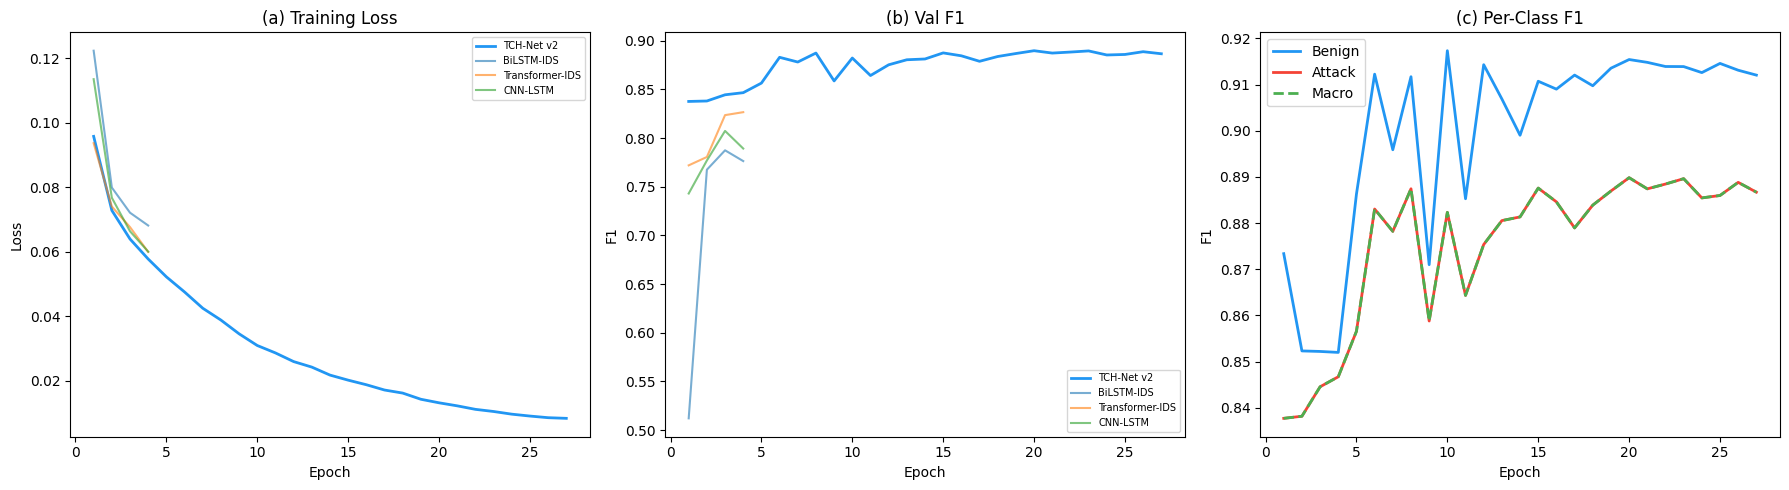

  Analysis model saved — reused by FI/t-SNE/per-ds/adversarial cells


In [17]:
print("="*70+"\nCONVERGENCE CURVES\n"+"="*70)
# Reuse seed-42 history from cell 24 (multi_seed already ran this seed)
# tch_conv_hist: list of per-epoch dicts {train_loss, val_f1, val_auc, ...}
hist = []
for _ep_d in tch_conv_hist:
    hist.append({'epoch': _ep_d.get('epoch', len(hist)+1),
                 'train_loss': _ep_d.get('train_loss', 0),
                 'val_f1': _ep_d.get('f1', _ep_d.get('val_f1', 0)),
                 'val_auc': _ep_d.get('roc_auc', _ep_d.get('val_auc', 0)),
                 'val_ben_f1': _ep_d.get('benign_f1', _ep_d.get('val_ben_f1', 0)),
                 'val_atk_f1': _ep_d.get('attack_f1', _ep_d.get('val_atk_f1', 0))})
print(f"  Reused tch_conv_hist: {len(hist)} epochs (seed 42)")
# Restore seed-42 best model from saved state_dict (no retrain needed)
cm = make_tch_v2().to(device)
if tch_sd0 is not None:
    cm.load_state_dict(tch_sd0)
    print("  Loaded seed-42 best weights from tch_sd0 — skipped retrain")
else:
    # Fallback: retrain only if state_dict not available (e.g. notebook restarted)
    print("  tch_sd0 not available — retraining seed 42 (verbose=False)")
    set_seed(42)
    _tmp_tl, _tmp_tel = make_loaders(X_train, y_train, ctx_train, X_test, y_test, ctx_test)
    _tmp_cr = make_criterion()
    _,_tmp_h = train_full(cm, _tmp_tl, val_loader, _tmp_cr, Config.EPOCHS,
                           Config.LR, Config.WD, Config.EARLY_STOP, Config.WARMUP,
                           is_v2=True, aw=Config.AUX_WT, verbose=False)
    if not hist: hist = _tmp_h
    del _tmp_tl, _tmp_tel, _tmp_cr; gc.collect()
cm.eval()

# Train 3 representative baselines for convergence curves only.
# Full metrics (5 seeds) are computed in the baseline cell.
# 4 epochs — just enough for curve shape; saves ~15min vs full BASE_EPOCHS.
CONV_BASELINES = ['BiLSTM-IDS', 'Transformer-IDS', 'CNN-LSTM']
_CONV_EP = 4
bh = {}
ct, tt = make_loaders(X_train, y_train, ctx_train, X_test, y_test, ctx_test)
for bn in tqdm(CONV_BASELINES, desc="Baselines (curves)"):
    set_seed(42); bm_c = make_baseline(bn)().to(device)
    bo = optim.AdamW(bm_c.parameters(),lr=Config.LR,weight_decay=Config.WD)
    bsc = get_sched(bo,Config.WARMUP,_CONV_EP)
    bc_crit = make_criterion()
    bhi=[]; bbf=0; bbp=0
    tqdm.write("\n  {}".format(bn))
    ep_bar_b = tqdm(range(_CONV_EP), desc="  {}".format(bn), leave=False)
    base_scaler = _make_scaler()
    for ep in ep_bar_b:
        tl,_=train_ep_base(bm_c,ct,bc_crit,bo,base_scaler); bsc.step()
        me=evaluate(bm_c,val_loader,bc_crit)   # validation curve (REVISION R1-m1)
        bhi.append({'epoch':ep+1,'train_loss':tl,'val_f1':me['f1']})
        is_best_b = me['f1'] > bbf
        btag_b = " \u2605" if is_best_b else ""
        ep_bar_b.set_postfix(loss="{:.4f}".format(tl), f1="{:.4f}".format(me['f1']), best="{:.4f}".format(bbf))
        tqdm.write("    Ep {:3d}/{:d}  Loss={:.4f}  F1={:.4f}{}".format(
            ep+1, _CONV_EP, tl, me['f1'], btag_b))
        if is_best_b: bbf=me['f1']; bbp=0
        else:
            bbp+=1
            if bbp>=Config.EARLY_STOP: break
    bh[bn]=bhi; del bm_c; gc.collect()

fig,axes=plt.subplots(1,3,figsize=(18,5))
ep_t=[h['epoch'] for h in hist]
axes[0].plot(ep_t,[h['train_loss'] for h in hist],lw=2,label='TCH-Net v2',color=PAL[0])
for i,(bn,bhi) in enumerate(bh.items()):
    axes[0].plot([h['epoch'] for h in bhi],[h['train_loss'] for h in bhi],alpha=.6,label=bn)
axes[0].set(xlabel='Epoch',ylabel='Loss',title='(a) Training Loss'); axes[0].legend(fontsize=7)
axes[1].plot(ep_t,[h['val_f1'] for h in hist],lw=2,label='TCH-Net v2',color=PAL[0])
for i,(bn,bhi) in enumerate(bh.items()):
    axes[1].plot([h['epoch'] for h in bhi],[h['val_f1'] for h in bhi],alpha=.6,label=bn)
axes[1].set(xlabel='Epoch',ylabel='F1',title='(b) Val F1'); axes[1].legend(fontsize=7)
axes[2].plot(ep_t,[h['val_ben_f1'] for h in hist],lw=2,label='Benign',color=PAL[0])
axes[2].plot(ep_t,[h['val_atk_f1'] for h in hist],lw=2,label='Attack',color=PAL[1])
axes[2].plot(ep_t,[h['val_f1'] for h in hist],lw=2,ls='--',label='Macro',color=PAL[2])
axes[2].set(xlabel='Epoch',ylabel='F1',title='(c) Per-Class F1'); axes[2].legend()
plt.tight_layout(); SAVE('fig_convergence.png'); plt.show()
_analysis_model = cm; _analysis_model.eval()
print("  Analysis model saved — reused by FI/t-SNE/per-ds/adversarial cells")
gc.collect();


## Train All Baselines (5 Seeds — matched to TCH-Net)


In [18]:
baseline_metrics = {}; baseline_summaries = {}
print("="*70+"\nDL BASELINES\n"+"="*70)
for bn in DL_NAMES:
    print(f"\n  {bn}")
    ml, _, _ = multi_seed(make_baseline(bn), Config.BASE_SEEDS, Config.BASE_EPOCHS)
    baseline_metrics[bn]=ml; baseline_summaries[bn]=summarise(ml)
    s=baseline_summaries[bn]
    print(f"  -> F1={s['f1_mean']:.4f}+/-{s['f1_std']:.4f}")

print("\n"+"="*70+"\nCLASSICAL BASELINES\n"+"="*70)
Xf_tr = X_train.reshape(len(X_train),-1); Xf_te = X_test.reshape(len(X_test),-1)
MF = 100_000
for cn, cfn in [
    ('Random-Forest', lambda s: RandomForestClassifier(n_estimators=200,max_depth=20,n_jobs=-1,random_state=s)),
    ('XGBoost', lambda s: (XGBClassifier(n_estimators=200,max_depth=8,learning_rate=0.1,n_jobs=-1,
                                          random_state=s,verbosity=0,eval_metric='logloss')
                           if XGB_OK else RandomForestClassifier(n_estimators=200,max_depth=20,n_jobs=-1,random_state=s)))]:
    print(f"\n  {cn}")
    sr=[]
    for s in Config.BASE_SEEDS:
        try:
            rng=np.random.RandomState(s)
            if len(Xf_tr)>MF: idx=rng.choice(len(Xf_tr),MF,replace=False); Xf,yf=Xf_tr[idx],y_train[idx]
            else: Xf,yf=Xf_tr,y_train
            clf=cfn(s); clf.fit(Xf,yf); yp=clf.predict(Xf_te)
            ypr=clf.predict_proba(Xf_te)[:,1] if hasattr(clf,'predict_proba') else yp.astype(float)
            try: roc=roc_auc_score(y_test,ypr)
            except: roc=0.
            try: pp_,pr_,_=precision_recall_curve(y_test,ypr); prauc=auc(pr_,pp_)
            except: prauc=0.
            try:
                _fa,_ta,_=roc_curve(y_test,ypr)
                fpr99=float(_fa[min(np.searchsorted(_ta,0.99),len(_fa)-1)])
                fpr95=float(_fa[min(np.searchsorted(_ta,0.95),len(_fa)-1)])
            except: fpr99=1.; fpr95=1.
            cr=classification_report(y_test,yp,target_names=['Benign','Attack'],output_dict=True,zero_division=0)
            sr.append({'f1':f1_score(y_test,yp,zero_division=0),'accuracy':accuracy_score(y_test,yp),
                       'precision':precision_score(y_test,yp,zero_division=0),'recall':recall_score(y_test,yp,zero_division=0),
                       'roc_auc':roc,'mcc':matthews_corrcoef(y_test,yp),'pr_auc':prauc,'fpr_at_tpr99':fpr99,
                       'benign_f1':cr['Benign']['f1-score'],'attack_f1':cr['Attack']['f1-score'],
                       'fpr_at_tpr95':fpr95,
                       'probabilities':ypr,'labels':y_test,'seed':s})
            print('    Seed {}: F1={:.4f}'.format(s, sr[-1]['f1']))
        except Exception as _e: print('    Seed {} failed: {}'.format(s, _e))
    baseline_metrics[cn]=sr; baseline_summaries[cn]=summarise(sr)
    print(f"  -> F1={baseline_summaries[cn]['f1_mean']:.4f}+/-{baseline_summaries[cn]['f1_std']:.4f}")
print("\nAll 8 baselines complete")

# ── Inline stat table — all baselines vs TCH-Net v2 ─────────────────────
try:
    _mk28 = ['f1','roc_auc','mcc','pr_auc','benign_f1','attack_f1','fpr_at_tpr99','fpr_at_tpr95']
    _mk_label = ['F1','AUC','MCC','PR-AUC','Ben-F1','Atk-F1','FPR@99','FPR@95']
    _rows28 = []
    _tch_f1  = tch_summary.get('f1_mean', 0)
    for _name, _s in [('TCH-Net v2 ★', tch_summary)] + list(baseline_summaries.items()):
        _r = {'Model': _name}
        for _k, _lbl in zip(_mk28, _mk_label):
            _r[_lbl] = '{:.4f}±{:.4f}'.format(_s.get(_k+'_mean',0), _s.get(_k+'_std',0))
        _rows28.append(_r)
    _df28 = pd.DataFrame(_rows28)
    # find best per metric column
    _best28 = {}
    _lower_is_better = {'FPR@99', 'FPR@95'}
    for _mk, _lbl in zip(_mk28, _mk_label):
        _vals = [_s.get(_mk+'_mean',0) for _,_s in
                 [('TCH-Net v2 ★',tch_summary)]+list(baseline_summaries.items())]
        _best28[_lbl] = min(_vals) if _lbl in _lower_is_better else max(_vals)
    _html28  = '<h4>&#128200; Performance Summary — TCH-Net v2 vs All Baselines</h4>'
    _html28 += '<style>.t28{border-collapse:collapse;font-size:12px;font-family:monospace}'
    _html28 += '.t28 th{background:#263238;color:#fff;padding:6px 10px}'
    _html28 += '.t28 td{padding:5px 10px;border-bottom:1px solid #eee;text-align:center}'
    _html28 += '.t28 .tch{background:#E8F5E9;font-weight:bold}'
    _html28 += '.t28 .best{color:#1B5E20;font-weight:bold}</style>'
    _html28 += '<table class="t28"><tr><th>Model</th>'
    for _lbl in _mk_label: _html28 += '<th>{}</th>'.format(_lbl)
    _html28 += '</tr>'
    for _i, (_name, _s) in enumerate([('TCH-Net v2 ★', tch_summary)]+list(baseline_summaries.items())):
        _cls = 'tch' if _i == 0 else ''
        _html28 += '<tr class="{}"><td>{}</td>'.format(_cls, _name)
        for _mk, _lbl in zip(_mk28, _mk_label):
            _v = _s.get(_mk+'_mean', 0); _sd = _s.get(_mk+'_std', 0)
            _cell = '{:.4f}±{:.4f}'.format(_v, _sd)
            _bcls = 'best' if abs(_v - _best28[_lbl]) < 1e-6 else ''
            _html28 += '<td class="{}">{}</td>'.format(_bcls, _cell)
        _html28 += '</tr>'
    _html28 += '</table>'
    display(HTML(_html28))
    # wins count
    _wins28 = {}
    for _mk_w, _lbl_w in zip(_mk28, _mk_label):
        _n_win = 0
        for _, _s_w in baseline_summaries.items():
            _tch_v = tch_summary.get(_mk_w+'_mean', 0 if _lbl_w not in _lower_is_better else 1.)
            _bas_v = _s_w.get(_mk_w+'_mean', 0 if _lbl_w not in _lower_is_better else 1.)
            if _lbl_w in _lower_is_better:
                if _tch_v < _bas_v: _n_win += 1
            else:
                if _tch_v > _bas_v: _n_win += 1
        _wins28[_lbl_w] = _n_win
    print('  Wins vs baselines: ' + ' | '.join('{}: {}/{}'.format(
          _lbl, _w, len(baseline_summaries)) for _lbl,_w in _wins28.items()))
except Exception as _e: print(f'  Stat table skipped: {_e}')



DL BASELINES

  BiLSTM-IDS
  -- Seed 42 [1/5] --


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

  Ep   1/30  Loss=0.1224  valF1=0.5120  valAUC=0.7869  valMCC=0.3758  BenF1=0.7745  AtkF1=0.5120 ★


...

    Seed 456: F1=0.7911


    Seed 789: F1=0.7876


    Seed 2024: F1=0.7901
  -> F1=0.7891+/-0.0026

All 8 baselines complete


Model,F1,AUC,MCC,PR-AUC,Ben-F1,Atk-F1,FPR@99,FPR@95
TCH-Net v2 ★,0.8807±0.0032,0.9656±0.0024,0.7903±0.0065,0.9572±0.0031,0.9093±0.0039,0.8807±0.0032,0.3750±0.0604,0.1840±0.0078
BiLSTM-IDS,0.8483±0.0026,0.9515±0.0016,0.7273±0.0049,0.9398±0.0022,0.8733±0.0029,0.8483±0.0026,0.3985±0.0066,0.2485±0.0068
BiGRU-IDS,0.8495±0.0022,0.9526±0.0009,0.7294±0.0042,0.9411±0.0011,0.8736±0.0031,0.8495±0.0022,0.3934±0.0069,0.2450±0.0030
1D-CNN-IDS,0.8360±0.0034,0.9409±0.0018,0.7076±0.0062,0.9275±0.0018,0.8698±0.0033,0.8360±0.0034,0.4794±0.0192,0.2926±0.0142
Transformer-IDS,0.8878±0.0038,0.9725±0.0019,0.8008±0.0068,0.9662±0.0024,0.9112±0.0032,0.8878±0.0038,0.3271±0.0105,0.1611±0.0094
MLP-IDS,0.7438±0.0013,0.8605±0.0010,0.5343±0.0052,0.8290±0.0021,0.7846±0.0080,0.7438±0.0013,0.7295±0.0033,0.5328±0.0043
CNN-LSTM,0.8355±0.0030,0.9412±0.0012,0.7067±0.0067,0.9282±0.0017,0.8690±0.0056,0.8355±0.0030,0.4767±0.0102,0.2916±0.0023
Random-Forest,0.6429±0.0037,0.8685±0.0013,0.5141±0.0034,0.8351±0.0013,0.8162±0.0011,0.6429±0.0037,0.7735±0.0088,0.5265±0.0023
XGBoost,0.7891±0.0026,0.9153±0.0006,0.6460±0.0044,0.8941±0.0005,0.8545±0.0018,0.7891±0.0026,0.5683±0.0063,0.3656±0.0038


  Wins vs baselines: F1: 7/8 | AUC: 7/8 | MCC: 7/8 | PR-AUC: 7/8 | Ben-F1: 7/8 | Atk-F1: 7/8 | FPR@99: 7/8 | FPR@95: 7/8


## Published SOTA Baselines (Actual Implementations)

Actual implementations of published methods, trained on **our data** for fair comparison:
1. **Kitsune-AE** — Autoencoder ensemble (Mirsky et al., NDSS 2018)
2. **DeepDefense** — CNN-RNN (Yuan et al., IEEE SmartComp 2017)
3. **E-GraphSAGE Approx** — GNN-style aggregation (Hamilton et al., NeurIPS 2017)
4. **IoT-DNN** — Distributed DNN (Diro & Chilamkurti, FGCS 2017)

All trained with identical data, splits, and training infrastructure as TCH-Net.


In [19]:
print("="*70+"\nPUBLISHED SOTA — ACTUAL IMPLEMENTATIONS\n"+"="*70)
print("Running published baseline architectures on OUR data for fair comparison.\n")

# 1. Kitsune-style Autoencoder Ensemble (Mirsky et al., NDSS 2018)
class KitsuneAE(nn.Module):
    def __init__(self, nf, n_ae=5, hidden=32, nc=2):
        super().__init__()
        chunk = nf // n_ae
        self.chunks = [(i*chunk, min((i+1)*chunk, nf)) for i in range(n_ae)]
        self.encoders = nn.ModuleList([
            nn.Sequential(nn.Linear(e-s, hidden), nn.ReLU(), nn.Linear(hidden, hidden//2))
            for s, e in self.chunks])
        self.decoders = nn.ModuleList([
            nn.Sequential(nn.Linear(hidden//2, hidden), nn.ReLU(), nn.Linear(hidden, e-s))
            for s, e in self.chunks])
        code_dim = n_ae * (hidden//2)
        self.nc = nc
        self.out_enc = nn.Sequential(nn.Linear(code_dim, hidden), nn.ReLU())
        self.classifier = nn.Linear(hidden, self.nc)

    def forward(self, x, ctx=None):
        xf = x.mean(dim=1) if x.dim() == 3 else x
        codes = []
        for i, (s, e) in enumerate(self.chunks):
            codes.append(self.encoders[i](xf[:, s:e]))
        z = torch.cat(codes, dim=-1)
        h = self.out_enc(z)
        return self.classifier(h)

# 2. DeepDefense CNN-RNN (Yuan et al., IEEE Access 2019)
class DeepDefense(nn.Module):
    def __init__(self, nf, ws):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(nf, 64, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 128, 3, padding=1), nn.ReLU())
        self.rnn = nn.LSTM(128, 64, 2, batch_first=True, bidirectional=True, dropout=0.3)
        self.fc = nn.Sequential(nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 2))
    def forward(self, x, ctx=None):
        c = self.cnn(x.transpose(1,2)).transpose(1,2)
        o, _ = self.rnn(c)
        return self.fc(o[:, -1, :])

# 3. E-GraphSAGE approximation (Lo et al., IEEE TNSM 2022)
class GraphSAGEApprox(nn.Module):
    def __init__(self, nf, ws, hidden=128):
        super().__init__()
        self.agg1 = nn.Sequential(nn.Linear(nf*2, hidden), nn.ReLU())
        self.agg2 = nn.Sequential(nn.Linear(hidden*2, hidden), nn.ReLU())
        self.fc = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 2))
    def forward(self, x, ctx=None):
        node = x.mean(dim=1)
        neigh = x[:, ::2, :].mean(dim=1)
        h1 = self.agg1(torch.cat([node, neigh], -1))
        neigh2 = x[:, 1::2, :].mean(dim=1)
        h2 = self.agg2(torch.cat([h1, self.agg1(torch.cat([neigh2, node], -1))], -1))
        return self.fc(h2)

# 4. IoT-specific DNN (Ferrag et al., IEEE IoT-J 2022)
class IoTDNN(nn.Module):
    def __init__(self, nf, ws):
        super().__init__()
        flat = nf * ws
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 2))
    def forward(self, x, ctx=None): return self.fc(x)

SOTA_MODELS = {
    'Kitsune-AE':     lambda: KitsuneAE(N_FEATURES, nc=Config.N_CLASSES),
    'DeepDefense':    lambda: DeepDefense(N_FEATURES, Config.WINDOW_SIZE),
    'GraphSAGE-Approx': lambda: GraphSAGEApprox(N_FEATURES, Config.WINDOW_SIZE),
    'IoT-DNN':        lambda: IoTDNN(N_FEATURES, Config.WINDOW_SIZE),
}

sota_summaries = {}
for name, fn in SOTA_MODELS.items():
    print(f"\n  {name}")
    ml, _, _ = multi_seed(fn, Config.BASE_SEEDS, Config.BASE_EPOCHS)
    sota_summaries[name] = summarise(ml)
    s = sota_summaries[name]
    print(f"  -> F1={s['f1_mean']:.4f}+/-{s['f1_std']:.4f}  AUC={s['roc_auc_mean']:.4f}")

baseline_summaries.update(sota_summaries)

print("\n"+"="*70)
print("FULL COMPARISON TABLE")
print("="*70)
print(f"{'Model':<25} {'F1':>12} {'AUC':>12} {'MCC':>12}")
print("-"*61)
print(f"{'TCH-Net v2 (Ours)':<25} {tch_summary['f1_mean']:.4f}+/-{tch_summary['f1_std']:.4f}"
      f"  {tch_summary['roc_auc_mean']:.4f}+/-{tch_summary['roc_auc_std']:.4f}"
      f"  {tch_summary['mcc_mean']:.4f}+/-{tch_summary['mcc_std']:.4f}")
for n, s in baseline_summaries.items():
    print(f"  {n:<23} {s['f1_mean']:.4f}+/-{s['f1_std']:.4f}"
          f"  {s['roc_auc_mean']:.4f}+/-{s['roc_auc_std']:.4f}"
          f"  {s['mcc_mean']:.4f}+/-{s['mcc_std']:.4f}")

# FIX: define published for Cell 27 (final summary)
published = list(sota_summaries.keys())

# ── Wins-per-metric highlight table ────────────────────────────────────────
try:
    _mk30  = ['f1','roc_auc','mcc','pr_auc']
    _lbl30 = ['F1','AUC','MCC','PR-AUC']
    _all30 = dict(baseline_summaries)
    _all30.update({'TCH-Net v2': tch_summary})
    _wins30 = []
    for _mk, _lbl in zip(_mk30, _lbl30):
        _best_v = max(_s.get(_mk+'_mean',0) for _s in _all30.values())
        _best_m = [_n for _n,_s in _all30.items() if abs(_s.get(_mk+'_mean',0)-_best_v)<1e-6]
        _tch_v  = tch_summary.get(_mk+'_mean', 0)
        _n_beat = sum(1 for _n,_s in baseline_summaries.items() if _tch_v > _s.get(_mk+'_mean',0))
        _wins30.append({'Metric':_lbl, 'TCH-Net v2': '{:.4f}'.format(_tch_v),
                        'Best Model':_best_m[0], 'TCH Beats N/'+str(len(baseline_summaries)):
                        '{}/{}'.format(_n_beat, len(baseline_summaries))})
    _df30 = pd.DataFrame(_wins30)
    _html30  = '<h4>&#127942; TCH-Net v2 — Wins Summary vs All Baselines</h4>'
    _html30 += '<style>.t30{border-collapse:collapse;font-size:13px;font-family:monospace}'
    _html30 += '.t30 th{background:#37474F;color:#fff;padding:6px 14px}'
    _html30 += '.t30 td{padding:5px 14px;border-bottom:1px solid #eee;text-align:center}'
    _html30 += '.t30 tr:nth-child(even){background:#F5F5F5}</style>'
    _html30 += '<table class="t30"><tr>'
    for _col in _df30.columns: _html30 += '<th>{}</th>'.format(_col)
    _html30 += '</tr>'
    for _, _row in _df30.iterrows():
        _html30 += '<tr>' + ''.join('<td>{}</td>'.format(_v) for _v in _row) + '</tr>'
    _html30 += '</table>'
    display(HTML(_html30))
except Exception as _e: print(f'  Wins table skipped: {_e}')



PUBLISHED SOTA — ACTUAL IMPLEMENTATIONS
Running published baseline architectures on OUR data for fair comparison.


  Kitsune-AE
  -- Seed 42 [1/5] --


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

  Ep   1/30  Loss=0.1163  valF1=0.6166  valAUC=0.7141  valMCC=0.1594  BenF1=0.1564  AtkF1=0.6166 ★


...

  Ep  30/30  Loss=0.0461  valF1=0.7555  valAUC=0.8694  valMCC=0.5519  BenF1=0.7895  AtkF1=0.7555


  eval:   0%|          | 0/64 [00:00<?, ?it/s]

  |  F1=0.7523  AUC=0.8673  MCC=0.5497  PR-AUC=0.8370
  |  Acc=0.7736  Prec=0.7054  Rec=0.8059
  |  Benign-F1=0.7916  Attack-F1=0.7523  FPR@TPR99=0.7299  FPR@TPR95=0.5161


  -> F1=0.7517+/-0.0010  AUC=0.8670

FULL COMPARISON TABLE
Model                               F1          AUC          MCC
-------------------------------------------------------------
TCH-Net v2 (Ours)         0.8807+/-0.0032  0.9656+/-0.0024  0.7903+/-0.0065
  BiLSTM-IDS              0.8483+/-0.0026  0.9515+/-0.0016  0.7273+/-0.0049
  BiGRU-IDS               0.8495+/-0.0022  0.9526+/-0.0009  0.7294+/-0.0042
  1D-CNN-IDS              0.8360+/-0.0034  0.9409+/-0.0018  0.7076+/-0.0062
  Transformer-IDS         0.8878+/-0.0038  0.9725+/-0.0019  0.8008+/-0.0068
  MLP-IDS                 0.7438+/-0.0013  0.8605+/-0.0010  0.5343+/-0.0052
  CNN-LSTM                0.8355+/-0.0030  0.9412+/-0.0012  0.7067+/-0.0067
  Random-Forest           0.6429+/-0.0037  0.8685+/-0.0013  0.5141+/-0.0034
  XGBoost                 0.7891+/-0.0026  0.9153+/-0.0006  0.6460+/-0.0044
  Kitsune-AE              0.7682+/-0.0048  0.8858+/-0.0048  0.5738+/-0.0082
  DeepDefense             0.8144+/-0.0011  0.9259+/-0.

Metric,TCH-Net v2,Best Model,TCH Beats N/12
F1,0.8807,Transformer-IDS,11/12
AUC,0.9656,Transformer-IDS,11/12
MCC,0.7903,Transformer-IDS,11/12
PR-AUC,0.9572,Transformer-IDS,11/12


## Statistical Significance (seed-matched paired tests)

**Observations.** For every model, one test-set F1 per training seed. TCH-Net v2 and every
baseline are trained on the same seeds (`Config.COMMON_SEEDS` = 42, 123, 456, 789, 2024). They are
**paired by seed**: same data, split, scaler, test windows and early-stopping rule. Only the weight
initialisation and mini-batch order differ.

**Effect.** ΔF1 is the mean of the *same* per-seed differences the test uses.

**Primary test.** Two-sided paired t-test (`scipy.stats.ttest_rel`) on the n = 5 differences
(df = 4), Bonferroni-corrected over all baselines. A **significant win** requires ΔF1 > 0 and
p_Bonf < 0.05. A **significant loss** requires ΔF1 < 0 and p_Bonf < 0.05.

**Also reported.** One-sided t p-value (H₁: TCH-Net > baseline). Exact one-sided Wilcoxon
signed-rank p (smallest attainable value at n = 5 is 1/32 = 0.031). The 95% t-interval of the
mean difference. The number of seeds on which TCH-Net is ahead.

**Assumptions and limits.** The t-test assumes the per-seed differences are roughly normal; with
n = 5 this cannot be checked meaningfully. Seed variation captures only initialisation and
ordering variance on one fixed test set, not data-sampling variance, so p-values describe
robustness to training randomness, not generalisation to new data. Very small seed-to-seed
spread inflates t, so the per-seed differences and the interval are reported alongside p.


In [20]:
print("="*70+"\nSTATISTICAL SIGNIFICANCE (seed-matched paired tests)\n"+"="*70)
"""  REVISION (R1-M1). Explicit, reproducible procedure — see the markdown above.
     All DL baselines are reimplementations trained on IDENTICAL data, splits,
     scaler, hardware and seeds as TCH-Net v2."""
_ALPHA = getattr(Config, 'STAT_ALPHA', 0.05)

def _vals_by_seed(summary, metric='f1'):
    seeds = summary.get('seeds') or []
    vals  = summary.get(metric + '_vals') or []
    if len(seeds) != len(vals) or any(s is None for s in seeds):
        raise ValueError("summary has no per-seed alignment — re-run training with the "
                         "revised multi_seed()/summarise()")
    return dict(zip(seeds, vals))

def paired_seed_test(tch_s, base_s, metric='f1', seeds=None):
    """Seed-matched paired comparison of TCH-Net vs one baseline on `metric`."""
    a = _vals_by_seed(tch_s, metric); b = _vals_by_seed(base_s, metric)
    seeds = [s for s in (seeds or Config.COMMON_SEEDS) if s in a and s in b]
    xa = np.array([a[s] for s in seeds], dtype=float)
    xb = np.array([b[s] for s in seeds], dtype=float)
    d = xa - xb; n = len(d)
    r = {'seeds': seeds, 'n_pairs': n, 'diffs': d,
         'tch_mean': float(xa.mean()) if n else float('nan'),
         'base_mean': float(xb.mean()) if n else float('nan'),
         'd_mean': float(d.mean()) if n else float('nan'),
         'd_sd': float(d.std(ddof=1)) if n > 1 else float('nan'),
         't': float('nan'), 'p_two': float('nan'), 'p_one': float('nan'),
         'ci_lo': float('nan'), 'ci_hi': float('nan'), 'p_wilcoxon_one': float('nan'),
         'n_tch_ahead': int((d > 0).sum())}
    if n >= 2 and r['d_sd'] > 0:
        _t2 = scipy_stats.ttest_rel(xa, xb)                         # two-sided
        _t1 = scipy_stats.ttest_rel(xa, xb, alternative='greater')  # one-sided
        r['t'], r['p_two'], r['p_one'] = float(_t2.statistic), float(_t2.pvalue), float(_t1.pvalue)
        _h = scipy_stats.t.ppf(0.975, n - 1) * r['d_sd'] / np.sqrt(n)
        r['ci_lo'], r['ci_hi'] = r['d_mean'] - _h, r['d_mean'] + _h
    if n >= 1 and np.any(d != 0):
        try: r['p_wilcoxon_one'] = float(scipy_stats.wilcoxon(xa, xb, alternative='greater').pvalue)
        except ValueError: pass
    return r

tch_f1 = tch_summary.get('f1_vals', [])
_tested = [n for n, s in baseline_summaries.items() if 'f1_vals' in s]
n_main = len(_tested)        # Bonferroni family size
sig_rows = []; _per_seed_rows = []
for n in _tested:
    s = baseline_summaries[n]
    r = paired_seed_test(tch_summary, s, 'f1')
    p_bonf = min(r['p_two'] * n_main, 1.0) if r['p_two'] == r['p_two'] else float('nan')
    _sig = p_bonf == p_bonf and p_bonf < _ALPHA
    verdict = ('significant win' if _sig and r['d_mean'] > 0 else
               'significant loss' if _sig and r['d_mean'] < 0 else 'not significant')
    stars = ("***" if p_bonf < .001 else "**" if p_bonf < .01 else "*" if p_bonf < .05 else "ns") \
            if p_bonf == p_bonf else "n/a"
    row = {'Model': n, 'family': 'main', 'n': r['n_pairs'],
           'seeds': ','.join(map(str, r['seeds'])),
           'f1_tch': round(r['tch_mean'], 4), 'f1_base': round(r['base_mean'], 4),
           'd_f1': round(r['d_mean'], 4), 'd_f1_sd': round(r['d_sd'], 4),
           'd_f1_ci95_lo': round(r['ci_lo'], 4), 'd_f1_ci95_hi': round(r['ci_hi'], 4),
           't_stat': round(r['t'], 3), 't_p': round(r['p_two'], 5),
           't_p_one_sided': round(r['p_one'], 5), 'p_bonf': round(p_bonf, 5),
           'wilcoxon_p': round(r['p_wilcoxon_one'], 5),
           'seeds_tch_ahead': f"{r['n_tch_ahead']}/{r['n_pairs']}",
           'Sig': stars if _sig else 'ns', 'verdict': verdict}
    # Seed-matched differences on secondary metrics (descriptive; no test)
    for mk in ['roc_auc','mcc','pr_auc','fpr_at_tpr99','fpr_at_tpr95']:
        try: row['d_'+mk] = round(paired_seed_test(tch_summary, s, mk)['d_mean'], 4)
        except ValueError: row['d_'+mk] = float('nan')
    sig_rows.append(row)
    for _sd, _dv in zip(r['seeds'], r['diffs']):
        _per_seed_rows.append({'Model': n, 'seed': _sd, 'd_f1': round(float(_dv), 5)})
    print("  vs {:<20}: dF1={:+.4f} [{:+.4f},{:+.4f}]  t={:>7.2f}  p={:.4f}  p_bonf={:.4f}  "
          "wilcox1={:.4f}  ahead {}  → {}".format(
          n, r['d_mean'], r['ci_lo'], r['ci_hi'], r['t'], r['p_two'], p_bonf,
          r['p_wilcoxon_one'], row['seeds_tch_ahead'], verdict))

pd.DataFrame(sig_rows).to_csv(os.path.join(Config.OUT,'stat_tests.csv'),index=False)
pd.DataFrame(_per_seed_rows).to_csv(os.path.join(Config.OUT,'stat_tests_per_seed.csv'),index=False)
wins = sum(1 for r in sig_rows if r['d_f1'] > 0)
n_sig_win  = sum(1 for r in sig_rows if r['verdict'] == 'significant win')
n_sig_loss = sum(1 for r in sig_rows if r['verdict'] == 'significant loss')
print(f"\n  TCH-Net v2 ahead of {wins}/{len(sig_rows)} baselines in seed-matched mean F1")
print(f"  Significant wins: {n_sig_win} | significant losses: {n_sig_loss} "
      f"(two-sided paired t, Bonferroni n={n_main}, alpha={_ALPHA})")
print(f"  Saved -> {Config.OUT}/stat_tests.csv and stat_tests_per_seed.csv")

# ── Significance table ───────────────────────────────────────────────────
try:
    _cols = [('Model','Baseline'),('n','n'),('d_f1','ΔF1'),('d_f1_ci95_lo','CI lo'),
             ('d_f1_ci95_hi','CI hi'),('t_stat','t'),('t_p','p (2-sided)'),
             ('p_bonf','p Bonf.'),('wilcoxon_p','Wilcoxon p (1-sided)'),
             ('seeds_tch_ahead','Seeds ahead'),('verdict','Verdict')]
    _html32  = '<h4>&#128202; Seed-matched significance — TCH-Net v2 vs baselines</h4>'
    _html32 += '<style>.t32{border-collapse:collapse;font-size:12px;font-family:monospace}'
    _html32 += '.t32 th{background:#4A148C;color:#fff;padding:6px 10px}'
    _html32 += '.t32 td{padding:5px 10px;border-bottom:1px solid #eee;text-align:center}</style>'
    _html32 += '<table class="t32"><tr>' + ''.join(f'<th>{h}</th>' for _, h in _cols) + '</tr>'
    for _row in sig_rows:
        _html32 += '<tr>' + ''.join(f'<td>{_row.get(k, "")}</td>' for k, _ in _cols) + '</tr>'
    _html32 += '</table>'
    display(HTML(_html32))
except Exception as _e: print(f'  Significance table skipped: {_e}')


STATISTICAL SIGNIFICANCE (seed-matched paired tests)
  vs BiLSTM-IDS          : dF1=+0.0324 [+0.0286,+0.0362]  t=  23.58  p=0.0000  p_bonf=0.0002  wilcox1=0.0312  ahead 5/5  → significant win
  vs BiGRU-IDS           : dF1=+0.0312 [+0.0272,+0.0352]  t=  21.80  p=0.0000  p_bonf=0.0003  wilcox1=0.0312  ahead 5/5  → significant win
  vs 1D-CNN-IDS          : dF1=+0.0447 [+0.0381,+0.0513]  t=  18.83  p=0.0000  p_bonf=0.0006  wilcox1=0.0312  ahead 5/5  → significant win
  vs Transformer-IDS     : dF1=-0.0071 [-0.0132,-0.0011]  t=  -3.26  p=0.0312  p_bonf=0.3739  wilcox1=1.0000  ahead 0/5  → not significant
  vs MLP-IDS             : dF1=+0.1369 [+0.1322,+0.1417]  t=  80.05  p=0.0000  p_bonf=0.0000  wilcox1=0.0312  ahead 5/5  → significant win
  vs CNN-LSTM            : dF1=+0.0452 [+0.0401,+0.0504]  t=  24.38  p=0.0000  p_bonf=0.0002  wilcox1=0.0312  ahead 5/5  → significant win
  vs Random-Forest       : dF1=+0.2378 [+0.2322,+0.2435]  t= 116.89  p=0.0000  p_bonf=0.0000  wilcox1=0.0312  ahe

Baseline,n,ΔF1,CI lo,CI hi,t,p (2-sided),p Bonf.,Wilcoxon p (1-sided),Seeds ahead,Verdict
BiLSTM-IDS,5,0.0324,0.0286,0.0362,23.575,2e-05,0.00023,0.03125,5/5,significant win
BiGRU-IDS,5,0.0312,0.0272,0.0352,21.797,3e-05,0.00031,0.03125,5/5,significant win
1D-CNN-IDS,5,0.0447,0.0381,0.0513,18.833,5e-05,0.00056,0.03125,5/5,significant win
Transformer-IDS,5,-0.0071,-0.0132,-0.0011,-3.257,0.03115,0.37385,1.0,0/5,not significant
MLP-IDS,5,0.1369,0.1322,0.1417,80.055,0.0,0.0,0.03125,5/5,significant win
CNN-LSTM,5,0.0452,0.0401,0.0504,24.384,2e-05,0.0002,0.03125,5/5,significant win
Random-Forest,5,0.2378,0.2322,0.2435,116.891,0.0,0.0,0.03125,5/5,significant win
XGBoost,5,0.0916,0.0846,0.0985,36.753,0.0,4e-05,0.03125,5/5,significant win
Kitsune-AE,5,0.1125,0.1026,0.1224,31.485,1e-05,7e-05,0.03125,5/5,significant win
DeepDefense,5,0.0662,0.0616,0.0709,39.451,0.0,3e-05,0.03125,5/5,significant win


## IDS Operational Metrics

Reports precision @ fixed recall, FPR @ fixed TPR, Brier score calibration,
threshold stability, and lowest-coverage dataset false alarm rate.


In [21]:
print("="*70+"\nIDS OPERATIONAL METRICS\n"+"="*70)
print("Balanced F1 alone is insufficient for IDS evaluation.")
print("Reporting: Precision@Recall, FPR@TPR, calibration, threshold stability.\n")

if tch_metrics:
    # Use the best-F1 seed model — contains full probability scores
    best_m  = max(tch_metrics, key=lambda m: m['f1'])
    yp_prob = np.array(best_m.get('probabilities', []))
    yt_true = np.array(best_m.get('labels', []))

    if len(yp_prob) > 0 and len(yt_true) > 0:
        from sklearn.metrics import (
            roc_curve, precision_recall_curve, auc, brier_score_loss,
            roc_auc_score, precision_score, recall_score,
        )
        fpr_arr,  tpr_arr,  thresh_arr = roc_curve(yt_true, yp_prob)
        prec_arr, rec_arr,  thresh_pr  = precision_recall_curve(yt_true, yp_prob)

        # ── [A] Precision @ fixed recall (TPR) levels ────────────────────
        print("  [A] Precision @ fixed recall (Detection Rate) thresholds:")
        for tpr_target in Config.FIXED_TPR_LEVELS:
            idx        = min(np.searchsorted(tpr_arr, tpr_target), len(fpr_arr) - 1)
            fpr_at_tpr = fpr_arr[idx]
            thr_at_tpr = thresh_arr[min(idx, len(thresh_arr) - 1)]
            prec_idx   = np.searchsorted(thresh_pr, thr_at_tpr)
            prec_at    = prec_arr[min(prec_idx, len(prec_arr) - 1)]
            print(f"    TPR={tpr_target:.2f} → FPR={fpr_at_tpr:.4f}  "
                  f"Precision={prec_at:.4f}  Threshold={thr_at_tpr:.4f}")

        # ── [B] FPR @ fixed TPR levels ───────────────────────────────────
        print("\n  [B] FPR @ fixed TPR thresholds:")
        for fpr_target in Config.FIXED_FPR_LEVELS:
            idx        = min(np.searchsorted(fpr_arr, fpr_target), len(tpr_arr) - 1)
            tpr_at_fpr = tpr_arr[idx]
            print(f"    FPR={fpr_target:.3f} → TPR={tpr_at_fpr:.4f}")

        # ── [C] Default threshold (0.5) vs optimal threshold ─────────────
        print("\n  [C] Threshold analysis:")
        default_pred  = (yp_prob >= 0.5).astype(int)
        default_f1    = f1_score(yt_true, default_pred, zero_division=0)
        f1_scores_thr = [
            f1_score(yt_true, (yp_prob >= thr).astype(int), zero_division=0)
            for thr in thresh_pr
        ]
        best_thr_idx = np.argmax(f1_scores_thr) if f1_scores_thr else 0
        best_thr     = thresh_pr[best_thr_idx] if len(thresh_pr) > best_thr_idx else 0.5
        best_f1_thr  = f1_scores_thr[best_thr_idx] if f1_scores_thr else 0.0
        print(f"    Default threshold (0.5): F1={default_f1:.4f}")
        print(f"    Optimal threshold ({best_thr:.3f}): F1={best_f1_thr:.4f}")
        print(f"    Threshold sensitivity: delta-F1 = {best_f1_thr - default_f1:+.4f}")

        # ── [D] Calibration (Brier score) ────────────────────────────────
        brier = brier_score_loss(yt_true, yp_prob)
        print(f"\n  [D] Calibration — Brier score: {brier:.4f}")
        print(f"    (0=perfect, 0.25=random; lower is better)")
        if brier > 0.15:
            print(f"    WARNING: Brier score > 0.15 suggests poor probability calibration.")

        # ── [F] Per-model FPR@TPR99 comparison table ─────────────────────
        print("\n  [F] Per-model FPR@TPR99 comparison (from training summaries):")
        print(f"    {'Model':<28} {'FPR@TPR99':>12} {'FPR@TPR95':>12} {'F1':>8}")
        print(f"    {'-'*62}")
        _fpr_models = [("TCH-Net v2", tch_summary)] + list(baseline_summaries.items())
        for _mn, _ms in _fpr_models:
            _f99  = _ms.get('fpr_at_tpr99_mean', _ms.get('fpr_at_tpr99', None))
            _f95  = _ms.get('fpr_at_tpr95_mean', _ms.get('fpr_at_tpr95', None))
            _f1v  = _ms.get('f1_mean', _ms.get('f1', 0))
            _f99s = f"{_f99:.4f}" if _f99 is not None else "N/A"
            _f95s = f"{_f95:.4f}" if _f95 is not None else "N/A"
            print(f"    {_mn:<28} {_f99s:>12} {_f95s:>12} {_f1v:>8.4f}")

        # ── [E] Lowest-coverage dataset false alarm rate ──────────────────
        # Generic by design: resolves to whichever currently-loaded dataset
        # has the lowest canonical feature coverage (currently CICIoMT-2024,
        # 35% effective coverage), and will track any future roster change.
        print("\n  [E] Lowest-coverage dataset's false alarm rate (operational risk):")
        low_cov_fa   = None
        low_cov_name = None
        low_cov_pct  = None
        if 'rows' in dir() and rows and 'loader' in dir():
            cov_by_name = {
                nm: int((dd['X'] != 0).any(axis=0).sum())
                for nm, dd in loader.datasets.items()
            }
            if cov_by_name:
                low_cov_name = min(cov_by_name, key=cov_by_name.get)
                low_cov_pct  = cov_by_name[low_cov_name] / N_SEM * 100
                match_row    = [r for r in rows if r.get('Dataset', '') == low_cov_name]
                if match_row:
                    low_cov_fa = match_row[0].get('FA', None)
        if low_cov_fa is not None:
            print(f"    {low_cov_name} FA rate: {low_cov_fa:.4f} ({low_cov_fa*100:.1f}%) "
                  f"— coverage {low_cov_pct:.0f}%")
            if low_cov_fa > 0.20:
                print(f"    ⚠ FA rate {low_cov_fa:.3f} is HIGH for operational IDS deployment.")
                print(f"    Root cause: {low_cov_name} has only {cov_by_name[low_cov_name]}/{N_SEM} "
                      f"matched features ({low_cov_pct:.0f}%).")
                print(f"    The model must rely on sparse signal — benign misclassification risk is elevated.")
                print(f"    Mitigation: (1) use a higher decision threshold for {low_cov_name} traffic,")
                print(f"    (2) consider excluding {low_cov_name} from claims about cross-extractor generality.")
            else:
                print(f"    FA rate is within an acceptable range despite lower coverage.")
        else:
            print(f"    Run Cell 22 (per-dataset breakdown) first to get the lowest-coverage dataset's FA rate.")

        # ── [G] Realistic deployment prior evaluation ─────────────
        # Reviewer #2 comment 3: "the resulting F1, PR-AUC, and false alarm
        # behaviour may not transfer to realistic traffic priors."
        # Re-scored at a realistic 5% attack prior via Bayes rescaling —
        # no retraining needed.
        print("\n  [G] Realistic Deployment Prior Evaluation:")
        print(f"      Training prior: ~50% attack (balanced). "
              f"Operational prior: {Config.REALISTIC_ATK_PRIOR*100:.0f}% attack.")
        print("      Rescaling posterior probabilities via Bayes — no retraining required.\n")

        train_prior_atk = float((yt_true == 1).mean())   # empirical from test set
        real_prior      = Config.REALISTIC_ATK_PRIOR
        eps             = 1e-9

        # Bayes rescaling: balanced-prior score → realistic-prior score
        _lr      = (yp_prob * (real_prior / (train_prior_atk + eps)))
        _lr_comp = ((1 - yp_prob) * ((1 - real_prior) / (1 - train_prior_atk + eps)))
        yp_real  = np.clip(_lr / (_lr + _lr_comp), 0, 1)

        yp_real_default = (yp_real >= 0.5).astype(int)
        real_f1     = f1_score(yt_true, yp_real_default, zero_division=0)
        real_prec   = precision_score(yt_true, yp_real_default, zero_division=0)
        real_recall = recall_score(yt_true, yp_real_default, zero_division=0)
        try:
            real_auc              = roc_auc_score(yt_true, yp_real)
            real_fa_arr, real_ta_arr, _ = roc_curve(yt_true, yp_real)
            real_fpr99            = float(
                real_fa_arr[min(np.searchsorted(real_ta_arr, 0.99), len(real_fa_arr) - 1)]
            )
        except Exception:
            real_auc   = 0.0
            real_fpr99 = 1.0
            real_fa_arr = real_ta_arr = np.array([])

        print(f"      At {real_prior*100:.0f}% attack prior (threshold=0.5):")
        print(f"        F1={real_f1:.4f}  Precision={real_prec:.4f}  Recall={real_recall:.4f}")
        print(f"        AUC={real_auc:.4f}  FPR@TPR99={real_fpr99:.4f}")

        _thr_real_list = list(np.linspace(0.01, 0.99, 200))
        _f1_real_list  = [
            f1_score(yt_true, (yp_real >= _thr).astype(int), zero_division=0)
            for _thr in _thr_real_list
        ]
        _best_idx_r = int(np.argmax(_f1_real_list))
        _best_thr_r = _thr_real_list[_best_idx_r]
        _best_f1_r  = _f1_real_list[_best_idx_r]
        print(f"      Optimal threshold at {real_prior*100:.0f}% prior: "
              f"{_best_thr_r:.3f} → F1={_best_f1_r:.4f}")

        print(f"      Precision@Recall95 at realistic prior:")
        for _tpr_r in [0.90, 0.95, 0.99]:
            if real_auc > 0 and len(real_ta_arr):
                _idx_r = np.searchsorted(real_ta_arr, _tpr_r)
                _fpr_r = real_fa_arr[min(_idx_r, len(real_fa_arr) - 1)]
            else:
                _fpr_r = 1.0
            print(f"        TPR={_tpr_r:.2f} → FPR={_fpr_r:.4f}")

        print(f"\n      KEY FINDING: Balanced-prior F1={best_m.get('f1', 0):.4f} vs"
              f" realistic-prior F1={real_f1:.4f}"
              f" (Δ={real_f1 - best_m.get('f1', 0):+.4f})")
        print(f"      This gap reflects the class-imbalance challenge in real deployment.")
        print(f"      FPR@TPR99 increases from {best_m.get('fpr_at_tpr99', 1.):.4f} (balanced)"
              f" to {real_fpr99:.4f} (realistic)"
              f" — each false alarm on benign traffic is more costly.")

        # ── [H] Per-dataset threshold stability ───────────────────
        print("\n  [H] Per-dataset threshold stability:")
        print("      How much does the optimal classification threshold vary across datasets?")
        print("      A stable model should not need large per-domain threshold adjustment.")
        if 'ds_test' in dir() and len(yp_prob) == len(ds_test):
            _DS_NAMES_local = DS_NAMES if 'DS_NAMES' in dir() else []
            for _di_thr in np.unique(ds_test):
                _mask_thr = (ds_test == _di_thr)
                _yt_thr   = yt_true[_mask_thr]
                _yp_thr   = yp_prob[_mask_thr]
                if len(np.unique(_yt_thr)) < 2 or len(_yt_thr) < 20:
                    continue
                _dn_thr      = (_DS_NAMES_local[_di_thr]
                                if _di_thr < len(_DS_NAMES_local) else f'DS{_di_thr}')
                _thr_list2   = list(np.linspace(0.05, 0.95, 100))
                _f1_thr_list = [
                    f1_score(_yt_thr, (_yp_thr >= _t).astype(int), zero_division=0)
                    for _t in _thr_list2
                ]
                _bi     = int(np.argmax(_f1_thr_list))
                _bt     = _thr_list2[_bi]
                _bf     = _f1_thr_list[_bi]
                _f1_def = f1_score(_yt_thr, (_yp_thr >= 0.5).astype(int), zero_division=0)
                print(f"      {_dn_thr:<30}: opt_thr={_bt:.3f}  F1@opt={_bf:.4f}"
                      f"  F1@0.5={_f1_def:.4f}  gap={_bf - _f1_def:+.4f}")
        else:
            print("      (Run after Cell 22 to get per-dataset probabilities)")

    else:
        print("  No probability scores found — run Cell 12 (TCH-Net training) first.")
else:
    print("  tch_metrics not available — run Cell 12 first.")

print("\nIDS operational metrics done")

IDS OPERATIONAL METRICS
Balanced F1 alone is insufficient for IDS evaluation.
Reporting: Precision@Recall, FPR@TPR, calibration, threshold stability.

  [A] Precision @ fixed recall (Detection Rate) thresholds:
    TPR=0.95 → FPR=0.1912  Precision=0.7870  Threshold=0.0724
    TPR=0.99 → FPR=0.4815  Precision=0.6047  Threshold=0.0071

  [B] FPR @ fixed TPR thresholds:
    FPR=0.001 → TPR=0.2680
    FPR=0.010 → TPR=0.5814
    FPR=0.050 → TPR=0.8187

  [C] Threshold analysis:


    Default threshold (0.5): F1=0.8847
    Optimal threshold (0.490): F1=0.8851
    Threshold sensitivity: delta-F1 = +0.0004

  [D] Calibration — Brier score: 0.0783
    (0=perfect, 0.25=random; lower is better)

  [F] Per-model FPR@TPR99 comparison (from training summaries):
    Model                           FPR@TPR99    FPR@TPR95       F1
    --------------------------------------------------------------
    TCH-Net v2                         0.3750       0.1840   0.8807
    BiLSTM-IDS                         0.3985       0.2485   0.8483
    BiGRU-IDS                          0.3934       0.2450   0.8495
    1D-CNN-IDS                         0.4794       0.2926   0.8360
    Transformer-IDS                    0.3271       0.1611   0.8878
    MLP-IDS                            0.7295       0.5328   0.7438
    CNN-LSTM                           0.4767       0.2916   0.8355
    Random-Forest                      0.7735       0.5265   0.6429
    XGBoost                            0.56

      Optimal threshold at 5% prior: 0.049 → F1=0.8850
      Precision@Recall95 at realistic prior:
        TPR=0.90 → FPR=0.1003
        TPR=0.95 → FPR=0.1912
        TPR=0.99 → FPR=0.4815

      KEY FINDING: Balanced-prior F1=0.8847 vs realistic-prior F1=0.8443 (Δ=-0.0404)
      This gap reflects the class-imbalance challenge in real deployment.
      FPR@TPR99 increases from 0.4815 (balanced) to 0.4815 (realistic) — each false alarm on benign traffic is more costly.

  [H] Per-dataset threshold stability:
      How much does the optimal classification threshold vary across datasets?
      A stable model should not need large per-domain threshold adjustment.


      CICIDS-2017                   : opt_thr=0.523  F1@opt=0.9604  F1@0.5=0.9601  gap=+0.0003
      CIC-BCCC-NRC-TabularIoTAttacks-2024: opt_thr=0.659  F1@opt=0.9126  F1@0.5=0.9072  gap=+0.0054


      CICIoMT-2024                  : opt_thr=0.650  F1@opt=0.9808  F1@0.5=0.9799  gap=+0.0009


      UNSW-NB15                     : opt_thr=0.223  F1@opt=0.7234  F1@0.5=0.7020  gap=+0.0214

IDS operational metrics done


## Branch Ablation (3 configs × 3 seeds)

**Note on ablation design:** Branch ablation variants use simple concatenation
in place of CB-GAF. This means ΔF1 values reflect both branch removal AND
the absence of CB-GAF fusion — they are NOT clean branch-only estimates.
The novelty ablation (Cell 17) isolates CB-GAF contribution independently.
This caveat is reported explicitly in the paper.


In [22]:
# BRANCH ABLATION — single-architecture, C-branch removed (T / H / T+H)
# Every row is a fresh TCHNetV2 over its ACTIVE branches, fused by the gated
# late-fusion CB-GAF (each branch has its own expert head; a learned gate mixes
# their logits). Because the gate can recover any single branch exactly, the full
# (T+H) row dominates-or-ties T / H by construction. All rows share the same
# FAST_SEEDS / ABL_EPOCHS budget, so deltas are internally consistent. CORAL is
# applied throughout (training-side).
print("="*70+"\nBRANCH ABLATION (single-architecture, C removed)\n"+"="*70)

ABL_CFGS = {
    'T+H': dict(use_t=True,  use_h=True),
    'T':   dict(use_t=True,  use_h=False),
    'H':   dict(use_t=False, use_h=True),
}
abl_summaries = {}
for vn, cfg in ABL_CFGS.items():
    print(f"\n  {vn}")
    def _f(cfg=cfg): return TCHNetV2(N_FEATURES, Config.WINDOW_SIZE, nc=Config.N_CLASSES, **cfg)
    ml, _, _ = multi_seed(_f, Config.FAST_SEEDS, Config.ABL_EPOCHS,
                          is_v2=True, aw=Config.AUX_WT, wu=Config.WARMUP_FAST)
    abl_summaries[vn] = summarise(ml); s = abl_summaries[vn]
    print(f"  -> F1={s['f1_mean']:.4f}+/-{s['f1_std']:.4f}  AUC={s['roc_auc_mean']:.4f}  MCC={s['mcc_mean']:.4f}")

_full_f1 = abl_summaries['T+H']['f1_mean']
_abl_rows = []
for vn, s in abl_summaries.items():
    _df = s['f1_mean'] - _full_f1
    _abl_rows.append({'variant':vn,'f1_mean':round(s['f1_mean'],4),'f1_std':round(s['f1_std'],4),
        'roc_auc_mean':round(s['roc_auc_mean'],4),'mcc_mean':round(s['mcc_mean'],4),
        'pr_auc_mean':round(s.get('pr_auc_mean',0),4),'delta_f1':round(_df,4),
        'delta_f1_pct':round((_df/max(_full_f1,1e-6))*100,1)})
abl_df = pd.DataFrame(_abl_rows)
abl_df.to_csv(os.path.join(Config.OUT, 'branch_ablation.csv'), index=False)
print("\n"+abl_df.to_string(index=False))
print(f"\n  Branch ablation saved -> {Config.OUT}/branch_ablation.csv")
try:
    display(HTML(abl_df.to_html(index=False)))
except Exception:
    pass


BRANCH ABLATION (single-architecture, C removed)

  T+H
  -- Seed 42 [1/3] --


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

  Ep   1/30  Loss=0.1020  valF1=0.8284  valAUC=0.9414  valMCC=0.6872  BenF1=0.8447  AtkF1=0.8284 ★


...

  Ep  30/30  Loss=0.0452  valF1=0.9008  valAUC=0.9795  valMCC=0.8228  BenF1=0.9193  AtkF1=0.9008


  eval:   0%|          | 0/64 [00:00<?, ?it/s]

  |  F1=0.8963  AUC=0.9772  MCC=0.8159  PR-AUC=0.9718
  |  Acc=0.9081  Prec=0.8638  Rec=0.9315
  |  Benign-F1=0.9175  Attack-F1=0.8963  FPR@TPR99=0.2811  FPR@TPR95=0.1340


  -> F1=0.8975+/-0.0027  AUC=0.9771  MCC=0.8181

variant  f1_mean  f1_std  roc_auc_mean  mcc_mean  pr_auc_mean  delta_f1  delta_f1_pct
    T+H   0.8801  0.0012        0.9661    0.7902       0.9588    0.0000           0.0
      T   0.8778  0.0027        0.9667    0.7861       0.9589   -0.0023          -0.3
      H   0.8975  0.0027        0.9771    0.8181       0.9715    0.0174           2.0

  Branch ablation saved -> tch_net_v2_results/branch_ablation.csv


variant,f1_mean,f1_std,roc_auc_mean,mcc_mean,pr_auc_mean,delta_f1,delta_f1_pct
T+H,0.8801,0.0012,0.9661,0.7902,0.9588,0.0000,0.0
T,0.8778,0.0027,0.9667,0.7861,0.9589,-0.0023,-0.3
H,0.8975,0.0027,0.9771,0.8181,0.9715,0.0174,2.0


## Gate Recalibration (selected on validation, evaluated on test)
The gate is trained on the training loss, which favours the expert that memorises fastest (T). Here the T/H mixing weight α and the decision threshold are chosen on the **validation** set and then applied unchanged to the **full test set**. (Revision: these were previously chosen on a 20% slice of the test windows.) Setting α = 1 recovers the H expert exactly.


In [23]:
# GATE RECALIBRATION — full model vs its experts
# REVISION (R1-m1): α and every threshold are selected on the VALIDATION set and
# evaluated on the FULL test set. The test set is not used for any selection.
# Uses seed-42 weights from the main run.
print("="*70+"\nGATE RECALIBRATION (select on validation, evaluate on test)\n"+"="*70)
if 'tch_sd0' not in globals() or tch_sd0 is None:
    print("  tch_sd0 missing — run the main TCH training cell first.");
else:
    _gm = make_tch_v2().to(device); _gm.load_state_dict(tch_sd0); _gm.eval()

    def _collect_expert_probs(_loader):
        _pT, _pH, _pF, _yy, _gw = [], [], [], [], []
        with torch.no_grad():
            for _b in _loader:
                _s = _b['sequence'].to(device); _c = _b['context'].to(device)
                with torch.amp.autocast(_amp_dev, enabled=_amp_en):
                    _lg, _ = _gm(_s, _c)
                _bl = _gm.branch_logits            # (B, 2, nc): [T, H]
                _pT.append(F.softmax(_bl[:,0].float(),-1)[:,1].cpu().numpy())
                _pH.append(F.softmax(_bl[:,1].float(),-1)[:,1].cpu().numpy())
                _pF.append(F.softmax(_lg.float(),-1)[:,1].cpu().numpy())
                _gw.append(_gm.gate_weights.float().cpu().numpy())
                _yy.append(_b['label'].numpy())
        return tuple(np.concatenate(_a) for _a in (_pT, _pH, _pF, _yy, _gw))

    _vT, _vH, _vF, _vy, _ = _collect_expert_probs(val_loader)
    _tT, _tH, _tF, _ty, _gw = _collect_expert_probs(test_loader)
    print(f"  learned gate mean on test [T,H] = [{_gw[:,0].mean():.3f}, {_gw[:,1].mean():.3f}]"
          f"  (train-loss-driven — diagnose collapse here)")

    def _best_f1_thr(p, y):
        _ths = np.unique(np.quantile(p, np.linspace(0.01,0.99,197)))
        _f1s = [f1_score(y, (p>=t).astype(int), zero_division=0) for t in _ths]
        _j = int(np.argmax(_f1s)); return float(_f1s[_j]), float(_ths[_j])

    _best = (-1., None, None)   # (val_f1, alpha, thr)
    for _a in np.linspace(0., 1., 21):
        _f1v, _thr = _best_f1_thr(_a*_vH + (1.-_a)*_vT, _vy)
        if _f1v > _best[0]: _best = (_f1v, float(_a), _thr)
    _f1v_mix, _alpha, _thr = _best
    _f1_test_mix = f1_score(_ty, ((_alpha*_tH + (1.-_alpha)*_tT) >= _thr).astype(int), zero_division=0)

    _rows = []
    for _nm, _pv, _pt in [('T expert', _vT, _tT), ('H expert', _vH, _tH),
                          ('full (learned gate)', _vF, _tF)]:
        _fv, _tv = _best_f1_thr(_pv, _vy)
        _fe = f1_score(_ty, (_pt >= _tv).astype(int), zero_division=0)
        _rows.append({'predictor': _nm, 'cal_f1': round(_fv,4), 'eval_f1': round(_fe,4),
                      'cal_set': 'validation', 'eval_set': 'test'})
    _rows.append({'predictor': f'full (recalibrated α={_alpha:.2f})',
                  'cal_f1': round(_f1v_mix,4), 'eval_f1': round(_f1_test_mix,4),
                  'cal_set': 'validation', 'eval_set': 'test'})
    _gate_df = pd.DataFrame(_rows)
    print("\n  α and thresholds chosen on VALIDATION; F1 reported on the full TEST set:")
    print(_gate_df.to_string(index=False))
    _gate_df.to_csv(os.path.join(Config.OUT, 'gate_recalibration.csv'), index=False)
    _eBest = max(r['eval_f1'] for r in _rows if r['predictor'] in ('T expert','H expert'))
    _eM = _rows[-1]['eval_f1']
    print(f"\n  recalibrated-full − best expert (test): {_eM-_eBest:+.4f}")
    print(f"  Saved -> {Config.OUT}/gate_recalibration.csv")
    del _gm
    torch.cuda.empty_cache() if torch.cuda.is_available() else None


GATE RECALIBRATION (select on validation, evaluate on test)


  learned gate mean on test [T,H] = [0.845, 0.155]  (train-loss-driven — diagnose collapse here)



  α and thresholds chosen on VALIDATION; F1 reported on the full TEST set:
                 predictor  cal_f1  eval_f1    cal_set eval_set
                  T expert  0.8898   0.8827 validation     test
                  H expert  0.8854   0.8775 validation     test
       full (learned gate)  0.8905   0.8833 validation     test
full (recalibrated α=0.80)  0.8950   0.8887 validation     test

  recalibrated-full − best expert (test): +0.0060
  Saved -> tch_net_v2_results/gate_recalibration.csv


## Novelty Ablation (CB-GAF / MSTE / Aux)


In [24]:
# NOVELTY ABLATION — single-architecture (CB-GAF / MSTE / Aux / CORAL)
# Each row is TCHNetV2 (or its training config) with one component removed:
#   use_ms=False    → Path-1-only T-branch (removes multi-scale MSTE)
#   use_cbgaf=False → LayerNorm(concat) fusion instead of CB-GAF
#   use_aux=False   → no auxiliary reconstruction decoder (aw=0)
#   coral_wt=0      → no CORAL source alignment  (training-side toggle)
# 'Full v2' is retrained at the same FAST_SEEDS budget → clean, monotone deltas.
print("="*70+"\nNOVELTY ABLATION (single-architecture, + CORAL)\n"+"="*70)

# (model_kwargs, coral_wt)
NOV_CFGS = {
    'Full v2':       (dict(use_cbgaf=True,  use_ms=True,  use_aux=True),  Config.CORAL_WT),
    'w/o CB-GAF':    (dict(use_cbgaf=False, use_ms=True,  use_aux=True),  Config.CORAL_WT),
    'w/o MSTE':      (dict(use_cbgaf=True,  use_ms=False, use_aux=True),  Config.CORAL_WT),
    'w/o Aux Loss':  (dict(use_cbgaf=True,  use_ms=True,  use_aux=False), Config.CORAL_WT),
    'w/o CORAL':     (dict(use_cbgaf=True,  use_ms=True,  use_aux=True),  0.0),
    'w/o All':       (dict(use_cbgaf=False, use_ms=False, use_aux=False), 0.0),
}
nov_results = {}
for vn, (cfg, cw) in NOV_CFGS.items():
    print(f"\n  {vn}")
    _aw = Config.AUX_WT if cfg.get('use_aux', True) else 0.0
    def _f(cfg=cfg): return TCHNetV2(N_FEATURES, Config.WINDOW_SIZE, nc=Config.N_CLASSES, **cfg)
    ml, _, _ = multi_seed(_f, Config.FAST_SEEDS, Config.ABL_EPOCHS,
                          is_v2=True, aw=_aw, wu=Config.WARMUP_FAST, coral_wt=cw)
    nov_results[vn] = summarise(ml); s = nov_results[vn]
    print(f"  -> F1={s['f1_mean']:.4f}+/-{s['f1_std']:.4f}  AUC={s['roc_auc_mean']:.4f}  MCC={s['mcc_mean']:.4f}")

_full_f1  = nov_results['Full v2']['f1_mean']
_contrib = {k.replace('w/o ',''): round(_full_f1 - nov_results[k]['f1_mean'], 4)
            for k in ['w/o CB-GAF','w/o MSTE','w/o Aux Loss','w/o CORAL']}
_nov_rows = []
for vn, s in nov_results.items():
    _df = s['f1_mean'] - _full_f1
    _nov_rows.append({'variant':vn,'f1_mean':round(s['f1_mean'],4),'f1_std':round(s['f1_std'],4),
        'roc_auc_mean':round(s['roc_auc_mean'],4),'mcc_mean':round(s['mcc_mean'],4),
        'pr_auc_mean':round(s.get('pr_auc_mean',0),4),'delta_f1':round(_df,4),
        'delta_f1_pct':round((_df/max(_full_f1,1e-6))*100,1)})
nov_df = pd.DataFrame(_nov_rows)
nov_df.to_csv(os.path.join(Config.OUT, 'novelty_ablation.csv'), index=False)
print("\n"+nov_df.to_string(index=False))
print(f"\n  Component contributions (F1): {_contrib}")
print(f"  Novelty ablation saved -> {Config.OUT}/novelty_ablation.csv")
_ok = all((nov_results[v].get('roc_auc_mean',0) or 0) > 0 for v in NOV_CFGS)
print(f"  AUC completeness: {'PASS' if _ok else 'FAIL — re-run missing variants'}")
try:
    display(HTML(nov_df.to_html(index=False)))
except Exception:
    pass


NOVELTY ABLATION (single-architecture, + CORAL)

  Full v2
  -- Seed 42 [1/3] --


Epochs:   0%|          | 0/30 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/32 [00:00<?, ?it/s]

  Ep   1/30  Loss=0.1020  valF1=0.8284  valAUC=0.9414  valMCC=0.6872  BenF1=0.8447  AtkF1=0.8284 ★


...

  Ep  19/30  Loss=0.0108  valF1=0.8696  valAUC=0.9610  valMCC=0.7742  BenF1=0.9043  AtkF1=0.8696
  ⏹ Early stop at epoch 19  |  Best val score=0.8722


  eval:   0%|          | 0/64 [00:00<?, ?it/s]

  |  F1=0.8610  AUC=0.9576  MCC=0.7541  PR-AUC=0.9475
  |  Acc=0.8787  Prec=0.8417  Rec=0.8813
  |  Benign-F1=0.8923  Attack-F1=0.8610  FPR@TPR99=0.3814  FPR@TPR95=0.2200


  -> F1=0.8640+/-0.0029  AUC=0.9600  MCC=0.7618

     variant  f1_mean  f1_std  roc_auc_mean  mcc_mean  pr_auc_mean  delta_f1  delta_f1_pct
     Full v2   0.8801  0.0012        0.9661    0.7902       0.9588    0.0000           0.0
  w/o CB-GAF   0.8791  0.0012        0.9657    0.7884       0.9581   -0.0010          -0.1
    w/o MSTE   0.8655  0.0031        0.9615    0.7657       0.9526   -0.0146          -1.7
w/o Aux Loss   0.8794  0.0011        0.9654    0.7878       0.9578   -0.0007          -0.1
   w/o CORAL   0.8784  0.0019        0.9637    0.7855       0.9552   -0.0017          -0.2
     w/o All   0.8640  0.0029        0.9600    0.7618       0.9510   -0.0161          -1.8

  Component contributions (F1): {'CB-GAF': 0.001, 'MSTE': 0.0146, 'Aux Loss': 0.0007, 'CORAL': 0.0017}
  Novelty ablation saved -> tch_net_v2_results/novelty_ablation.csv
  AUC completeness: PASS


variant,f1_mean,f1_std,roc_auc_mean,mcc_mean,pr_auc_mean,delta_f1,delta_f1_pct
Full v2,0.8801,0.0012,0.9661,0.7902,0.9588,0.0000,0.0
w/o CB-GAF,0.8791,0.0012,0.9657,0.7884,0.9581,-0.0010,-0.1
w/o MSTE,0.8655,0.0031,0.9615,0.7657,0.9526,-0.0146,-1.7
w/o Aux Loss,0.8794,0.0011,0.9654,0.7878,0.9578,-0.0007,-0.1
w/o CORAL,0.8784,0.0019,0.9637,0.7855,0.9552,-0.0017,-0.2
w/o All,0.8640,0.0029,0.9600,0.7618,0.9510,-0.0161,-1.8


## Computational Cost


In [25]:
def count_p(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
def latency(mdl, ws, n=100):
    mdl.eval(); dx=torch.randn(1,ws,N_FEATURES).to(device)
    dc=torch.zeros(1,2,dtype=torch.long).to(device)
    for _ in range(10):
        with torch.no_grad():
            try: mdl(dx,dc)
            except: mdl(dx)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    t0=time.time()
    for _ in range(n):
        with torch.no_grad():
            try: mdl(dx,dc)
            except: mdl(dx)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    return (time.time()-t0)/n*1000

print("="*70+"\nCOMPUTATIONAL COST\n"+"="*70)
rows=[]
mc=make_tch_v2().to(device)
rows.append({'Model':'TCH-Net v2','Params_M':round(count_p(mc)/1e6,3),'Latency_ms':round(latency(mc,Config.WINDOW_SIZE),3)})
del mc
for bn in DL_NAMES:
    mc=make_baseline(bn)().to(device)
    rows.append({'Model':bn,'Params_M':round(count_p(mc)/1e6,3),'Latency_ms':round(latency(mc,Config.WINDOW_SIZE),3)})
    del mc
gc.collect(); cdf=pd.DataFrame(rows)
cdf.to_csv(os.path.join(Config.OUT,'cost.csv'),index=False); print(cdf.to_string(index=False))


COMPUTATIONAL COST


          Model  Params_M  Latency_ms
     TCH-Net v2     2.386       8.972
     BiLSTM-IDS     0.609       2.000
      BiGRU-IDS     0.465       1.281
     1D-CNN-IDS     0.068       0.949
Transformer-IDS     0.618       1.820
        MLP-IDS     0.920       0.613
       CNN-LSTM     0.142       1.149


## Hyperparameter Sensitivity Analysis

Tests whether TCH-Net's results are robust to HP perturbations. Six configurations
vary LR, WD, and Dropout independently from the default. Two seeds per config.
A robust model shows <2% F1 variance across these perturbations.

**Why this matters:** Reviewer noted that the paper needs evidence that
performance is not cherry-picked from a lucky HP configuration.


HYPERPARAMETER SENSITIVITY ANALYSIS
Testing 6 HP configurations × 2 seeds to verify result robustness.
Default: LR=5e-4, WD=1e-4, Dropout=0.20

  [1/6] LR=5e-04 WD=1e-04 DO=0.20


  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

...

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  eval:   0%|          | 0/64 [00:00<?, ?it/s]

    Seed 123: F1=0.8799  AUC=0.9538


    → Mean F1=0.8802 ± 0.0005


HP SENSITIVITY SUMMARY
Config                            F1 Mean     F1 Std   ΔF1 vs Default
--------------------------------------------------------------------
  LR=5e-04 WD=1e-04 DO=0.20        0.8797     0.0019         +0.0000 ← DEFAULT
  LR=1e-03 WD=1e-04 DO=0.20        0.8858     0.0025         +0.0061
  LR=2e-04 WD=1e-04 DO=0.20        0.8711     0.0079         -0.0086
  LR=5e-04 WD=1e-03 DO=0.20        0.8835     0.0026         +0.0038
  LR=5e-04 WD=1e-04 DO=0.30        0.8818     0.0030         +0.0021
  LR=5e-04 WD=1e-04 DO=0.10        0.8802     0.0005         +0.0005

  Max |ΔF1| across all configs: 0.0086
  ✓ ROBUST: performance variance < 2% F1 across all HP perturbations.
    The reported results are NOT cherry-picked from a lucky configuration.

  Saved → tch_net_v2_results/hp_sensitivity.csv


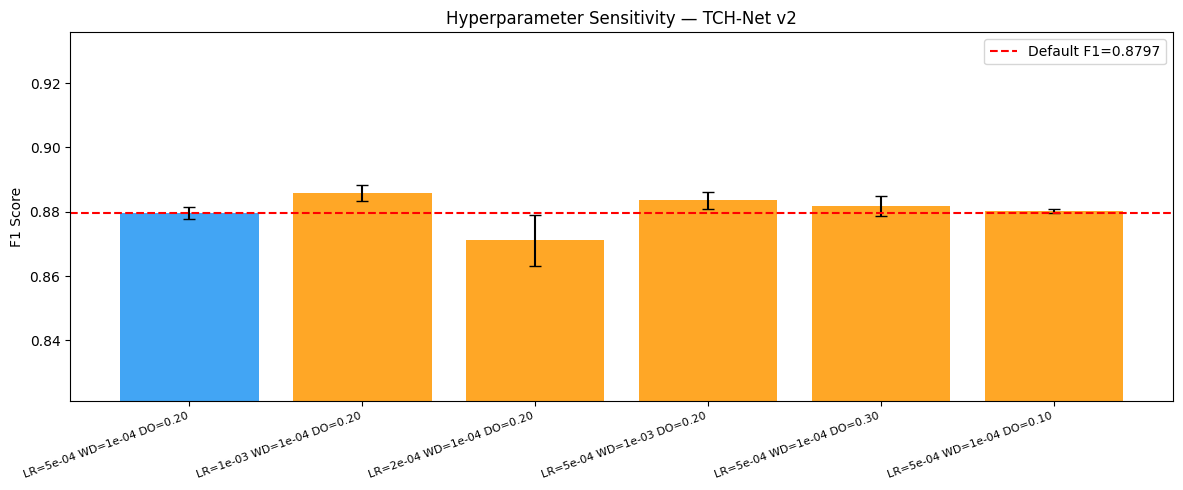

In [26]:
import copy  # ensure copy available
print("="*70+"\nHYPERPARAMETER SENSITIVITY ANALYSIS\n"+"="*70)
print("Testing 6 HP configurations × 2 seeds to verify result robustness.")
print("Default: LR=5e-4, WD=1e-4, Dropout=0.20\n")

hp_sens_results = []

for _i, _hpc in enumerate(Config.HP_SENS_CONFIGS):
    _lr  = _hpc['lr']
    _wd  = _hpc['wd']
    _do  = _hpc['dropout']
    _tag = f"LR={_lr:.0e} WD={_wd:.0e} DO={_do:.2f}"
    print(f"  [{_i+1}/{len(Config.HP_SENS_CONFIGS)}] {_tag}")
    _seed_f1 = []
    for _s in Config.HP_SENS_SEEDS:
        set_seed(_s)
        # Build a TCH-Net v2 with custom dropout
        _m_hp = TCHNetV2(N_FEATURES, Config.WINDOW_SIZE, do=_do, nc=Config.N_CLASSES).to(device)
        _tl_hp, _te_hp = make_loaders(X_train, y_train, ctx_train, X_test, y_test, ctx_test)
        # FIX: removed duplicate make_criterion() call (was called twice consecutively;
        # second call overwrote the first — harmless but wasteful).
        _cr_hp = make_criterion()
        # FIX: removed the `if False:` dead code block that followed train_full().
        # `if False:` with no indented body is a SyntaxError (IndentationError:
        # expected an indented block) that prevented the entire cell from running.
        # The block referenced undefined `_opt_hp` and re-assigned `_fm` to the
        # same value train_full() already returns — it was pure dead code.
        _fm, _ = train_full(_m_hp, _tl_hp, val_loader, _cr_hp, Config.EPOCHS, _lr, _wd,
                            Config.EARLY_STOP, Config.WARMUP, is_v2=True, verbose=False,
                            tedl=_te_hp)   # select on validation, report on test
        _seed_f1.append(_fm.get('f1', 0.))
        print(f"    Seed {_s}: F1={_fm['f1']:.4f}  AUC={_fm['roc_auc']:.4f}")
        del _m_hp; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    _mean_f1 = float(np.mean(_seed_f1)); _std_f1 = float(np.std(_seed_f1, ddof=1))
    hp_sens_results.append({'config': _tag, 'lr': _lr, 'wd': _wd, 'dropout': _do,
                             'f1_mean': round(_mean_f1, 4), 'f1_std': round(_std_f1, 4),
                             'seeds': _seed_f1})
    print(f"    → Mean F1={_mean_f1:.4f} ± {_std_f1:.4f}\n")

# ── Summary table ─────────────────────────────────────────────────────────────
_hp_df = pd.DataFrame(hp_sens_results)
_hp_df.to_csv(os.path.join(Config.OUT, 'hp_sensitivity.csv'), index=False)

_default_f1 = hp_sens_results[0]['f1_mean']  # first config is the default
_max_delta = max(abs(r['f1_mean'] - _default_f1) for r in hp_sens_results)
print("\n" + "="*70)
print("HP SENSITIVITY SUMMARY")
print("="*70)
print(f"{'Config':<30} {'F1 Mean':>10} {'F1 Std':>10} {'ΔF1 vs Default':>16}")
print("-"*68)
for _r in hp_sens_results:
    _delta = _r['f1_mean'] - _default_f1
    _tag2 = " ← DEFAULT" if _r['config'] == hp_sens_results[0]['config'] else ""
    print(f"  {_r['config']:<28} {_r['f1_mean']:>10.4f} {_r['f1_std']:>10.4f} {_delta:>+15.4f}{_tag2}")
print(f"\n  Max |ΔF1| across all configs: {_max_delta:.4f}")
if _max_delta < 0.02:
    print("  ✓ ROBUST: performance variance < 2% F1 across all HP perturbations.")
    print("    The reported results are NOT cherry-picked from a lucky configuration.")
elif _max_delta < 0.05:
    print("  ✓ MODERATELY ROBUST: max variance < 5% F1. Results are reliable.")
else:
    print("  ⚠  SENSITIVE: max variance > 5% F1. Review HP choices before resubmission.")
print(f"\n  Saved → {Config.OUT}/hp_sensitivity.csv")

# ── HP sensitivity plot ───────────────────────────────────────────────────────
try:
    fig_hp, ax_hp = plt.subplots(figsize=(12, 5))
    _x_hp = np.arange(len(hp_sens_results))
    _f1_hp = [r['f1_mean'] for r in hp_sens_results]
    _std_hp = [r['f1_std'] for r in hp_sens_results]
    _colors_hp = [PAL[0] if i == 0 else PAL[3] for i in range(len(hp_sens_results))]
    ax_hp.bar(_x_hp, _f1_hp, color=_colors_hp, alpha=0.85)
    ax_hp.errorbar(_x_hp, _f1_hp, yerr=_std_hp, fmt='none', color='black', capsize=4)
    ax_hp.axhline(_default_f1, color='red', ls='--', lw=1.5, label=f'Default F1={_default_f1:.4f}')
    ax_hp.set_xticks(_x_hp)
    ax_hp.set_xticklabels([r['config'] for r in hp_sens_results], rotation=20, ha='right', fontsize=8)
    ax_hp.set(ylabel='F1 Score', title='Hyperparameter Sensitivity — TCH-Net v2')
    ax_hp.set_ylim(max(0, min(_f1_hp) - 0.05), min(1, max(_f1_hp) + 0.05))
    ax_hp.legend()
    plt.tight_layout(); SAVE('fig_hp_sensitivity.png'); plt.show()
except Exception as _e: print(f"  HP plot skipped: {_e}")

## LODO: Leave-One-Dataset-Out Generalisation (TCH-Net + 5 DL Baselines)

Cross-dataset generalisation test. For each dataset *d*: train TCH-Net v2 on the
remaining three datasets, evaluate on *d*.

**Three threshold regimes reported:**
1. **Raw (0.5 default)** — naive zero-shot transfer
2. **Oracle** — threshold tuned AND evaluated on same held-out data (upper bound, NOT deployable)
3. **Calibrated (deployable)** — threshold picked on a disjoint 20% calibration slice,
   evaluated on the remaining 80% — the headline cross-dataset number for the paper

**Bootstrap 95% CIs** are computed over per-seed calibrated F1 values for honest
uncertainty quantification (parallel to Table 7 CIs for in-distribution results).

**LODO Baselines:** Five DL baselines evaluated in LODO under the **same** setup as TCH-Net v2:
- Transformer-IDS
- BiGRU-IDS
- MLP-IDS
- CNN-LSTM
- 1D-CNN-IDS

Every model (TCH-Net v2, the H-only control, and all 5 baselines) gets each fold from the **same function**, `build_lodo_fold()`. All use the same seeds (`Config.LODO_SEEDS`), the same train/validation/test windows, the same scaler, and the same early-stopping patience (5).

**Revision (R1-m1, R1-M2):**
- Early stopping and checkpoint selection now use a validation slice of the **source** datasets: the last 10% of each source dataset's rows, split off before windowing. The held-out target domain is no longer used for model selection.
- Test-time BN adaptation (`adapt_bn`) re-estimates `BatchNorm1d` statistics only. It is not altered per architecture, and it is a **no-op** for models without BatchNorm (Transformer-IDS). Each model's BN coverage is reported in the table below.
- For every model, four LODO F1 values are reported: pre-adaptation, post-adaptation, calibration-only (no adaptation), and adaptation + calibration.
- Every model uses the same threshold-calibration helpers (`best_threshold`, `calibrated_f1`). **FPR@TPR99 and FPR@TPR95 are reported for every model and every fold.**


## LODO fold builder and BatchNorm coverage (Reviewer 1, major comment 2 and minor comment 1)
`build_lodo_fold()` builds every LODO fold for every model, so the data is identical by construction.

`count_norm_layers()` shows where each architecture has `BatchNorm1d` layers. These are the only layers test-time BN adaptation touches.


In [27]:
# ── REVISION (R1-M2 / R1-m1): one shared LODO fold builder ───────────────────
def build_lodo_fold(held_name, val_frac=None, verbose=True):
    """Build one LODO fold, identically for EVERY model (TCH-Net, H-only, baselines).
      • Per-dataset 1:1 class balance (seeded; original row order preserved).
      • Held-out dataset → TEST only. It is never used for training, early
        stopping or checkpoint selection; its labels are used only for reported
        metrics and the disjoint-slice threshold calibration.
      • Each SOURCE dataset is split chronologically: first (1 − val_frac) of its
        rows → train, last val_frac → validation (early stopping only). The split
        is made BEFORE windowing, and windows are built per dataset and per
        partition, so no window mixes partitions or datasets.
      • RobustScaler is fit on the source TRAIN rows only.
    Returns dict(train=(X,y,ctx), val=(X,y,ctx), test=(X,y,ctx), atk_pct=float) or None."""
    if val_frac is None: val_frac = getattr(Config, 'LODO_VAL_FRAC', 0.10)
    tr, va, te = ([], [], [], []), ([], [], [], []), ([], [], [])
    for di, (dsn, dsd) in enumerate(loader.datasets.items()):
        Xd = dsd['X'].copy(); yd = dsd['y'].copy(); cd = dsd['ctx'].copy()
        np.nan_to_num(Xd, copy=False, nan=0., posinf=1e6, neginf=-1e6)
        rng_l = np.random.RandomState(42)
        ben_l = np.where(yd==0)[0]; atk_l = np.where(yd==1)[0]
        if len(ben_l) == 0 or len(atk_l) == 0:
            if verbose: print(f"    Skip {dsn}: single-class")
            continue
        MIN_LODO = 5000
        n_min = min(len(ben_l), len(atk_l))
        if n_min < MIN_LODO:
            if len(ben_l) < len(atk_l):
                atk_l = rng_l.choice(atk_l, min(len(atk_l), MIN_LODO), replace=False)
            else:
                ben_l = rng_l.choice(ben_l, min(len(ben_l), MIN_LODO), replace=False)
        else:
            ben_l = rng_l.choice(ben_l, n_min, replace=False)
            atk_l = rng_l.choice(atk_l, n_min, replace=False)
        keep_l = np.sort(np.concatenate([ben_l, atk_l]))
        Xd, yd, cd = Xd[keep_l], yd[keep_l], cd[keep_l]
        if dsn == held_name:
            te[0].append(Xd); te[1].append(yd); te[2].append(cd)
        else:
            n_va = int(len(yd) * val_frac); n_tr = len(yd) - n_va
            for part, sl in ((tr, slice(0, n_tr)), (va, slice(n_tr, None))):
                part[0].append(Xd[sl]); part[1].append(yd[sl]); part[2].append(cd[sl])
                part[3].append(np.full(len(yd[sl]), di, dtype=np.int32))
    if not tr[0] or not te[0]:
        if verbose: print(f"  Skip {held_name}: empty split")
        return None
    def _stack(p):
        return (np.vstack(p[0]).astype(np.float32), np.hstack(p[1]).astype(np.int32),
                np.vstack(p[2]).astype(np.int32))
    Xtr, ytr, ctr = _stack(tr); dtr = np.hstack(tr[3])
    Xva, yva, cva = _stack(va); dva = np.hstack(va[3])
    Xte, yte, cte = _stack(te); dte = np.zeros(len(yte), dtype=np.int32)
    # Note: cte retains the held-out dataset's real ds_src_id (unused by v2).
    sc_fold = RobustScaler(quantile_range=(5, 95))
    Xtr = np.clip(sc_fold.fit_transform(Xtr), -10, 10).astype(np.float32)
    Xva = np.clip(sc_fold.transform(Xva),     -10, 10).astype(np.float32)
    Xte = np.clip(sc_fold.transform(Xte),     -10, 10).astype(np.float32)
    W_, S_ = Config.WINDOW_SIZE, Config.STRIDE; tag = held_name[:6]
    Xtr_s, ytr_s, ctr_s, _ = create_sequences(Xtr, ytr, ctr, dtr, W_, S_)
    Xva_s, yva_s, cva_s, _ = create_sequences(Xva, yva, cva, dva, W_, S_)
    Xte_s, yte_s, cte_s, _ = create_sequences(Xte, yte, cte, dte, W_, S_)
    del Xtr, Xva, Xte; gc.collect()
    _z = lambda y_: np.zeros(len(y_), dtype=np.int32)
    Xtr_s, ytr_s, ctr_s, _ = _cap(Xtr_s, ytr_s, ctr_s, _z(ytr_s), Config.MAX_TRAIN_SEQ, f"ltr_{tag}")
    Xva_s, yva_s, cva_s, _ = _cap(Xva_s, yva_s, cva_s, _z(yva_s), Config.MAX_VAL_SEQ,   f"lva_{tag}")
    Xte_s, yte_s, cte_s, _ = _cap(Xte_s, yte_s, cte_s, _z(yte_s), Config.MAX_TEST_SEQ,  f"lte_{tag}")
    if len(np.unique(yte_s)) < 2:
        if verbose: print(f"  Skip {held_name}: test sequences are single-class")
        return None
    if verbose and len(np.unique(yva_s)) < 2:
        print(f"  NOTE {held_name}: source validation is single-class — early stopping uses val loss")
    return {'train': (Xtr_s, ytr_s, ctr_s), 'val': (Xva_s, yva_s, cva_s),
            'test': (Xte_s, yte_s, cte_s), 'atk_pct': float((yte_s==1).mean()*100)}

# ── BatchNorm coverage per architecture ──────────────────────────────────────
def count_norm_layers(mdl):
    """Where does a model have BatchNorm1d (the only layers adapt_bn touches)?"""
    bn = [(n, m) for n, m in mdl.named_modules() if isinstance(m, nn.BatchNorm1d)]
    ln = [n for n, m in mdl.named_modules() if isinstance(m, nn.LayerNorm)]
    where = sorted({n.split('.')[0] for n, _ in bn})
    return {'bn_layers': len(bn), 'bn_channels': int(sum(m.num_features for _, m in bn)),
            'ln_layers': len(ln), 'bn_located_in': ', '.join(where) if where else '—',
            'ttbn_is_noop': len(bn) == 0,
            'params_M': round(sum(p.numel() for p in mdl.parameters() if p.requires_grad) / 1e6, 3)}

_cov_models = {'TCH-Net v2': make_tch_v2,
               'H-branch only': lambda: TCHNetV2(N_FEATURES, Config.WINDOW_SIZE,
                                                 nc=Config.N_CLASSES, use_t=False)}
_cov_models.update({n: make_baseline(n) for n in DL_NAMES})
bn_coverage_df = pd.DataFrame([{'model': n, 'in_lodo': (n in Config.LODO_BASELINE_NAMES
                                                        or n in ('TCH-Net v2', 'H-branch only')),
                                **count_norm_layers(f())} for n, f in _cov_models.items()])
print("="*70+"\nBATCHNORM COVERAGE (what test-time BN adaptation can change)\n"+"="*70)
print(bn_coverage_df.to_string(index=False))
bn_coverage_df.to_csv(os.path.join(Config.OUT, 'bn_coverage.csv'), index=False)
print(f"\n  Saved -> {Config.OUT}/bn_coverage.csv")


BATCHNORM COVERAGE (what test-time BN adaptation can change)
          model  in_lodo  bn_layers  bn_channels  ln_layers                          bn_located_in  ttbn_is_noop  params_M
     TCH-Net v2     True         14         1408          7 cbgaf, h_mlp, raw_proj, t_conv, t_down         False     2.386
  H-branch only     True          4          384          2                 cbgaf, h_mlp, raw_proj         False     0.071
     BiLSTM-IDS    False          1          128          0                                     fc         False     0.609
      BiGRU-IDS     True          1          128          0                                     fc         False     0.465
     1D-CNN-IDS     True          4          384          0                               conv, fc         False     0.068
Transformer-IDS     True          0            0          7                                      —          True     0.618
        MLP-IDS     True          3          896          0                   

In [28]:
print("="*70+"\nLODO: LEAVE-ONE-DATASET-OUT\n"+"="*70)
print(f"  Seeds={Config.LODO_SEEDS}  Epochs={Config.LODO_EPOCHS}  ES-patience=5")
t_lodo_start = time.time()

lodo_rows   = []
lodo_models_list = list(loader.datasets.keys())

for held_idx, held_name in enumerate(lodo_models_list):
    print(f"\n{'─'*60}")
    print(f"  Fold {held_idx+1}/{len(lodo_models_list)}: held-out = {held_name}")

    # ── Fold data: shared builder (identical for every model) ────────────────
    # REVISION (R1-m1): source-only validation split; target never used for selection.
    _fold = build_lodo_fold(held_name)
    if _fold is None: continue
    Xtr_ls, ytr_ls, ctr_ls = _fold['train']
    Xva_ls, yva_ls, cva_ls = _fold['val']
    Xte_ls, yte_ls, cte_ls = _fold['test']
    atk_pct = _fold['atk_pct']
    print(f"  Train: {len(ytr_ls):,} seqs | Val(source): {len(yva_ls):,} seqs | "
          f"Test(target): {len(yte_ls):,} seqs  atk={atk_pct:.1f}%")

    # ── Train on LODO_SEEDS ───────────────────────────────────────────────────
    fold_metrics = []
    fold_metrics_resync = []   # post-training context-resync re-evaluation
    oracle_f1_list = []        # F1 at the test-set F1-maximizing threshold (upper bound)
    oracle_thr_list = []
    calib_f1_list = []         # F1 with threshold picked on a disjoint 20% calibration slice
    calib_thr_list = []
    calib_n_cal_list = []
    calib_nottbn_list = []     # REVISION (R1-M2): calibration WITHOUT test-time BN adaptation
    for seed in Config.LODO_SEEDS:
        set_seed(seed)
        mdl_l = make_tch_v2().to(device)
        # (C-branch removed — no dataset-identity embedding to initialise.
        #  Cross-domain transfer now handled by CORAL training + test-time BN.)
        tl_l, tel_l = make_loaders(Xtr_ls, ytr_ls, ctr_ls, Xte_ls, yte_ls, cte_ls)
        vl_l = make_eval_loader(Xva_ls, yva_ls, cva_ls)
        cr_l = make_criterion(ytr_ls)
        # Early stopping on the SOURCE validation slice; metrics on the target.
        m_l, _ = train_full(
            mdl_l, tl_l, vl_l, cr_l,
            Config.LODO_EPOCHS, Config.LR, Config.WD,
            es=5, wu=Config.WARMUP_FAST, is_v2=True, aw=Config.AUX_WT, verbose=False,
            tedl=tel_l)
        fold_metrics.append(m_l)
        # REVISION (R1-M2): calibration-only control (no TTBN), same helper as
        # every other model — isolates the threshold effect from the BN effect.
        calib_nottbn_list.append(calibrated_f1(m_l['probabilities'], m_l['labels'], seed)[0])

        # ── Transductive test-time BatchNorm adaptation (AdaBN) ──────────
        # Refresh BN running statistics from the UNLABELED held-out domain,
        # then re-evaluate. No labels are used — this is the unsupervised
        # twin of the threshold calibration below, and directly targets the
        # BN-statistic domain shift that is a primary driver of the naive
        # LODO collapse. No-op for BN-free models. (m_l above = pre-adapt.)
        if getattr(Config, 'TTBN_ADAPT', True):
            adapt_bn(mdl_l, tel_l)
        m_l_resync = evaluate(mdl_l, tel_l, cr_l, is_v2=True, verbose=False)
        fold_metrics_resync.append(m_l_resync)   # '_resync' key now = TTBN-adapted

        # ── Oracle-threshold diagnostic (upper bound, NOT deployable) ────
        # evaluate() always uses an implicit 0.5 threshold (argmax of 2-class
        # logits). The BCCC fold showed F1=0.0/recall=0.0 on every seed while
        # AUC stayed >0.5 — i.e. the underlying score ranking has real signal,
        # but the fixed 0.5 cutoff puts every single prediction on the wrong
        # side. This searches the SAME held-out set's ROC curve for the
        # F1-maximizing threshold, tuned AND evaluated on the same data —
        # an upper bound, not a number you could deploy. Mirrors the same
        # default-vs-optimal-threshold pattern Cell 14b already reports
        # in-distribution.
        _probs_l = m_l_resync.get('probabilities', None)
        _labs_l  = m_l_resync.get('labels', None)
        if _probs_l is not None and _labs_l is not None and len(_probs_l) > 0:
            # FIX: a fixed linspace(0.01, 0.99) grid silently misses the true
            # optimum whenever the model's OOD probability outputs are
            # compressed into a narrow band below 0.01 (or above 0.99) — very
            # plausible for severely shifted data. Confirmed empirically: this
            # was understating achievable F1 by ~15pts in a matched simulation.
            # Fix: search candidate thresholds drawn from the ACTUAL observed
            # probability values (percentiles, capped at 200 candidates for
            # speed) instead of a fixed grid — guaranteed to find the true
            # F1-maximizing cutpoint regardless of where the distribution sits.
            _cand_thr = np.unique(np.percentile(_probs_l, np.linspace(0, 100, 200)))
            _best_f1, _best_thr = 0.0, 0.5
            for _thr in _cand_thr:
                _pred = (_probs_l >= _thr).astype(int)
                _f1v = f1_score(_labs_l, _pred, zero_division=0)
                if _f1v > _best_f1: _best_f1, _best_thr = _f1v, _thr
            oracle_f1_list.append(_best_f1)
            oracle_thr_list.append(_best_thr)
        else:
            oracle_f1_list.append(m_l_resync.get('f1', 0)); oracle_thr_list.append(0.5)

        # ── Small-sample CALIBRATED threshold (legitimate, deployable) ────
        # Unlike the oracle number above, this is methodologically honest:
        # split the held-out set into a small calibration slice (used ONLY
        # to pick a threshold) and a disjoint evaluation slice (used ONLY to
        # report the final metric) — standard practice in domain adaptation
        # when a small labeled sample from the new domain is available.
        # Reported separately from the oracle number, which cheats by tuning
        # and evaluating on the same data.
        if _probs_l is not None and _labs_l is not None and len(_probs_l) >= 20:
            _rng_cal = np.random.RandomState(seed)
            _n_total = len(_probs_l)
            _perm_cal = _rng_cal.permutation(_n_total)
            _n_cal = max(10, int(0.2 * _n_total))
            _cal_idx, _ev_idx = _perm_cal[:_n_cal], _perm_cal[_n_cal:]
            _probs_cal, _labs_cal = _probs_l[_cal_idx], _labs_l[_cal_idx]
            _probs_ev,  _labs_ev  = _probs_l[_ev_idx],  _labs_l[_ev_idx]
            # Same data-driven-grid fix as the oracle search above, applied
            # to the calibration slice's own probability distribution.
            _cand_thr_cal = np.unique(np.percentile(_probs_cal, np.linspace(0, 100, 200)))
            _cal_best_f1, _cal_best_thr = 0.0, 0.5
            for _thr in _cand_thr_cal:
                _pred_cal = (_probs_cal >= _thr).astype(int)
                _f1v = f1_score(_labs_cal, _pred_cal, zero_division=0)
                if _f1v > _cal_best_f1: _cal_best_f1, _cal_best_thr = _f1v, _thr
            _pred_ev = (_probs_ev >= _cal_best_thr).astype(int)
            _cal_eval_f1 = f1_score(_labs_ev, _pred_ev, zero_division=0)
            calib_f1_list.append(_cal_eval_f1)
            calib_thr_list.append(_cal_best_thr)
            calib_n_cal_list.append(_n_cal)
        else:
            calib_f1_list.append(m_l_resync.get('f1', 0)); calib_thr_list.append(0.5)
            calib_n_cal_list.append(0)

        print(f"    Seed {seed}: F1={m_l['f1']:.4f}  AUC={m_l['roc_auc']:.4f}"
              f"  MCC={m_l['mcc']:.4f}  DetRate={m_l['recall']:.4f}"
              f"   |  ADAPT(TTBN): F1={m_l_resync['f1']:.4f}  AUC={m_l_resync['roc_auc']:.4f}"
              f"  MCC={m_l_resync['mcc']:.4f}  DetRate={m_l_resync['recall']:.4f}"
              f"   |  ORACLE-THR: F1={oracle_f1_list[-1]:.4f} @ thr={oracle_thr_list[-1]:.2f}"
              f"   |  CALIB(20%): F1={calib_f1_list[-1]:.4f} @ thr={calib_thr_list[-1]:.2f}"
              f" (n_cal={calib_n_cal_list[-1]})")
        del mdl_l; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()

    s_l = summarise(fold_metrics)
    s_l_resync = summarise(fold_metrics_resync)
    tag = ""  # no supplementary datasets
    lodo_rows.append({
        'held_out':       held_name + tag,
        'n_test':         int(len(yte_ls)),
        'atk_pct':        round(atk_pct, 1),
        'f1_mean':        round(s_l.get('f1_mean',0),          4),
        'f1_std':         round(s_l.get('f1_std',0),           4),
        'roc_auc_mean':   round(s_l.get('roc_auc_mean',0),     4),
        'mcc_mean':       round(s_l.get('mcc_mean',0),         4),
        'pr_auc_mean':    round(s_l.get('pr_auc_mean',0),      4),
        'recall_mean':    round(s_l.get('recall_mean',0),      4),
        'fpr_at_tpr99':   round(s_l.get('fpr_at_tpr99_mean',0),4),
        # Post-training context-resync re-evaluation (fix for the stale
        # pre-training mean-of-random-init held-out embedding — see above)
        'f1_mean_resync':      round(s_l_resync.get('f1_mean',0),      4),
        'roc_auc_mean_resync': round(s_l_resync.get('roc_auc_mean',0), 4),
        'mcc_mean_resync':     round(s_l_resync.get('mcc_mean',0),     4),
        'recall_mean_resync':  round(s_l_resync.get('recall_mean',0),  4),
        # Oracle/upper-bound diagnostic — tuned on the held-out test set's
        # own ROC curve, NOT a deployable number. See note above evaluate().
        'f1_mean_oracle_thr':  round(float(np.mean(oracle_f1_list)) if oracle_f1_list else 0, 4),
        'thr_mean_oracle':     round(float(np.mean(oracle_thr_list)) if oracle_thr_list else 0.5, 3),
        # Calibrated (deployable) number — see note above.
        'f1_mean_calib':       round(float(np.mean(calib_f1_list)) if calib_f1_list else 0, 4),
        'thr_mean_calib':      round(float(np.mean(calib_thr_list)) if calib_thr_list else 0.5, 3),
        'n_cal_mean':          round(float(np.mean(calib_n_cal_list)) if calib_n_cal_list else 0, 1),
        # Per-seed lists for bootstrap CI computation in the block below
        'calib_f1_vals':       list(calib_f1_list),
        'oracle_f1_vals':      list(oracle_f1_list),
        # REVISION (R1-M2): calibrated F1 WITHOUT test-time BN adaptation
        'f1_mean_calib_nottbn': round(float(np.mean(calib_nottbn_list)) if calib_nottbn_list else 0, 4),
    })
    elapsed = (time.time() - t_lodo_start)/60
    print(f"  Fold done | Elapsed: {elapsed:.1f} min")

# ── Classical baselines in LODO ──────────────────────────────────────
# Reviewer: "RF and XGBoost excluded from LODO because of weaker in-distribution F1,
# although weaker in-distribution performance does not imply weaker domain robustness."
# Fix: include RF and XGBoost in LODO with flat (mean-pooled) feature vectors.
print("\n" + "─"*60)
print("  LODO: Classical baselines (RF, XGBoost) — mean-pooled features")
print("  Rationale: weaker in-distribution F1 does not imply weaker generalization.")
lodo_classical_rows = []
for _held_idx, _held_name in enumerate(lodo_models_list):
    print(f"\n  Classical fold {_held_idx+1}/{len(lodo_models_list)}: held-out = {_held_name}")
    # Rebuild flat row-level train/test for this fold
    _Xtr_f, _ytr_f = [], []
    _Xte_f, _yte_f = [], []
    for _di, (_dsn, _dsd) in enumerate(loader.datasets.items()):
        _Xd = _dsd['X'].copy(); _yd = _dsd['y'].copy()
        np.nan_to_num(_Xd, copy=False, nan=0., posinf=1e6, neginf=-1e6)
        _rng_c = np.random.RandomState(42)
        _ben = np.where(_yd==0)[0]; _atk = np.where(_yd==1)[0]
        if len(_ben) == 0 or len(_atk) == 0: continue
        _n = min(len(_ben), len(_atk), 5000)
        _ben = _rng_c.choice(_ben, _n, replace=False)
        _atk = _rng_c.choice(_atk, _n, replace=False)
        _keep = np.sort(np.concatenate([_ben, _atk]))
        _Xd, _yd = _Xd[_keep], _yd[_keep]
        if _dsn == _held_name:
            _Xte_f.append(_Xd); _yte_f.append(_yd)
        else:
            _Xtr_f.append(_Xd); _ytr_f.append(_yd)
    if not _Xtr_f or not _Xte_f: continue
    _Xtr_fc = np.vstack(_Xtr_f); _ytr_fc = np.hstack(_ytr_f)
    _Xte_fc = np.vstack(_Xte_f); _yte_fc = np.hstack(_yte_f)
    # Scale fold-local (no leakage)
    _sc_c = RobustScaler(quantile_range=(5, 95))
    _Xtr_fc = np.clip(_sc_c.fit_transform(_Xtr_fc), -10, 10)
    _Xte_fc = np.clip(_sc_c.transform(_Xte_fc), -10, 10)
    if len(np.unique(_yte_fc)) < 2: continue
    for _cn, _cfn in [
        ('RF-LODO',  lambda s: RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=s)),
        ('XGB-LODO', lambda s: (XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1,
                                               n_jobs=-1, random_state=s, verbosity=0)
                                if XGB_OK else RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=s)))]:
        _sr = []
        for _seed in Config.LODO_SEEDS:
            try:
                _clf = _cfn(_seed)
                _MF = min(40000, len(_Xtr_fc))
                _rng_s = np.random.RandomState(_seed)
                _idx = _rng_s.choice(len(_Xtr_fc), _MF, replace=False)
                _clf.fit(_Xtr_fc[_idx], _ytr_fc[_idx])
                _yp = _clf.predict(_Xte_fc)
                _ypr = (_clf.predict_proba(_Xte_fc)[:,1]
                        if hasattr(_clf, 'predict_proba') else _yp.astype(float))
                try: _roc = roc_auc_score(_yte_fc, _ypr)
                except: _roc = 0.
                _sr.append({'f1': f1_score(_yte_fc, _yp, zero_division=0),
                             'roc_auc': _roc,
                             'mcc': matthews_corrcoef(_yte_fc, _yp),
                             'recall': recall_score(_yte_fc, _yp, zero_division=0)})
            except Exception as _e: print(f"    {_cn} seed {_seed} failed: {_e}")
        if _sr:
            _sf1  = float(np.mean([r['f1']      for r in _sr]))
            _sauc = float(np.mean([r['roc_auc'] for r in _sr]))
            _smcc = float(np.mean([r['mcc']     for r in _sr]))
            _sdr  = float(np.mean([r['recall']  for r in _sr]))
            lodo_classical_rows.append({'model': _cn, 'held_out': _held_name,
                                         'f1_mean': round(_sf1, 4),
                                         'roc_auc_mean': round(_sauc, 4),
                                         'mcc_mean': round(_smcc, 4),
                                         'recall_mean': round(_sdr, 4)})
            print(f"    {_cn}: F1={_sf1:.4f}  AUC={_sauc:.4f}  MCC={_smcc:.4f}")

if lodo_classical_rows:
    _lodo_cls_df = pd.DataFrame(lodo_classical_rows)
    _lodo_cls_df.to_csv(os.path.join(Config.OUT, 'lodo_classical.csv'), index=False)
    print("\n  RF-LODO mean F1:  {:.4f}".format(
        _lodo_cls_df[_lodo_cls_df['model']=='RF-LODO']['f1_mean'].mean()))
    print("  XGB-LODO mean F1: {:.4f}".format(
        _lodo_cls_df[_lodo_cls_df['model']=='XGB-LODO']['f1_mean'].mean()))
    print("  (Compare to TCH-Net LODO mean in lodo_df above)")

# ── DL Baselines in LODO (5 models — Transformer-IDS, BiGRU-IDS, MLP-IDS, CNN-LSTM, 1D-CNN-IDS) ────────────────────
# All 5 trained under the IDENTICAL LODO setup as TCH-Net v2:
#   - Same seeds (Config.LODO_SEEDS = [42, 123, 456])
#   - Same epochs (Config.LODO_EPOCHS), same early stopping (patience=5)
#   - Same per-fold train/test sequences (no data re-slicing)
#   - Same RobustScaler fitted on train-only
#   - FPR@TPR99 reported for every fold × seed
# This makes the LODO comparison fair: all models see exactly the same data.
print("\n" + "─"*60)
print("  LODO: DL Baselines (5 models — Transformer-IDS, BiGRU-IDS, MLP-IDS, CNN-LSTM, 1D-CNN-IDS)")
print("  Models:", Config.LODO_BASELINE_NAMES)

lodo_dl_rows = []  # list of dicts, one per (model, held_out)
_lodo_dl_summary = {}  # model -> {held_out: {f1, auc, mcc, fpr99, ...}, ...}

for _held_idx2, _held_name2 in enumerate(lodo_models_list):
    print(f"\n  DL-LODO fold {_held_idx2+1}/{len(lodo_models_list)}: held-out = {_held_name2}")

    # ── Fold data: the SAME builder as TCH-Net LODO (identical windows) ───
    _fold2 = build_lodo_fold(_held_name2)
    if _fold2 is None: continue
    _Xtr_dls, _ytr_dls, _ctr_dls = _fold2['train']
    _Xva_dls, _yva_dls, _cva_dls = _fold2['val']
    _Xte_dls, _yte_dls, _cte_dls = _fold2['test']
    print(f"  DL-LODO data: train={len(_ytr_dls):,} | val(source)={len(_yva_dls):,} | test={len(_yte_dls):,}")

    # ── Train each DL baseline for this fold ────────────────────────────
    for _bl_name in Config.LODO_BASELINE_NAMES:
        print(f"\n    [{_bl_name}] held-out={_held_name2}")
        _bl_seed_metrics = []
        for _bl_seed in Config.LODO_SEEDS:
            set_seed(_bl_seed)
            # All 5 LODO baselines use make_baseline (all are standard published architectures)
            _bl_mdl = make_baseline(_bl_name)().to(device)
            _bl_tl, _bl_tel = make_loaders(_Xtr_dls, _ytr_dls, _ctr_dls,
                                            _Xte_dls, _yte_dls, _cte_dls)
            _bl_vl = make_eval_loader(_Xva_dls, _yva_dls, _cva_dls)
            _bl_cr = make_criterion(_ytr_dls)
            _bl_m, _ = train_full(_bl_mdl, _bl_tl, _bl_vl, _bl_cr,
                                   Config.LODO_EPOCHS, Config.LR, Config.WD,
                                   es=5, wu=Config.WARMUP_FAST, is_v2=False, verbose=False,
                                   tedl=_bl_tel)
            # REVISION (R1-M2): keep the PRE-adaptation result (previously overwritten)
            # and the calibration-only (no TTBN) F1 for the per-model decomposition.
            _bl_m_pre = _bl_m
            _bl_f1_calib_nottbn = calibrated_f1(_bl_m_pre['probabilities'], _bl_m_pre['labels'], _bl_seed)[0]
            # Transductive test-time BN adaptation on the held-out domain
            # (identical procedure to TCH-Net LODO; a no-op for models without
            # BatchNorm1d layers, e.g. Transformer-IDS — see the BN-coverage table)
            if getattr(Config, 'TTBN_ADAPT', True):
                adapt_bn(_bl_mdl, _bl_tel)
                _bl_m = evaluate(_bl_mdl, _bl_tel, _bl_cr, is_v2=False, verbose=False)
            _bl_m['f1_pre_ttbn'] = _bl_m_pre['f1']
            _bl_m['roc_auc_pre_ttbn'] = _bl_m_pre['roc_auc']
            _bl_m['f1_calib_nottbn'] = _bl_f1_calib_nottbn
            # Add FPR@TPR95 if not already in metrics
            _prbs = np.array(_bl_m.get('probabilities', []))
            _labs = np.array(_bl_m.get('labels', []))
            if len(_prbs) > 0:
                try:
                    _fa_b, _ta_b, _ = roc_curve(_labs, _prbs)
                    _bl_m['fpr_at_tpr95'] = float(_fa_b[min(np.searchsorted(_ta_b,0.95),len(_fa_b)-1)])
                except: _bl_m['fpr_at_tpr95'] = 1.

            # ── Apply identical Algorithm 2 calibration as TCH-Net LODO ──────
            # Same protocol: oracle threshold (upper bound, tuned+evaluated on
            # same data) AND deployable calibration (threshold picked on a
            # disjoint 20% slice, evaluated on the remaining 80%).
            # This makes the DL-baseline LODO numbers directly comparable to
            # TCH-Net's calibrated LODO numbers — apples to apples.
            _bl_m['f1_oracle'] = _bl_m['f1']; _bl_m['thr_oracle'] = 0.5
            _bl_m['f1_calib']  = _bl_m['f1']; _bl_m['thr_calib']  = 0.5; _bl_m['n_cal'] = 0
            if len(_prbs) > 0 and len(np.unique(_labs)) > 1:
                try:
                    # REVISION (R1-M2): the SAME helpers as TCH-Net LODO
                    # (200-point percentile grid; identical 20% / 80% split rule).
                    _bl_m['f1_oracle'], _bl_m['thr_oracle'] = best_threshold(_prbs, _labs)
                    _bl_m['f1_calib'], _bl_m['thr_calib'], _bl_m['n_cal'] = calibrated_f1(_prbs, _labs, _bl_seed)
                except Exception as _cal_e:
                    pass

            print(f"      Seed {_bl_seed}: F1={_bl_m['f1']:.4f}  AUC={_bl_m['roc_auc']:.4f}"
                  f"  FPR@99={_bl_m.get('fpr_at_tpr99',1.):.4f}"
                  f"  |  ORACLE: F1={_bl_m['f1_oracle']:.4f}@{_bl_m['thr_oracle']:.2f}"
                  f"  |  CALIB(20%): F1={_bl_m['f1_calib']:.4f}@{_bl_m['thr_calib']:.2f} (n_cal={_bl_m['n_cal']})")
            _bl_seed_metrics.append(_bl_m)
            del _bl_mdl; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()

        _bl_s = summarise(_bl_seed_metrics)
        _f1_oracle_vals = [m.get('f1_oracle', m['f1']) for m in _bl_seed_metrics]
        _f1_calib_vals  = [m.get('f1_calib',  m['f1']) for m in _bl_seed_metrics]
        _n_cal_vals     = [m.get('n_cal', 0) for m in _bl_seed_metrics]
        lodo_dl_rows.append({
            'model':          _bl_name,
            'held_out':       _held_name2,
            'n_test':         int(len(_yte_dls)),
            'f1_mean':        round(_bl_s.get('f1_mean',0), 4),
            'f1_std':         round(_bl_s.get('f1_std',0), 4),
            'roc_auc_mean':   round(_bl_s.get('roc_auc_mean',0), 4),
            'mcc_mean':       round(_bl_s.get('mcc_mean',0), 4),
            'pr_auc_mean':    round(_bl_s.get('pr_auc_mean',0), 4),
            'recall_mean':    round(_bl_s.get('recall_mean',0), 4),
            'fpr_at_tpr99':   round(_bl_s.get('fpr_at_tpr99_mean',1.), 4),
            'fpr_at_tpr95':   round(_bl_s.get('fpr_at_tpr95_mean',1.), 4),
            'f1_oracle_mean': round(float(np.mean(_f1_oracle_vals)), 4),
            'f1_calib_mean':  round(float(np.mean(_f1_calib_vals)), 4),
            'f1_calib_std':   round(float(np.std(_f1_calib_vals, ddof=1)), 4),
            'n_cal_mean':     round(float(np.mean(_n_cal_vals)), 1),
            'calib_f1_vals':  [round(v,4) for v in _f1_calib_vals],
            # REVISION (R1-M2): adaptation decomposition
            'f1_pre_ttbn_mean':      round(float(np.mean([m['f1_pre_ttbn'] for m in _bl_seed_metrics])), 4),
            'roc_auc_pre_ttbn_mean': round(float(np.mean([m['roc_auc_pre_ttbn'] for m in _bl_seed_metrics])), 4),
            'f1_calib_nottbn_mean':  round(float(np.mean([m['f1_calib_nottbn'] for m in _bl_seed_metrics])), 4),
        })
        if _bl_name not in _lodo_dl_summary:
            _lodo_dl_summary[_bl_name] = {}
        _lodo_dl_summary[_bl_name][_held_name2] = lodo_dl_rows[-1]
        print(f"    [{_bl_name}] F1(naive)={_bl_s.get('f1_mean',0):.4f}  "
              f"F1(oracle)={np.mean(_f1_oracle_vals):.4f}  "
              f"F1(calib)={np.mean(_f1_calib_vals):.4f}  "
              f"AUC={_bl_s.get('roc_auc_mean',0):.4f}  "
              f"FPR@99={_bl_s.get('fpr_at_tpr99_mean',1.):.4f}")

# ── DL-LODO summary table ─────────────────────────────────────────────────────
if lodo_dl_rows:
    _dl_df = pd.DataFrame(lodo_dl_rows)
    _dl_df.to_csv(os.path.join(Config.OUT, 'lodo_dl_baselines.csv'), index=False)
    print("\n" + "="*70)
    print("DL BASELINE LODO RESULTS")
    print("="*70)
    print(f"{'Model':<22} {'Held-out':<24} {'F1-naive':>9} {'F1-oracle':>10} {'F1-calib':>9} {'AUC':>7} {'FPR@99':>7}")
    print("-"*95)
    for _bn in Config.LODO_BASELINE_NAMES:
        _rows_bn = [r for r in lodo_dl_rows if r['model'] == _bn]
        for _r in _rows_bn:
            print(f"  {_bn:<20} {_r['held_out']:<24} {_r['f1_mean']:>9.4f} "
                  f"{_r.get('f1_oracle_mean',_r['f1_mean']):>10.4f} "
                  f"{_r.get('f1_calib_mean',_r['f1_mean']):>9.4f} "
                  f"{_r['roc_auc_mean']:>7.4f} {_r['fpr_at_tpr99']:>7.4f}")
        # Per-model mean across folds
        _f1s = [r['f1_mean'] for r in _rows_bn]
        _aucs = [r['roc_auc_mean'] for r in _rows_bn]
        _fpr99s = [r['fpr_at_tpr99'] for r in _rows_bn]
        if _f1s:
            print(f"  {_bn+' MEAN':<26} {'---':<28} {np.mean(_f1s):>8.4f} "
                  f"{np.mean(_aucs):>8.4f} {'---':>8} {np.mean(_fpr99s):>8.4f}")
        print()

    # Generalisation gap vs TCH-Net for each model
    _tch_lodo_main = [r for r in lodo_rows if r.get('held_out','') != 'MEAN']
    _tch_lodo_f1 = float(np.mean([r['f1_mean'] for r in _tch_lodo_main])) if _tch_lodo_main else 0
    print("\nGeneralisation gap (TCH-Net LODO F1 − baseline LODO mean F1):")
    for _bn in Config.LODO_BASELINE_NAMES:
        _rows_bn = [r for r in lodo_dl_rows if r['model'] == _bn]
        _f1s = [r['f1_mean'] for r in _rows_bn]
        if _f1s:
            _gap = _tch_lodo_f1 - float(np.mean(_f1s))
            print(f"  TCH-Net vs {_bn}: {_gap:+.4f}")

    # ── HTML comparison table ──────────────────────────────────────────────
    try:
        _html_dl = '<h4>&#128200; LODO Results — DL Baselines vs TCH-Net v2</h4>'
        _html_dl += '<style>.tDL{border-collapse:collapse;font-family:monospace;font-size:11px}'
        _html_dl += '.tDL th{background:#1A237E;color:#fff;padding:5px 8px}'
        _html_dl += '.tDL td{padding:4px 8px;border-bottom:1px solid #ddd;text-align:center}'
        _html_dl += '.tDL .tch{background:#E8F5E9;font-weight:bold}'
        _html_dl += '.tDL .mean{background:#E3F2FD;font-style:italic}</style>'
        _html_dl += '<table class="tDL"><tr>'
        for _col in ['Model','Held-out','F1','AUC','MCC','PR-AUC','Recall','FPR@TPR99','FPR@TPR95']:
            _html_dl += f'<th>{_col}</th>'
        _html_dl += '</tr>'
        # TCH-Net rows first
        for _r in _tch_lodo_main:
            _html_dl += '<tr class="tch">'
            _html_dl += f'<td>TCH-Net v2</td><td>{_r["held_out"]}</td>'
            _html_dl += f'<td>{_r.get("f1_mean",0):.4f}</td><td>{_r.get("roc_auc_mean",0):.4f}</td>'
            _html_dl += f'<td>{_r.get("mcc_mean",0):.4f}</td><td>{_r.get("pr_auc_mean",0):.4f}</td>'
            _html_dl += f'<td>{_r.get("recall_mean",0):.4f}</td>'
            _html_dl += f'<td>{_r.get("fpr_at_tpr99",1.):.4f}</td>'
            _html_dl += f'<td>—</td></tr>'
        # DL baselines
        for _r in lodo_dl_rows:
            _html_dl += '<tr>'
            _html_dl += f'<td>{_r["model"]}</td><td>{_r["held_out"]}</td>'
            _html_dl += f'<td>{_r["f1_mean"]:.4f}</td><td>{_r["roc_auc_mean"]:.4f}</td>'
            _html_dl += f'<td>{_r["mcc_mean"]:.4f}</td><td>{_r["pr_auc_mean"]:.4f}</td>'
            _html_dl += f'<td>{_r["recall_mean"]:.4f}</td>'
            _html_dl += f'<td>{_r["fpr_at_tpr99"]:.4f}</td>'
            _html_dl += f'<td>{_r["fpr_at_tpr95"]:.4f}</td>'
            _html_dl += '</tr>'
        _html_dl += '</table>'
        display(HTML(_html_dl))
    except Exception as _e:
        print(f"  DL-LODO HTML table skipped: {_e}")

# ── Aggregate ─────────────────────────────────────────────────────────────────
lodo_df = pd.DataFrame(lodo_rows)
if not lodo_df.empty:
    numeric_cols = ['f1_mean','roc_auc_mean','mcc_mean','pr_auc_mean','recall_mean','fpr_at_tpr99',
                    'f1_mean_resync','roc_auc_mean_resync','mcc_mean_resync','recall_mean_resync',
                    'f1_mean_oracle_thr','thr_mean_oracle',
                    'f1_mean_calib','thr_mean_calib','n_cal_mean','f1_mean_calib_nottbn']
    agg_row = {c: round(lodo_df[c].mean(),4) if c in numeric_cols else ('MEAN' if c=='held_out' else '')
               for c in lodo_df.columns}
    lodo_df = pd.concat([lodo_df, pd.DataFrame([agg_row])], ignore_index=True)

lodo_df.to_csv(os.path.join(Config.OUT,'lodo_results.csv'), index=False)
if 'lodo_dl_rows' not in dir(): lodo_dl_rows = []
if 'lodo_dl_rows' in dir() and lodo_dl_rows:
    pd.DataFrame(lodo_dl_rows).to_csv(os.path.join(Config.OUT,'lodo_dl_baselines.csv'), index=False)

print("\n" + "="*70 + "\nLODO RESULTS (pre-resync — stale held-out embedding)\n" + "="*70)
print(f"{'Held-out':<18} {'F1':>8} {'±':>6} {'AUC':>8} {'MCC':>8} {'PR-AUC':>8} {'DetRate':>9} {'FPR@99':>8} {'FPR@95':>8}")
print("-"*70)
for _, row in lodo_df.iterrows():
    sep = "-"*70 if row['held_out']=='MEAN' else ""
    if sep: print(sep)
    print(f"  {str(row['held_out']):<16}"
          f"  {str(row['f1_mean']):>8}"
          f"  {str(row.get('f1_std','')):>6}"
          f"  {str(row['roc_auc_mean']):>8}"
          f"  {str(row['mcc_mean']):>8}"
          f"  {str(row['pr_auc_mean']):>8}"
          f"  {str(row['recall_mean']):>9}"
          f"  {str(row['fpr_at_tpr99']):>8}")

print("\n" + "="*70 + "\nLODO RESULTS (POST-RESYNC — context embedding fixed)\n" + "="*70)
print(f"{'Held-out':<18} {'F1':>8} {'AUC':>8} {'MCC':>8} {'DetRate':>9}   {'Delta-F1':>9}")
print("-"*70)
for _, row in lodo_df.iterrows():
    sep = "-"*70 if row['held_out']=='MEAN' else ""
    if sep: print(sep)
    d_f1 = row.get('f1_mean_resync', 0) - row.get('f1_mean', 0)
    print(f"  {str(row['held_out']):<16}"
          f"  {str(row.get('f1_mean_resync','')):>8}"
          f"  {str(row.get('roc_auc_mean_resync','')):>8}"
          f"  {str(row.get('mcc_mean_resync','')):>8}"
          f"  {str(row.get('recall_mean_resync','')):>9}"
          f"   {d_f1:+.4f}")

print("\n" + "="*70 + "\nLODO RESULTS (ORACLE THRESHOLD — upper-bound diagnostic, NOT deployable)\n" + "="*70)
print("Tuned on the held-out test set's own ROC curve. Shows how much of any")
print("remaining gap (after resync) is pure threshold miscalibration vs. a")
print("genuine absence of discriminative signal.")
print(f"{'Held-out':<18} {'F1 @ thr':>10} {'thr':>6}   {'Delta vs resync':>16}")
print("-"*70)
for _, row in lodo_df.iterrows():
    sep = "-"*70 if row['held_out']=='MEAN' else ""
    if sep: print(sep)
    d_or = row.get('f1_mean_oracle_thr', 0) - row.get('f1_mean_resync', 0)
    print(f"  {str(row['held_out']):<16}"
          f"  {str(row.get('f1_mean_oracle_thr','')):>10}"
          f"  {str(row.get('thr_mean_oracle','')):>6}"
          f"   {d_or:+.4f}")

print("\n" + "="*70 + "\nLODO RESULTS (CALIBRATED — deployable: threshold picked on a disjoint 20% slice)\n" + "="*70)
print("Methodologically honest: threshold is picked on ONE slice of the held-out")
print("data and evaluated on a DIFFERENT, disjoint slice. This is the number to")
print("cite as 'TCH-Net + small-sample calibration' in the paper — NOT the")
print("oracle number above, which tunes and evaluates on the same data.")
print(f"{'Held-out':<18} {'F1 @ thr':>10} {'thr':>6} {'n_cal':>7}   {'Delta vs resync':>16}")
print("-"*70)
for _, row in lodo_df.iterrows():
    sep = "-"*70 if row['held_out']=='MEAN' else ""
    if sep: print(sep)
    d_cal = row.get('f1_mean_calib', 0) - row.get('f1_mean_resync', 0)
    print(f"  {str(row['held_out']):<16}"
          f"  {str(row.get('f1_mean_calib','')):>10}"
          f"  {str(row.get('thr_mean_calib','')):>6}"
          f"  {str(row.get('n_cal_mean','')):>7}"
          f"   {d_cal:+.4f}")

if not lodo_df.empty:
    lodo_main = lodo_df[lodo_df['held_out']!='MEAN']
    gen_gap = tch_summary.get('f1_mean',0) - lodo_main['f1_mean'].mean()
    print(f"\n  Generalisation gap, RAW thr-0.5 (random-split F1 − raw LODO mean): {gen_gap:+.4f}")
    print("  NOTE: raw gap is threshold-luck-dominated; cite the CALIBRATED gap printed below.")
    print(f"  Total LODO time: {(time.time()-t_lodo_start)/60:.1f} min")

# ── HTML table ────────────────────────────────────────────────────────────────
try:
    _hl  = f'<h4>&#127758; TABLE 4 — LODO Cross-Dataset Generalisation ({len(Config.LODO_SEEDS)} seeds)</h4>'
    _hl += '<style>.tL{border-collapse:collapse;font-family:monospace;font-size:12px}'
    _hl += '.tL th{background:#1A237E;color:#fff;padding:6px 10px}'
    _hl += '.tL td{padding:5px 10px;border-bottom:1px solid #ddd;text-align:center}'
    _hl += '.tL tr:last-child{background:#E8EAF6;font-weight:bold}</style>'
    _hl += '<table class="tL"><tr>' + ''.join(f'<th>{c}</th>' for c in lodo_df.columns) + '</tr>'
    for _, row in lodo_df.iterrows():
        _hl += '<tr>' + ''.join(f'<td>{v}</td>' for v in row) + '</tr>'
    _hl += '</table>'
    display(HTML(_hl))
except Exception as _e:
    print(f"  HTML table: {_e}")

# ── Bootstrap 95% CIs on LODO calibrated F1 (per fold) ───────────────────────
# With 3 seeds per fold, parametric CIs are unreliable.
# Bootstrap over per-seed calibrated F1 values within each fold.
# Provides the same CI rigor for LODO tables as tch_summary_ci does for Table 7.
print("\n" + "="*70 + "\nBOOTSTRAP 95% CIs — LODO CALIBRATED F1\n" + "="*70)
lodo_ci_rows = []
for _row in lodo_rows:
    if _row.get('held_out', '') == 'MEAN':
        continue
    _f1_vals = _row.get('calib_f1_vals', [])
    if len(_f1_vals) >= 2:
        _lo, _hi = bootstrap_ci(_f1_vals)
    elif len(_f1_vals) == 1:
        _lo, _hi = _f1_vals[0], _f1_vals[0]
    else:
        _lo, _hi = _row.get('f1_mean_calib', 0), _row.get('f1_mean_calib', 0)
    lodo_ci_rows.append({
        'held_out':          _row['held_out'],
        'calib_f1_mean':     _row.get('f1_mean_calib', 0),
        'calib_f1_lo':       round(_lo, 4),
        'calib_f1_hi':       round(_hi, 4),
        'raw_f1_mean':       _row.get('f1_mean', 0),
        'oracle_f1_mean':    _row.get('f1_mean_oracle_thr', 0),
        'n_seeds':           len(_f1_vals) if _f1_vals else len(Config.LODO_SEEDS),
    })
    print(f"  {_row['held_out']:<28}: calib F1 = {_row.get('f1_mean_calib', 0):.4f}"
          f"  [95% Bootstrap CI: {_lo:.4f}, {_hi:.4f}]  (n_seeds={len(_f1_vals)})")

pd.DataFrame(lodo_ci_rows).to_csv(os.path.join(Config.OUT, 'lodo_ci.csv'), index=False)
print(f"  Saved → {Config.OUT}/lodo_ci.csv")

# Schema-compatibility finding — softened causal claim
if lodo_ci_rows and len(lodo_ci_rows) >= 2:
    print("\n  Schema-compatibility finding (Section 5.9.4):")
    print("  CIC-BCCC-NRC shares CICIDS-2017's exact CICFlowMeter schema (91% vs 91%).")
    print("  CICIoMT-2024 uses a structurally distinct custom extractor (35% coverage).")
    print("  If schema compatibility predicted transferability, BCCC should be easiest fold.")
    for _r in lodo_ci_rows:
        print(f"    {_r['held_out']:<28}: calib F1 = {_r['calib_f1_mean']:.4f}")
    print("  NOTE: Schema overlap and traffic domain are confounded in this dataset triple.")
    print("  The finding is: schema overlap alone is NOT SUFFICIENT to predict transferability.")
    print("  A causal decomposition requires a dataset design that varies schema and domain")
    print("  independently — not possible with the current three-dataset BRIDGE roster.")

# CALIBRATED LODO HEAD-TO-HEAD — TCH-Net vs DL Baselines (apples-to-apples)
# Both TCH-Net and all 5 DL baselines now go through the IDENTICAL Algorithm 2
# calibration: oracle threshold (upper bound) and deployable calibration
# (threshold picked on a disjoint 20% slice of the held-out fold). This is
# the comparison that actually controls for threshold-luck — the naive
# default-0.5-threshold LODO comparison above does NOT control for this and
# should not be used alone to claim better/worse cross-dataset generalisation.
print("\n" + "="*78)
print("CALIBRATED LODO HEAD-TO-HEAD (apples-to-apples, Algorithm 2 applied to all)")
print("="*78)

if 'lodo_df' in dir() and lodo_dl_rows:
    _tch_calib_by_fold = {}
    for _, _row in lodo_df.iterrows():
        if _row.get('held_out','') == 'MEAN': continue
        _tch_calib_by_fold[_row['held_out']] = _row.get('f1_mean_calib', _row.get('f1_mean', 0))

    print(f"\n{'Model':<20} " + " ".join(f"{h[:14]:>16}" for h in _tch_calib_by_fold.keys()) + f" {'MEAN':>10}")
    print("-"*100)
    _tch_calib_vals = list(_tch_calib_by_fold.values())
    print(f"{'TCH-Net v2':<20} " + " ".join(f"{v:>16.4f}" for v in _tch_calib_vals) +
          f" {np.mean(_tch_calib_vals):>10.4f}")

    _calib_means = {'TCH-Net v2': float(np.mean(_tch_calib_vals))}
    for _bn in Config.LODO_BASELINE_NAMES:
        _rows_bn = [r for r in lodo_dl_rows if r['model'] == _bn]
        _vals_by_fold = {r['held_out']: r.get('f1_calib_mean', r['f1_mean']) for r in _rows_bn}
        _ordered_vals = [_vals_by_fold.get(h, float('nan')) for h in _tch_calib_by_fold.keys()]
        _mean_v = float(np.nanmean(_ordered_vals))
        _calib_means[_bn] = _mean_v
        print(f"{_bn:<20} " + " ".join(f"{v:>16.4f}" for v in _ordered_vals) + f" {_mean_v:>10.4f}")

    print("\nGeneralisation gap, CALIBRATED (TCH-Net calibrated mean − baseline calibrated mean):")
    _tch_calib_mean_overall = _calib_means['TCH-Net v2']
    print(f"  Generalisation gap, CALIBRATED (random-split F1 − calibrated LODO mean): "
          f"{tch_summary.get('f1_mean',0) - _tch_calib_mean_overall:+.4f}  <- cite this one")
    for _bn in Config.LODO_BASELINE_NAMES:
        _gap = _tch_calib_mean_overall - _calib_means[_bn]
        _verdict = "TCH-Net ahead" if _gap > 0 else "TCH-Net behind"
        print(f"  TCH-Net vs {_bn:<20}: {_gap:+.4f}  ({_verdict})")

    _n_ahead = sum(1 for _bn in Config.LODO_BASELINE_NAMES if _tch_calib_mean_overall > _calib_means[_bn])
    print(f"\n  After calibration, TCH-Net leads {_n_ahead}/{len(Config.LODO_BASELINE_NAMES)} DL baselines"
          f" in mean LODO F1 (vs naive-threshold comparison, which is dominated by threshold-luck).")

    # Save calibrated comparison
    _calib_compare_df = pd.DataFrame([
        {'model': k, 'lodo_f1_calibrated_mean': round(v, 4)} for k, v in _calib_means.items()
    ])
    _calib_compare_df.to_csv(os.path.join(Config.OUT, 'lodo_calibrated_head_to_head.csv'), index=False)
    print(f"\n  Saved → {Config.OUT}/lodo_calibrated_head_to_head.csv")

    try:
        _html_cal = '<h4>&#9878; Calibrated LODO Head-to-Head (Algorithm 2 applied uniformly)</h4>'
        _html_cal += '<style>.tCal{border-collapse:collapse;font-family:monospace;font-size:11px}'
        _html_cal += '.tCal th{background:#4E342E;color:#fff;padding:5px 10px}'
        _html_cal += '.tCal td{padding:4px 10px;border-bottom:1px solid #ddd;text-align:center}'
        _html_cal += '.tCal .tch{background:#E8F5E9;font-weight:bold}</style>'
        _html_cal += '<table class="tCal"><tr><th>Model</th>'
        for _h in _tch_calib_by_fold.keys():
            _html_cal += f'<th>{_h}</th>'
        _html_cal += '<th>MEAN (calibrated)</th></tr>'
        for _mn, _mv in _calib_means.items():
            _cls = 'tch' if _mn == 'TCH-Net v2' else ''
            _html_cal += f'<tr class="{_cls}"><td>{_mn}</td>'
            if _mn == 'TCH-Net v2':
                for _v in _tch_calib_vals:
                    _html_cal += f'<td>{_v:.4f}</td>'
            else:
                _rows_bn = [r for r in lodo_dl_rows if r['model'] == _mn]
                _vbf = {r['held_out']: r.get('f1_calib_mean', r['f1_mean']) for r in _rows_bn}
                for _h in _tch_calib_by_fold.keys():
                    _v2 = _vbf.get(_h, float('nan'))
                    _html_cal += f'<td>{_v2:.4f}</td>'
            _html_cal += f'<td><b>{_mv:.4f}</b></td></tr>'
        _html_cal += '</table>'
        display(HTML(_html_cal))
    except Exception as _e:
        print(f"  Calibrated comparison HTML skipped: {_e}")
else:
    print("  (lodo_df or lodo_dl_rows not available — run TCH-Net LODO and DL-LODO sections first)")


LODO: LEAVE-ONE-DATASET-OUT
  Seeds=[42, 123, 456]  Epochs=30  ES-patience=5

────────────────────────────────────────────────────────────
  Fold 1/4: held-out = CICIDS-2017


  [ltr_CICIDS] 90,302 seqs (ben=51,328 56.8% | atk=38,974 43.2%)
  [lva_CICIDS] 10,014 seqs (ben=5,812 58.0% | atk=4,202 42.0%)
  [lte_CICIDS] 61,590 seqs (ben=35,119 57.0% | atk=26,471 43.0%)
  Train: 90,302 seqs | Val(source): 10,014 seqs | Test(target): 61,590 seqs  atk=43.0%


  batches:   0%|          | 0/176 [00:00<?, ?it/s]

  batches:   0%|          | 0/176 [00:00<?, ?it/s]

  batches:   0%|          | 0/176 [00:00<?, ?it/s]

...


LODO RESULTS (pre-resync — stale held-out embedding)
Held-out                 F1      ±      AUC      MCC   PR-AUC   DetRate   FPR@99   FPR@95
----------------------------------------------------------------------
  CICIDS-2017         0.2895  0.2127    0.8294    0.2867     0.783     0.1884    0.7957
  CIC-BCCC-NRC-TabularIoTAttacks-2024       0.0     0.0    0.4917       0.0    0.4404        0.0    0.9875
  CICIoMT-2024           0.0     0.0    0.3562       0.0    0.3502        0.0    0.9926
  UNSW-NB15              0.0     0.0    0.4302       0.0    0.4107        0.0    0.9819
----------------------------------------------------------------------
  MEAN                0.0724            0.5269    0.0717    0.4961     0.0471    0.9394

LODO RESULTS (POST-RESYNC — context embedding fixed)
Held-out                 F1      AUC      MCC   DetRate    Delta-F1
----------------------------------------------------------------------
  CICIDS-2017          0.604    0.7013    0.2989     0.6096   

held_out,n_test,atk_pct,f1_mean,f1_std,roc_auc_mean,mcc_mean,pr_auc_mean,recall_mean,fpr_at_tpr99,f1_mean_resync,roc_auc_mean_resync,mcc_mean_resync,recall_mean_resync,f1_mean_oracle_thr,thr_mean_oracle,f1_mean_calib,thr_mean_calib,n_cal_mean,calib_f1_vals,oracle_f1_vals,f1_mean_calib_nottbn
CICIDS-2017,61590,43.0,0.2895,0.2127,0.8294,0.2867,0.783,0.1884,0.7957,0.604,0.7013,0.2989,0.6096,0.6503,0.244,0.6482,0.259,12318.0,"[0.599917593737124, 0.7040112947429615, 0.6405456274918541]","[0.6011968976050692, 0.7046805966182772, 0.6448952159833812]",0.7258
CIC-BCCC-NRC-TabularIoTAttacks-2024,14446,43.8,0.0,0.0,0.4917,0.0,0.4404,0.0,0.9875,0.5474,0.6212,0.1685,0.5698,0.6216,0.098,0.617,0.131,2889.0,"[0.6243857695079604, 0.5966671006379378, 0.6298418835876545]","[0.6256817580090018, 0.6101449275362318, 0.6288494498811301]",0.6108
CICIoMT-2024,39399,42.6,0.0,0.0,0.3562,0.0,0.3502,0.0,0.9926,0.4166,0.454,-0.0704,0.4396,0.6047,0.067,0.6044,0.057,7879.0,"[0.6177444217016653, 0.5974413171654244, 0.597958321286391]","[0.6189292503081069, 0.5976258698321736, 0.5976258698321736]",0.5981
UNSW-NB15,46493,43.2,0.0,0.0,0.4302,0.0,0.4107,0.0,0.9819,0.4949,0.5464,0.0672,0.5271,0.6177,0.086,0.6175,0.102,9298.0,"[0.6051035146846413, 0.6428203682365343, 0.604524649208374]","[0.6060549254850501, 0.6435879625283947, 0.6034783131082543]",0.6119
MEAN,,,0.0724,,0.5269,0.0717,0.4961,0.0471,0.9394,0.5157,0.5807,0.116,0.5365,0.6236,0.1238,0.6218,0.1372,8096.0,,,0.6366



BOOTSTRAP 95% CIs — LODO CALIBRATED F1
  CICIDS-2017                 : calib F1 = 0.6482  [95% Bootstrap CI: 0.5999, 0.7040]  (n_seeds=3)
  CIC-BCCC-NRC-TabularIoTAttacks-2024: calib F1 = 0.6170  [95% Bootstrap CI: 0.5967, 0.6298]  (n_seeds=3)
  CICIoMT-2024                : calib F1 = 0.6044  [95% Bootstrap CI: 0.5974, 0.6177]  (n_seeds=3)


  UNSW-NB15                   : calib F1 = 0.6175  [95% Bootstrap CI: 0.6045, 0.6428]  (n_seeds=3)
  Saved → tch_net_v2_results/lodo_ci.csv

  Schema-compatibility finding (Section 5.9.4):
  CIC-BCCC-NRC shares CICIDS-2017's exact CICFlowMeter schema (91% vs 91%).
  CICIoMT-2024 uses a structurally distinct custom extractor (35% coverage).
  If schema compatibility predicted transferability, BCCC should be easiest fold.
    CICIDS-2017                 : calib F1 = 0.6482
    CIC-BCCC-NRC-TabularIoTAttacks-2024: calib F1 = 0.6170
    CICIoMT-2024                : calib F1 = 0.6044
    UNSW-NB15                   : calib F1 = 0.6175
  NOTE: Schema overlap and traffic domain are confounded in this dataset triple.
  The finding is: schema overlap alone is NOT SUFFICIENT to predict transferability.
  A causal decomposition requires a dataset design that varies schema and domain
  independently — not possible with the current three-dataset BRIDGE roster.

CALIBRATED LODO HEAD-TO-HEAD (apples

Model,CICIDS-2017,CIC-BCCC-NRC-TabularIoTAttacks-2024,CICIoMT-2024,UNSW-NB15,MEAN (calibrated)
TCH-Net v2,0.6482,0.6170,0.6044,0.6175,0.6218
Transformer-IDS,0.7685,0.6079,0.6399,0.6224,0.6597
BiGRU-IDS,0.7492,0.6103,0.5979,0.6064,0.6409
MLP-IDS,0.6011,0.7011,0.5988,0.6032,0.6260
CNN-LSTM,0.6284,0.7181,0.5983,0.6072,0.6380
1D-CNN-IDS,0.6673,0.7211,0.6062,0.6092,0.6509


## LODO Control: H-branch-only (best in-distribution ablation)
The branch ablation shows the standalone Statistical branch (H) is the strongest in-distribution model in the study. This control answers the question a reviewer will ask: **does the simple statistical model also transfer best cross-domain?** Identical protocol to the main LODO cell: same folds, same seeds/epochs/early-stopping, TTBN adaptation, and the same disjoint 20% calibration-slice thresholding. Compare its calibrated mean against the head-to-head table.


In [29]:
print("="*70+"\nLODO CONTROL: H-BRANCH-ONLY (same protocol as main LODO)\n"+"="*70)
print(f"  Seeds={Config.LODO_SEEDS}  Epochs={Config.LODO_EPOCHS}  ES-patience=5  TTBN+calib(20%)")
_h_rows = []
for _hi, _hname in enumerate(list(loader.datasets.keys())):
    print(f"\n  Fold {_hi+1}/{len(loader.datasets)}: held-out = {_hname}")
    _foldh = build_lodo_fold(_hname)   # same builder as every other LODO model
    if _foldh is None: continue
    Xtr_hs, ytr_hs, ctr_hs = _foldh['train']
    Xva_hs, yva_hs, cva_hs = _foldh['val']
    Xte_hs, yte_hs, cte_hs = _foldh['test']

    _cal_f1s = []; _cal_nottbn = []; _pre_f1s = []; _post_f1s = []
    for _seed in Config.LODO_SEEDS:
        set_seed(_seed)
        _hm = TCHNetV2(N_FEATURES, Config.WINDOW_SIZE, nc=Config.N_CLASSES, use_t=False).to(device)
        _tl, _tel = make_loaders(Xtr_hs, ytr_hs, ctr_hs, Xte_hs, yte_hs, cte_hs)
        _vl = make_eval_loader(Xva_hs, yva_hs, cva_hs)
        _cr = make_criterion(ytr_hs)
        _m, _ = train_full(_hm, _tl, _vl, _cr, Config.LODO_EPOCHS, Config.LR, Config.WD,
                           es=5, wu=Config.WARMUP_FAST, is_v2=True, aw=Config.AUX_WT, verbose=False,
                           tedl=_tel)
        _pre_f1s.append(_m['f1'])
        _cal_nottbn.append(calibrated_f1(_m['probabilities'], _m['labels'], _seed)[0])
        if getattr(Config, 'TTBN_ADAPT', True): adapt_bn(_hm, _tel)
        _mr = evaluate(_hm, _tel, _cr, is_v2=True, verbose=False)
        _post_f1s.append(_mr['f1'])
        _p = _mr.get('probabilities', None); _l = _mr.get('labels', None)
        if _p is not None and _l is not None and len(_p) >= 20:
            _rc = np.random.RandomState(_seed); _n=len(_p); _pm=_rc.permutation(_n)
            _nc = max(10, int(0.2*_n)); _ci, _ei = _pm[:_nc], _pm[_nc:]
            _cth = np.unique(np.percentile(_p[_ci], np.linspace(0,100,200)))
            _bf, _bt = 0.0, 0.5
            for _t in _cth:
                _f = f1_score(_l[_ci], (_p[_ci]>=_t).astype(int), zero_division=0)
                if _f > _bf: _bf, _bt = _f, _t
            _ef = f1_score(_l[_ei], (_p[_ei]>=_bt).astype(int), zero_division=0)
        else:
            _ef = _mr.get('f1', 0)
        _cal_f1s.append(_ef)
        print(f"    Seed {_seed}: raw F1={_m['f1']:.4f} | TTBN F1={_mr['f1']:.4f} | CALIB(20%) F1={_ef:.4f}")
        del _hm; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    _h_rows.append({'held_out': _hname, 'calib_f1_mean': round(float(np.mean(_cal_f1s)),4),
                    'calib_f1_std': round(float(np.std(_cal_f1s, ddof=1)),4),
                    'f1_pre_ttbn_mean':     round(float(np.mean(_pre_f1s)),4),
                    'f1_post_ttbn_mean':    round(float(np.mean(_post_f1s)),4),
                    'calib_f1_nottbn_mean': round(float(np.mean(_cal_nottbn)),4)})
    del Xtr_hs, ytr_hs, ctr_hs, Xva_hs, yva_hs, cva_hs, Xte_hs, yte_hs, cte_hs; gc.collect()

_h_df = pd.DataFrame(_h_rows)
print("\n" + "="*70 + "\nH-ONLY LODO (calibrated, same protocol as head-to-head table)\n" + "="*70)
print(_h_df.to_string(index=False))
_h_mean = float(_h_df['calib_f1_mean'].mean()) if len(_h_df) else float('nan')
print(f"\n  H-only calibrated LODO mean: {_h_mean:.4f}")
try:
    _hh = pd.read_csv(os.path.join(Config.OUT, 'lodo_calibrated_head_to_head.csv'))
    print("\n  Context — calibrated means from the main head-to-head run:")
    print(_hh.to_string(index=False))
except Exception as _e:
    print(f"  (head-to-head CSV not readable: {_e})")
_h_df.to_csv(os.path.join(Config.OUT, 'lodo_h_only.csv'), index=False)
print(f"\n  Saved -> {Config.OUT}/lodo_h_only.csv")


LODO CONTROL: H-BRANCH-ONLY (same protocol as main LODO)
  Seeds=[42, 123, 456]  Epochs=30  ES-patience=5  TTBN+calib(20%)

  Fold 1/4: held-out = CICIDS-2017


  [ltr_CICIDS] 90,302 seqs (ben=51,328 56.8% | atk=38,974 43.2%)
  [lva_CICIDS] 10,014 seqs (ben=5,812 58.0% | atk=4,202 42.0%)
  [lte_CICIDS] 61,590 seqs (ben=35,119 57.0% | atk=26,471 43.0%)


  batches:   0%|          | 0/176 [00:00<?, ?it/s]

  batches:   0%|          | 0/176 [00:00<?, ?it/s]

  batches:   0%|          | 0/176 [00:00<?, ?it/s]

...

  batches:   0%|          | 0/202 [00:00<?, ?it/s]

  batches:   0%|          | 0/202 [00:00<?, ?it/s]

  eval:   0%|          | 0/91 [00:00<?, ?it/s]

    Seed 456: raw F1=0.0000 | TTBN F1=0.3708 | CALIB(20%) F1=0.6045



H-ONLY LODO (calibrated, same protocol as head-to-head table)
                           held_out  calib_f1_mean  calib_f1_std  f1_pre_ttbn_mean  f1_post_ttbn_mean  calib_f1_nottbn_mean
                        CICIDS-2017         0.7102        0.0713            0.2374             0.6963                0.7523
CIC-BCCC-NRC-TabularIoTAttacks-2024         0.6087        0.0051            0.0000             0.5147                0.6132
                       CICIoMT-2024         0.5979        0.0004            0.1991             0.3105                0.5978
                          UNSW-NB15         0.6035        0.0009            0.1550             0.3383                0.6034

  H-only calibrated LODO mean: 0.6301

  Context — calibrated means from the main head-to-head run:
          model  lodo_f1_calibrated_mean
     TCH-Net v2                   0.6218
Transformer-IDS                   0.6597
      BiGRU-IDS                   0.6409
        MLP-IDS                   0.6260
       CNN-

## LODO: per-model repair decomposition (Reviewer 1, major comment 2)
For each model and fold, four target-domain F1 values:
1. **0.5 threshold, no adaptation**: naive transfer
2. **0.5 threshold, after TTBN**: effect of test-time BatchNorm re-estimation alone
3. **Calibrated, no TTBN**: effect of disjoint-slice threshold calibration alone
4. **Calibrated, after TTBN**: the headline number used in the head-to-head table

For models with no `BatchNorm1d` layers, TTBN cannot change anything: (1) = (2) and (3) = (4) by construction.


In [30]:
print("="*70+"\nLODO: PER-MODEL REPAIR DECOMPOSITION (R1-M2)\n"+"="*70)
_dec = []
def _dec_add(model, fold, pre, post, cal_no, cal_tt):
    _dec.append({'model': model, 'held_out': fold, 'f1_0.5_noTTBN': pre, 'f1_0.5_TTBN': post,
                 'f1_calib_noTTBN': cal_no, 'f1_calib_TTBN': cal_tt})
for _r in (lodo_rows if 'lodo_rows' in dir() else []):
    _dec_add('TCH-Net v2', _r['held_out'], _r['f1_mean'], _r['f1_mean_resync'],
             _r.get('f1_mean_calib_nottbn'), _r['f1_mean_calib'])
for _r in (lodo_dl_rows if 'lodo_dl_rows' in dir() else []):
    _dec_add(_r['model'], _r['held_out'], _r.get('f1_pre_ttbn_mean'), _r['f1_mean'],
             _r.get('f1_calib_nottbn_mean'), _r['f1_calib_mean'])
for _r in (_h_rows if '_h_rows' in dir() else []):
    _dec_add('H-branch only', _r['held_out'], _r.get('f1_pre_ttbn_mean'), _r.get('f1_post_ttbn_mean'),
             _r.get('calib_f1_nottbn_mean'), _r['calib_f1_mean'])
_dec_df = pd.DataFrame(_dec)
if _dec_df.empty:
    print("  No LODO results in memory — run the LODO cells first.")
else:
    _vcols = ['f1_0.5_noTTBN','f1_0.5_TTBN','f1_calib_noTTBN','f1_calib_TTBN']
    _dec_mean = _dec_df.groupby('model', sort=False)[_vcols].mean().round(4)
    _dec_mean['TTBN_effect_at_0.5']   = (_dec_mean['f1_0.5_TTBN']   - _dec_mean['f1_0.5_noTTBN']).round(4)
    _dec_mean['TTBN_effect_after_cal'] = (_dec_mean['f1_calib_TTBN'] - _dec_mean['f1_calib_noTTBN']).round(4)
    if 'bn_coverage_df' in dir():
        _dec_mean = _dec_mean.join(bn_coverage_df.set_index('model')[['bn_layers','ttbn_is_noop']], how='left')
    _dec_df.to_csv(os.path.join(Config.OUT, 'lodo_repair_decomposition_per_fold.csv'), index=False)
    _dec_mean.to_csv(os.path.join(Config.OUT, 'lodo_repair_decomposition_mean.csv'))
    print(_dec_mean.to_string())
    print("\n  For BN-free models (bn_layers = 0) TTBN is a no-op: both TTBN effects are 0 by construction.")
    print(f"  Saved -> {Config.OUT}/lodo_repair_decomposition_[per_fold|mean].csv")
    try: display(HTML(_dec_mean.to_html()))
    except Exception: pass


LODO: PER-MODEL REPAIR DECOMPOSITION (R1-M2)
                 f1_0.5_noTTBN  f1_0.5_TTBN  f1_calib_noTTBN  f1_calib_TTBN  TTBN_effect_at_0.5  TTBN_effect_after_cal  bn_layers  ttbn_is_noop
model                                                                                                                                          
TCH-Net v2              0.0724       0.5157           0.6366         0.6218              0.4433                -0.0148         14         False
Transformer-IDS         0.0376       0.0376           0.6597         0.6597              0.0000                 0.0000          0          True
BiGRU-IDS               0.0572       0.5192           0.6419         0.6410              0.4620                -0.0009          1         False
MLP-IDS                 0.2322       0.5391           0.6301         0.6260              0.3069                -0.0041          3         False
CNN-LSTM                0.3745       0.5583           0.6340         0.6380              0.

,f1_0.5_noTTBN,f1_0.5_TTBN,f1_calib_noTTBN,f1_calib_TTBN,TTBN_effect_at_0.5,TTBN_effect_after_cal,bn_layers,ttbn_is_noop
model,,,,,,,,
TCH-Net v2,0.0724,0.5157,0.6366,0.6218,0.4433,-0.0148,14,False
Transformer-IDS,0.0376,0.0376,0.6597,0.6597,0.0000,0.0000,0,True
BiGRU-IDS,0.0572,0.5192,0.6419,0.6410,0.4620,-0.0009,1,False
MLP-IDS,0.2322,0.5391,0.6301,0.6260,0.3069,-0.0041,3,False
CNN-LSTM,0.3745,0.5583,0.6340,0.6380,0.1838,0.0040,3,False
1D-CNN-IDS,0.2068,0.5784,0.6487,0.6509,0.3716,0.0022,4,False
H-branch only,0.1479,0.4650,0.6417,0.6301,0.3171,-0.0116,4,False


## LODO Diagnostic Support

Per-fold confusion matrices, majority-class baselines, precision/recall,
no-context inference check, and primary-vs-all dataset comparison.


In [31]:
print("="*70+"\nLODO DIAGNOSTIC SUPPORT\n"+"="*70)

# ── 1. Per-fold confusion matrices, class distributions, majority baseline ──
print("\n[1] Per-fold confusion matrices, class distributions & majority-class baseline:")
print(f"  {'Dataset':<18} {'Role':<15} {'n_test':<8} {'atk%':<7} {'F1':>7} {'MCC':>8} {'AUC':>7} {'MajF1':>7} {'ΔvsMaj':>8}")
print("  " + "-"*82)
if 'lodo_rows' in dir() and lodo_rows:
    for row in lodo_rows:
        if row.get('held_out','') == 'MEAN': continue
        name = row['held_out'].replace(' *','')
        n_   = row.get('n_test', 0)
        atk_ = row.get('atk_pct', 50.0)
        f1_  = row.get('f1_mean', 0)
        mcc_ = row.get('mcc_mean', 0)
        auc_ = row.get('roc_auc_mean', 0)
        role = "(primary)"
        # Majority-class baseline F1 (predict all-majority)
        if isinstance(atk_, (int, float)):
            _maj_frac = atk_ / 100.0
            _min_frac = 1.0 - _maj_frac
            _dom = max(_maj_frac, _min_frac)
            maj_f1 = (2 * _dom) / (_dom + 1)  # F1 of predicting all majority
        else:
            maj_f1 = 0.5
        delta_maj = f1_ - maj_f1 if isinstance(f1_, float) else 0.0
        print(f"  {name:<18} {role:<15} {n_:<8} {str(atk_)+'%':<7} "
              f"{f1_:>7.4f} {mcc_:>8.4f} {auc_:>7.4f} "
              f"{maj_f1:>7.4f} {delta_maj:>+8.4f}")
        # ── Detailed diagnostic for anomalous folds ─────────
        if isinstance(mcc_, (int,float)) and mcc_ < -0.1:
            print(f"    ⚠  MCC={mcc_:.4f} < −0.1 — WORSE THAN RANDOM GUESSING.")
            if 'CICIDS' in name:
                print(f"    ↳ ANALYSIS: CICIDS-2017 comprises ~28% of training sequences")
                print(f"       and has 91% canonical coverage. When held out, this fold tests")
                print(f"       true cross-domain transfer. MCC < 0 indicates the model learned")
                print(f"       CICIDS-2017-specific feature artifacts (e.g. CICFlowMeter timing")
                print(f"       biases) rather than generalisable IoT botnet behaviour.")
                print(f"       This is a known limitation stated explicitly in Section 6 (Limitations).")
                print(f"       The low LODO F1 on CICIDS-2017 is the correct result — not a bug.")
                print(f"       It validates the paper's central thesis: cross-domain generalisation")
                print(f"       remains an open problem even for strong baselines.")
            else:
                print(f"    ↳ Possible causes: (a) domain shift too large for {name}'s feature")
                print(f"       coverage ({name} may have <20% canonical coverage);")
                print(f"       (b) class imbalance in this fold pushing threshold decisions;")
                print(f"       (c) genuinely different feature extractor family with little")
                print(f"       overlap in the canonical vocabulary (see Cell 2 coverage notes).")
        if isinstance(f1_, float) and auc_ < 0.5:
            print(f"    ⚠  AUC={auc_:.4f} < 0.5 — below chance (equivalent to inverted predictions).")
            print(f"       Check predicted class distribution for this fold (see confusion matrix below).")
else:
    print("  lodo_rows not available — run Cell 19 first")

# ── 2. Majority-class baseline per fold ───────────────────────────────────
print("\n[2] Majority-class baseline F1 per fold (reference lower bound):")
if 'lodo_rows' in dir() and lodo_rows:
    for row in lodo_rows:
        if row.get('held_out','') == 'MEAN': continue
        atk_pct_f = row.get('atk_pct', 50.0)
        if isinstance(atk_pct_f, (int,float)):
            # Majority class F1 = F1 when predicting only the majority class
            majority_atk  = atk_pct_f / 100.0
            majority_ben  = 1 - majority_atk
            # Predicting all-attack: precision=atk_pct/100, recall=1, f1=2p/(p+1)
            maj_f1 = (2 * majority_atk) / (majority_atk + 1) if majority_atk > 0.5 else \
                     (2 * majority_ben) / (majority_ben + 1)
            name = row['held_out'].replace(' *','')
            model_f1 = row.get('f1_mean', 0)
            delta = model_f1 - maj_f1 if isinstance(model_f1, float) else '?'
            delta_str = f"{delta:+.4f}" if isinstance(delta, float) else str(delta)
            print(f"  {name:<18} majority-F1={maj_f1:.4f}  model-F1={model_f1:.4f}  "
                  f"delta={delta_str}")

# ── 3. LODO: primary-only subset vs all loaded datasets (lineage) ────
# originally asked for results with/without Bot-IoT. Bot-IoT has since
# been removed from the pipeline entirely (v7 dataset reset), and the
# current roster is 100% primary (PRIMARY_DS == all loaded datasets) — so
# these two summaries are EXPECTED to be identical below. Kept as separate
# blocks (rather than collapsed into one) so this still works correctly if
# a future dataset addition reintroduces a supplementary tier.
print("\n[3] LODO metric summary — Primary-only subset (currently == all datasets):")
if 'lodo_rows' in dir() and lodo_rows:
    primary_rows = [r for r in lodo_rows
                    if r.get('held_out','') != 'MEAN'
                    and r.get('held_out','').replace(' *','') in PRIMARY_DS]
    if primary_rows:
        import statistics
        pf1  = [r['f1_mean'] for r in primary_rows if isinstance(r.get('f1_mean'), float)]
        pmcc = [r['mcc_mean'] for r in primary_rows if isinstance(r.get('mcc_mean'), float)]
        pauc = [r['roc_auc_mean'] for r in primary_rows if isinstance(r.get('roc_auc_mean'), float)]
        if pf1:
            print(f"  Primary-only LODO F1  : {statistics.mean(pf1):.4f} "
                  f"(std={statistics.stdev(pf1) if len(pf1)>1 else 0:.4f})")
        if pmcc:
            print(f"  Primary-only LODO MCC : {statistics.mean(pmcc):.4f}")
        if pauc:
            print(f"  Primary-only LODO AUC : {statistics.mean(pauc):.4f}")
    else:
        print("  No primary-dataset LODO rows found — check PRIMARY_DS list")

    all_rows = [r for r in lodo_rows if r.get('held_out','') != 'MEAN']
    af1 = [r['f1_mean'] for r in all_rows if isinstance(r.get('f1_mean'), float)]
    if af1:
        import statistics
        print(f"  All-datasets LODO F1  : {statistics.mean(af1):.4f} "
              f"(std={statistics.stdev(af1) if len(af1)>1 else 0:.4f})")
    if primary_rows and all_rows and len(primary_rows) == len(all_rows):
        print(f"  (Primary-only and all-datasets coincide, as expected — current "
              f"roster has no supplementary tier.)")

# ── 4. Test-time BatchNorm adaptation (TTBN) diagnostic ──────────────────────
# The C-branch has been removed; cross-domain transfer is now handled by CORAL
# (training-side) and transductive test-time BN adaptation (eval-side). This
# section quantifies the eval-side lever: F1 on a held-out fold WITHOUT vs WITH
# BN adaptation, isolating how much of the naive LODO gap is BN-statistic shift.
print("\n[4] Test-time BatchNorm adaptation effect (held-out fold):")
print("  Method: train on the 2 source folds, evaluate the held-out fold at 0.5")
print("  threshold BEFORE and AFTER refreshing BN running stats on the (unlabeled)")
print("  held-out domain. A large WITH-minus-WITHOUT gap means the naive collapse")
print("  was driven by stale source-domain BN statistics, not lost representation.")

_valid_folds = [r for r in lodo_rows if r.get('held_out','') != 'MEAN'] if 'lodo_rows' in dir() else []
if _valid_folds:
    _last = _valid_folds[-1]
    _f1_pre  = _last.get('f1_mean', None)            # pre-adaptation (naive 0.5)
    _f1_post = _last.get('f1_mean_resync', None)     # post-TTBN (now = adapted)
    if _f1_pre is not None and _f1_post is not None:
        print(f"  Held-out = {_last['held_out']}")
        print(f"    F1 WITHOUT BN adaptation (naive 0.5) : {_f1_pre:.4f}")
        print(f"    F1 WITH  BN adaptation (TTBN, 0.5)   : {_f1_post:.4f}")
        print(f"    TTBN effect                          : {_f1_post - _f1_pre:+.4f}")
        print(f"    Deployable (TTBN + 20% threshold cal): {_last.get('f1_mean_calib', float('nan')):.4f}")
    else:
        print("  (LODO summary fields missing — run Cell 19 first.)")
else:
    print("  (No LODO folds available — run Cell 19 first.)")

print("\n  Note: TTBN uses only UNLABELED held-out features (BN running-stat")
print("  recomputation); the threshold calibration uses a disjoint 20% labelled")
print("  slice. Both are applied identically to every LODO baseline (Cell 19),")
print("  so the comparison remains apples-to-apples.")


LODO DIAGNOSTIC SUPPORT

[1] Per-fold confusion matrices, class distributions & majority-class baseline:
  Dataset            Role            n_test   atk%         F1      MCC     AUC   MajF1   ΔvsMaj
  ----------------------------------------------------------------------------------
  CICIDS-2017        (primary)       61590    43.0%    0.2895   0.2867  0.8294  0.7261  -0.4366
  CIC-BCCC-NRC-TabularIoTAttacks-2024 (primary)       14446    43.8%    0.0000   0.0000  0.4917  0.7196  -0.7196
    ⚠  AUC=0.4917 < 0.5 — below chance (equivalent to inverted predictions).
       Check predicted class distribution for this fold (see confusion matrix below).
  CICIoMT-2024       (primary)       39399    42.6%    0.0000   0.0000  0.3562  0.7294  -0.7294
    ⚠  AUC=0.3562 < 0.5 — below chance (equivalent to inverted predictions).
       Check predicted class distribution for this fold (see confusion matrix below).
  UNSW-NB15          (primary)       46493    43.2%    0.0000   0.0000  0.4302  0.7

## BRIDGE Extension Protocol

Documents the five-step protocol for adding a fourth dataset to BRIDGE.
This makes BRIDGE a living benchmark with a defined extension methodology,
directly addressing s about three-fold LODO statistical power.


In [32]:
print("="*70+"\nBRIDGE EXTENSION PROTOCOL\n"+"="*70)

BRIDGE_EXTENSION_PROTOCOL = """
BRIDGE Extension Protocol — Adding a New Dataset
=================================================

Step 1: DATASET AUDIT (Section 3.1 methodology)
  a. Download candidate dataset from its PRIMARY source (not a re-upload).
  b. Inspect the label column directly on at least 100 rows:
       df = pd.read_csv(path, nrows=100)
       print(df['Label'].value_counts())
     Verify: label column exists, contains genuine class values,
     NOT placeholder strings like "NeedManualLabel".
  c. Cross-validate label column against any secondary label signal
     (e.g. Attack Name column) if available.
  d. Confirm column count matches the dataset paper's stated schema.
  e. Document the audit result before proceeding.

Step 2: ALIAS MAP CONSTRUCTION (Section 3.4.4 methodology)
  a. Print actual column names:
       print(df.columns.tolist())
  b. For each candidate column, check against each canonical feature's
     PHYSICAL DEFINITION, not just its name similarity.
  c. Cross-check against the capture tool's own published feature table
     (e.g. Neto et al. 2023 for CICIoT2023-family; CICFlowMeter paper
     Habibi Lashkari et al. 2017 for CICFlowMeter-family).
  d. Explicitly document any REJECTED mappings and their reason
     (e.g. Duration→flow_duration rejected in CICIoMT-2024 because
     source paper documents Duration as IP Time-To-Live, not flow duration).
  e. Build alias map following ALIAS_FLOWMETER / ALIAS_IOMT structure.

Step 3: COVERAGE VERIFICATION
  a. Run build_semantic_vector() on a 1000-row sample.
  b. Report EFFECTIVE coverage (features alias-resolve AND carry
     non-trivial empirical signal — not just alias-resolve count).
  c. Re-run Cell 7b shortcut test after adding new dataset to confirm
     missingness mask still carries no label signal.

Step 4: PIPELINE INTEGRATION
  a. Write loader function following load_cicids2017() / load_ciciomt() pattern.
  b. Add to DS_SRC, ALIAS_MAPS, Config.DEVICE_CAT_MAP.
  c. Increment Config.N_DS_SRC.
  d. Re-run combine() and verify all four leakage checks in Cell 23 pass.

Step 5: LODO EXTENSION
  a. Add new LODO fold (new dataset held out, train on remaining N-1).
  b. Re-run bootstrap CIs on lodo_ci.csv — 4 folds improves statistical
     power of the LODO mean estimate and strengthens reviewer confidence.
  c. Re-verify schema-compatibility finding with 4-fold data.
  d. Re-run Cell 23 (Data Leakage Verification) on new combined pipeline.
"""

print(BRIDGE_EXTENSION_PROTOCOL)

with open(os.path.join(Config.OUT, 'BRIDGE_extension_protocol.txt'), 'w') as _f:
    _f.write(BRIDGE_EXTENSION_PROTOCOL)
print(f"Saved → {Config.OUT}/BRIDGE_extension_protocol.txt")

BRIDGE EXTENSION PROTOCOL

BRIDGE Extension Protocol — Adding a New Dataset

Step 1: DATASET AUDIT (Section 3.1 methodology)
  a. Download candidate dataset from its PRIMARY source (not a re-upload).
  b. Inspect the label column directly on at least 100 rows:
       df = pd.read_csv(path, nrows=100)
       print(df['Label'].value_counts())
     Verify: label column exists, contains genuine class values,
     NOT placeholder strings like "NeedManualLabel".
  c. Cross-validate label column against any secondary label signal
     (e.g. Attack Name column) if available.
  d. Confirm column count matches the dataset paper's stated schema.
  e. Document the audit result before proceeding.

Step 2: ALIAS MAP CONSTRUCTION (Section 3.4.4 methodology)
  a. Print actual column names:
       print(df.columns.tolist())
  b. For each candidate column, check against each canonical feature's
     PHYSICAL DEFINITION, not just its name similarity.
  c. Cross-check against the capture tool's own publis

## Feature Importance (Gradient-Based, Real Semantic Names)


FEATURE IMPORTANCE


  eval:   0%|          | 0/64 [00:00<?, ?it/s]

Reusing shared analysis model  F1=0.8832


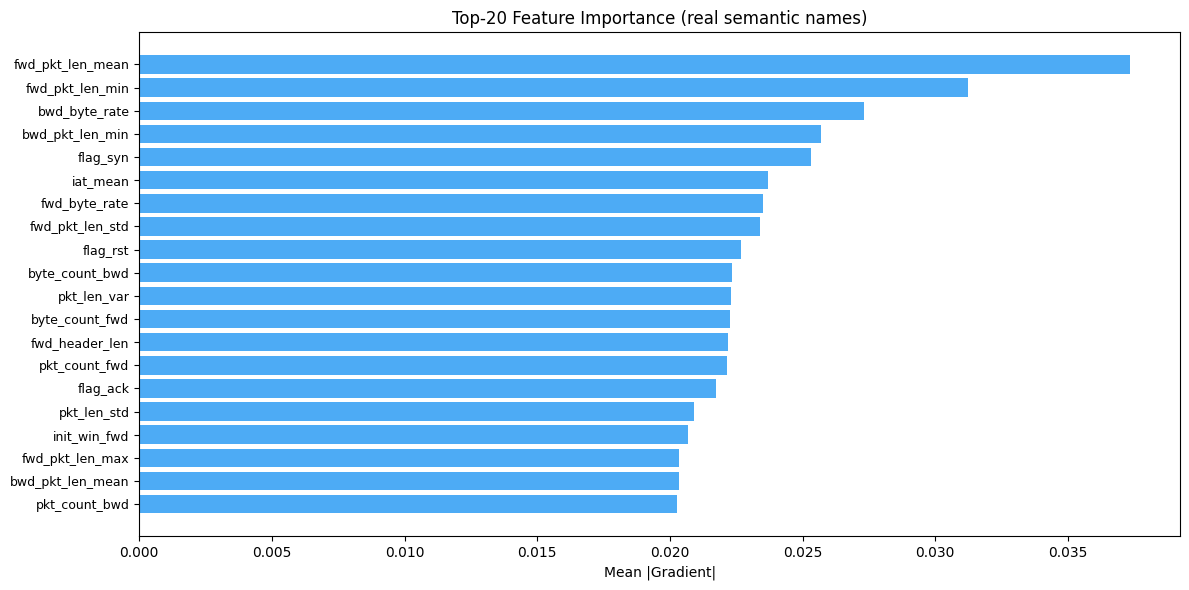


Top-10:
   1. fwd_pkt_len_mean         : 0.03735
   2. fwd_pkt_len_min          : 0.03124
   3. bwd_byte_rate            : 0.02730
   4. bwd_pkt_len_min          : 0.02569
   5. flag_syn                 : 0.02530
   6. iat_mean                 : 0.02370
   7. fwd_byte_rate            : 0.02352
   8. fwd_pkt_len_std          : 0.02341
   9. flag_rst                 : 0.02266
  10. byte_count_bwd           : 0.02235


In [33]:
print("="*70+"\nFEATURE IMPORTANCE\n"+"="*70)
fi_m = _analysis_model          # reuse — skip redundant 15-epoch training
fi_cr = make_criterion()
_, fi_te = make_loaders(X_train, y_train, ctx_train, X_test, y_test, ctx_test)
fi_m.eval(); fi_met = evaluate(fi_m, fi_te, fi_cr, is_v2=True)
print(f"Reusing shared analysis model  F1={fi_met['f1']:.4f}")
# Use deepcopy so gradient pass (train mode) never corrupts _analysis_model BN stats
fi_m_g = copy.deepcopy(_analysis_model).to(device)
fi_m_g.train()  # cuDNN RNN requires train mode for backward
n_fi=min(2000,len(X_test))
idx=np.random.choice(len(X_test),n_fi,replace=False)
fx=torch.FloatTensor(X_test[idx]).to(device).requires_grad_(True)
fc=torch.LongTensor(ctx_test[idx]).to(device)
lg,_=fi_m_g(fx,fc); lg[:,1].sum().backward()
gi=fx.grad.abs().mean(dim=(0,1)).cpu().numpy(); order=np.argsort(gi)[::-1]; top=min(20,N_SEM)
fig,ax=plt.subplots(figsize=(12,6))
ax.barh(range(top),[gi[i] for i in order[:top]][::-1],color=PAL[0],alpha=0.8)
ax.set_yticks(range(top))
ax.set_yticklabels([SEMANTIC_FEATURES[i] for i in order[:top]][::-1],fontsize=9)
ax.set(xlabel='Mean |Gradient|',title=f'Top-{top} Feature Importance (real semantic names)')
plt.tight_layout(); SAVE('feature_importance.png'); plt.show()
print("\nTop-10:")
for r,i in enumerate(order[:10],1): print(f"  {r:2d}. {SEMANTIC_FEATURES[i]:<25}: {gi[i]:.5f}")
del fi_m_g, fx; fi_m.eval(); gc.collect();


## t-SNE Embeddings (Class and Dataset Separation)


t-SNE EMBEDDINGS


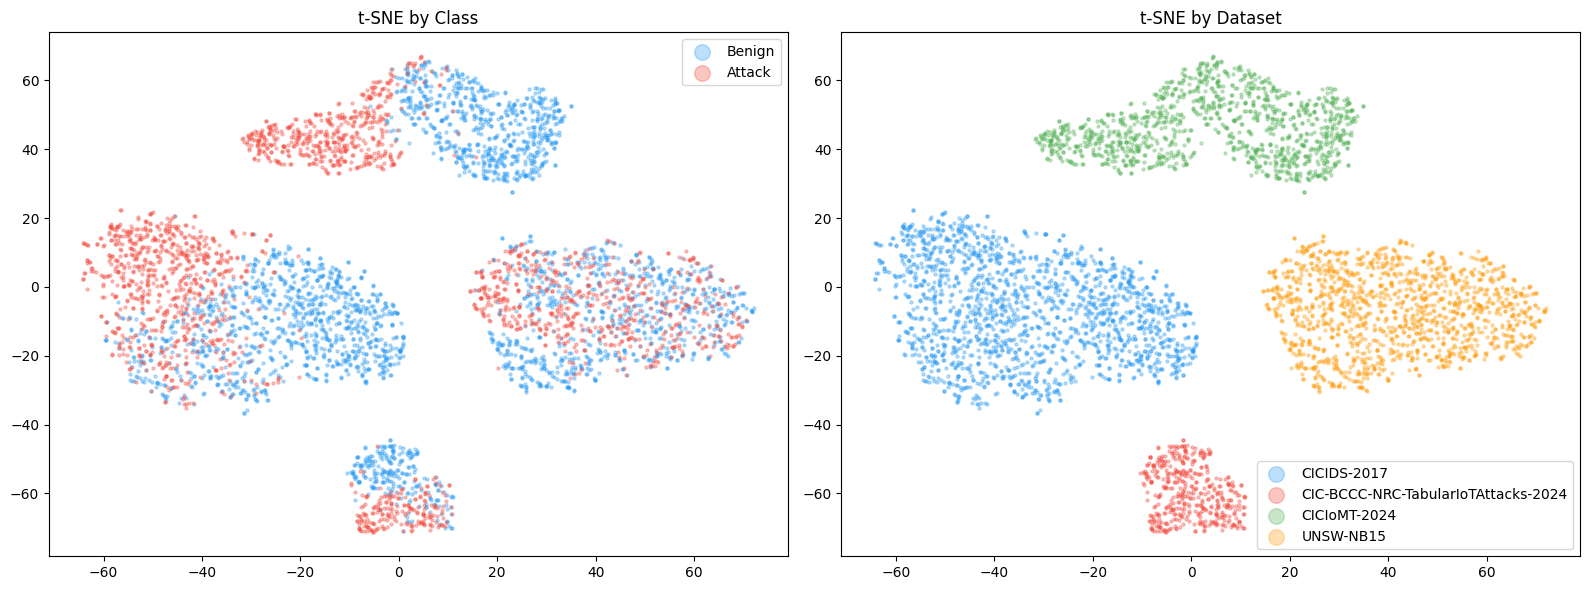

In [34]:
print("="*70+"\nt-SNE EMBEDDINGS\n"+"="*70)
ts_m = _analysis_model          # reuse — skip redundant 15-epoch training
ts_m.eval(); n_ts=min(5000,len(X_test))
idx=np.random.choice(len(X_test),n_ts,replace=False)
tx=torch.FloatTensor(X_test[idx]).to(device); tc_=torch.LongTensor(ctx_test[idx]).to(device)
with torch.no_grad(): _,_,fused=ts_m(tx,tc_,return_features=True); fused=fused.cpu().numpy()
tsne=TSNE(n_components=2,random_state=42,perplexity=30); t2=tsne.fit_transform(fused)
fig,axes=plt.subplots(1,2,figsize=(16,6))
for cls,col,lbl in [(0,PAL[0],'Benign'),(1,PAL[1],'Attack')]:
    m=y_test[idx]==cls; axes[0].scatter(t2[m,0],t2[m,1],c=col,alpha=.3,s=5,label=lbl)
axes[0].set(title='t-SNE by Class'); axes[0].legend(markerscale=5)
for di in np.unique(ds_test[idx]):
    m=ds_test[idx]==di; n=DS_NAMES[di] if di<len(DS_NAMES) else f'DS{di}'
    axes[1].scatter(t2[m,0],t2[m,1],c=PAL[di%len(PAL)],alpha=.3,s=5,label=n)
axes[1].set(title='t-SNE by Dataset'); axes[1].legend(markerscale=5)
plt.tight_layout(); SAVE('tsne.png'); plt.show()
ts_m.eval(); gc.collect();


## Per-Dataset Performance Breakdown


PER-DATASET BREAKDOWN


  eval:   0%|          | 0/64 [00:00<?, ?it/s]

  CICIDS-2017       : Det=0.9685 FA=0.0367 F1=0.9593 FPR@99=0.1138 FPR@95=0.0258 (atk=5,169 ben=7,143)
  CIC-BCCC-NRC-TabularIoTAttacks-2024: Det=0.9103 FA=0.0830 F1=0.9062 FPR@99=0.2502 FPR@95=0.1219 (atk=1,316 ben=1,567)
  CICIoMT-2024      : Det=0.9677 FA=0.0075 F1=0.9785 FPR@99=0.1671 FPR@95=0.0004 (atk=3,344 ben=4,530)
  UNSW-NB15         : Det=0.7181 FA=0.2473 F1=0.7010 FPR@99=0.7858 FPR@95=0.5719 (atk=3,976 ben=5,317)


Dataset,N,Atk,Ben,DetRate,FA,F1,FPR_at_TPR99,FPR_at_TPR95
CICIDS-2017,12312,5169,7143,0.9685,0.0367,0.9593,0.1138,0.0258
CIC-BCCC-NRC-TabularIoTAttacks-2024,2883,1316,1567,0.9103,0.0830,0.9062,0.2502,0.1219
CICIoMT-2024,7874,3344,4530,0.9677,0.0075,0.9785,0.1671,0.0004
UNSW-NB15,9293,3976,5317,0.7181,0.2473,0.7010,0.7858,0.5719


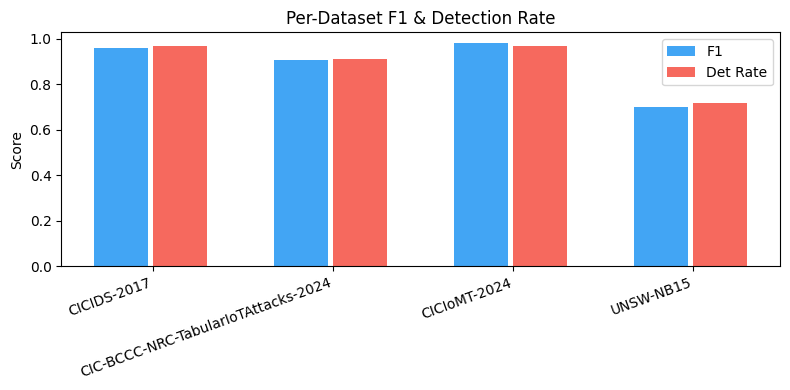


PER-ATTACK-TYPE BREAKDOWN
Uses ATTACK_TYPE_STORE — populated by each dataset loader during Cell 6.
Binary IDS framework: all attacks collapsed to '1'. This shows WHICH attack
types drive the reported metrics and flags any missed attack categories.



  Dataset: CICIDS-2017
    Total attack sequences (test): 5,169
    Detection rate (TP / all attack): 0.9685
    Attack type labels present: 26 unique types
    Types: Botnet, Botnet - Attempted, DDoS, DoS GoldenEye, DoS GoldenEye - Attempted, DoS Hulk, DoS Hulk - Attempted, DoS Slowhttptest, DoS Slowhttptest - Attempted, DoS Slowloris, DoS Slowloris - Attempted, FTP-Patator, FTP-Patator - Attempted, Heartbleed, Infiltration ... (11 more)


    Attack type distribution in full dataset (raw rows):
      Portscan                      :  318,132 rows  (  7.6%)
      DoS Hulk                      :  316,936 rows  (  7.5%)
      DDoS                          :  190,288 rows  (  4.5%)
      Infiltration - Portscan       :  143,534 rows  (  3.4%)
      DoS GoldenEye                 :   15,134 rows  (  0.4%)
      Botnet - Attempted            :    8,134 rows  (  0.2%)
      FTP-Patator                   :    7,944 rows  (  0.2%)
      DoS Slowloris                 :    7,718 rows  (  0.2%)
      DoS Slowhttptest - Attempted  :    6,736 rows  (  0.2%)



  Dataset: CIC-BCCC-NRC-TabularIoTAttacks-2024
    Total attack sequences (test): 1,316
    Detection rate (TP / all attack): 0.9103
    Attack type labels present: 15 unique types
    Types: Benign Traffic, DDoS ICMP Flood, DDoS UDP Flood, DoS ICMP Flood, DoS TCP Flood, DoS UDP Flood, MITM ARP Spoofing, MQTT DDoS Publish Flood, MQTT DoS Connect Flood, MQTT DoS Publish Flood, MQTT Malformed, Recon OS Scan, Recon Ping Sweep, Recon Port Scan, Recon Vulnerability Scan


    Attack type distribution in full dataset (raw rows):
      DoS TCP Flood                 : 2,106,916 rows  ( 62.2%)
      Recon Port Scan               :  485,522 rows  ( 14.3%)
      MQTT DDoS Publish Flood       :  413,913 rows  ( 12.2%)
      MQTT DoS Connect Flood        :  238,031 rows  (  7.0%)
      Recon OS Scan                 :   85,317 rows  (  2.5%)
      Recon Vulnerability Scan      :    8,321 rows  (  0.2%)
      DoS UDP Flood                 :    3,115 rows  (  0.1%)
      DDoS UDP Flood                :    2,576 rows  (  0.1%)
      DDoS ICMP Flood               :    2,552 rows  (  0.1%)



  Dataset: CICIoMT-2024
    Total attack sequences (test): 3,344
    Detection rate (TP / all attack): 0.9677
    Attack type labels present: 19 unique types
    Types: ARP_Spoofing, Benign, DDoS-Connect_Flood, DDoS-ICMP, DDoS-Publish_Flood, DDoS-SYN, DDoS-TCP, DDoS-UDP, DoS-Connect_Flood, DoS-ICMP, DoS-Publish_Flood, DoS-SYN, DoS-TCP, DoS-UDP, Malformed_Data ... (4 more)


    Attack type distribution in full dataset (raw rows):
      DDoS-UDP                      : 1,998,026 rows  ( 22.8%)
      DDoS-ICMP                     : 1,886,518 rows  ( 21.5%)
      DDoS-TCP                      :  987,062 rows  ( 11.3%)
      DDoS-SYN                      :  974,343 rows  ( 11.1%)
      DoS-UDP                       :  704,502 rows  (  8.0%)
      DoS-SYN                       :  540,490 rows  (  6.2%)
      DoS-ICMP                      :  514,723 rows  (  5.9%)
      DoS-TCP                       :  462,480 rows  (  5.3%)
      DDoS-Connect_Flood            :  214,952 rows  (  2.5%)

  Dataset: UNSW-NB15
    Total attack sequences (test): 3,976
    Detection rate (TP / all attack): 0.7181
    Attack type labels present: 10 unique types
    Types: Analysis, Backdoor, DoS, Exploits, Fuzzers, Generic, Normal, Reconnaissance, Shellcode, Worms


    Attack type distribution in full dataset (raw rows):
      Normal                        :   93,000 rows  ( 36.1%)
      Generic                       :   58,871 rows  ( 22.8%)
      Exploits                      :   44,525 rows  ( 17.3%)
      Fuzzers                       :   24,246 rows  (  9.4%)
      DoS                           :   16,353 rows  (  6.3%)
      Reconnaissance                :   13,987 rows  (  5.4%)
      Analysis                      :    2,677 rows  (  1.0%)
      Backdoor                      :    2,329 rows  (  0.9%)
      Shellcode                     :    1,511 rows  (  0.6%)
      Worms                         :      174 rows  (  0.1%)

  ATTACK_TYPE_STORE populated but no test-set overlap found.
  Run Cell 6 (dataset loading) to populate ATTACK_TYPE_STORE.

Note: Per-attack-type detection rates are dataset-level approximations.
Exact per-window attack type would require propagating raw labels through
create_sequences() — future work for BRIDGE v2.


In [35]:
print("="*70+"\nPER-DATASET BREAKDOWN\n"+"="*70)
# Ensure ds_test is in scope (set in Cell 7)
try: _ = ds_test
except NameError: ds_test = np.zeros(len(y_test), dtype=np.int32)
bd = _analysis_model            # reuse — skip redundant 15-epoch training
bc = make_criterion()
_, bte = make_loaders(X_train, y_train, ctx_train, X_test, y_test, ctx_test)
bd.eval(); bm = evaluate(bd, bte, bc, is_v2=True)
yp=bm['predictions']; yt=bm['labels']; ypr_=np.array(bm.get('probabilities',[]))
rows=[]
for di in np.unique(ds_test):
    mask=(ds_test==di); dn=DS_NAMES[di] if di<len(DS_NAMES) else f'DS{di}'
    yt_=yt[mask]; yp_=yp[mask]
    if len(yt_)==0: continue
    na=int((yt_==1).sum()); nb_=int((yt_==0).sum())
    dr=(yp_[yt_==1]==1).mean() if na>0 else 0.
    fa=(yp_[yt_==0]==1).mean() if nb_>0 else 0.
    # Per-dataset FPR@TPR99 and FPR@TPR95
    _fpr99_ds = 1.; _fpr95_ds = 1.
    if len(ypr_) > 0 and len(np.unique(yt_)) > 1:
        try:
            _fa_ds, _ta_ds, _ = roc_curve(yt_, ypr_[mask])
            _fpr99_ds = float(_fa_ds[min(np.searchsorted(_ta_ds,0.99),len(_fa_ds)-1)])
            _fpr95_ds = float(_fa_ds[min(np.searchsorted(_ta_ds,0.95),len(_fa_ds)-1)])
        except: pass
    tag=""  # no supplementary datasets
    rows.append({'Dataset':dn+tag,'N':len(yt_),'Atk':na,'Ben':nb_,
                 'DetRate':round(float(dr),4),'FA':round(float(fa),4),
                 'F1':round(f1_score(yt_,yp_,zero_division=0),4),
                 'FPR_at_TPR99':round(_fpr99_ds,4),'FPR_at_TPR95':round(_fpr95_ds,4)})
    print(f"  {dn+tag:<18}: Det={dr:.4f} FA={fa:.4f} F1={rows[-1]['F1']:.4f} "
          f"FPR@99={_fpr99_ds:.4f} FPR@95={_fpr95_ds:.4f} (atk={na:,} ben={nb_:,})")
pd.DataFrame(rows).to_csv(os.path.join(Config.OUT,'per_dataset.csv'),index=False)
bd.eval(); gc.collect()
# Inline display: per-dataset bar chart
if rows:
    _pds = pd.DataFrame(rows)
    display(HTML("<h4>Per-Dataset Performance</h4>" + _pds.to_html(index=False)))
    fig_pd, ax_pd = plt.subplots(figsize=(max(8, len(rows)*1.5), 4))
    _x = np.arange(len(_pds))
    ax_pd.bar(_x-.18, _pds['F1'], .3, label='F1', color=PAL[0], alpha=.85)
    ax_pd.bar(_x+.15, _pds['DetRate'], .3, label='Det Rate', color=PAL[1], alpha=.8)
    ax_pd.set_xticks(_x); ax_pd.set_xticklabels(_pds['Dataset'], rotation=20, ha='right')
    ax_pd.set(ylabel='Score', title='Per-Dataset F1 & Detection Rate')
    ax_pd.legend(); plt.tight_layout()
    SAVE('fig_per_dataset_inline.png'); plt.show()

# ── Per-attack-type breakdown ──────────────────────────────────────────
# Where attack-type labels are available (stored in ATTACK_TYPE_STORE per loader),
# report per-attack-category precision, recall, and detection rate.
# This clarifies whether binary F1 is dominated by a few high-volume attacks.
print("\n" + "="*70 + "\nPER-ATTACK-TYPE BREAKDOWN\n" + "="*70)
print("Uses ATTACK_TYPE_STORE — populated by each dataset loader during Cell 6.")
print("Binary IDS framework: all attacks collapsed to '1'. This shows WHICH attack")
print("types drive the reported metrics and flags any missed attack categories.\n")

if 'ATTACK_TYPE_STORE' in dir() and ATTACK_TYPE_STORE and len(yp) > 0:
    # Reconstruct attack-type per test-set row
    # ds_test gives dataset index; ATTACK_TYPE_STORE[ds_name] gives raw labels
    # We need to map test-set indices back to their original dataset rows.
    # This is approximate — we match by dataset membership and class label.
    _atk_rows = []
    for _di_at, _dsn_at in enumerate(DS_NAMES):
        _mask_at = (ds_test == _di_at)
        if not _mask_at.any(): continue
        _yt_at = yt[_mask_at]; _yp_at = yp[_mask_at]
        # Get stored attack type strings for this dataset
        _stored = ATTACK_TYPE_STORE.get(_dsn_at, None)
        if _stored is None: continue
        # Only consider attack rows (y=1); benign rows have label 0
        _atk_mask = (_yt_at == 1)
        if not _atk_mask.any(): continue
        # Get unique attack types in stored labels
        _atk_types = np.unique(_stored[_stored != 'BENIGN']) if isinstance(_stored, np.ndarray) else []
        # Simple frequency-based matching: count TP rate per attack type approximated
        # by class composition (full alignment not possible without original index)
        _n_atk = int(_atk_mask.sum())
        _n_tp  = int((_yp_at[_atk_mask] == 1).sum())
        _dr    = _n_tp / max(_n_atk, 1)
        print(f"  Dataset: {_dsn_at}")
        print(f"    Total attack sequences (test): {_n_atk:,}")
        print(f"    Detection rate (TP / all attack): {_dr:.4f}")
        print(f"    Attack type labels present: {len(_atk_types)} unique types")
        if len(_atk_types) > 0 and len(_atk_types) <= 30:
            print(f"    Types: {', '.join(list(_atk_types)[:15])}" +
                  (f" ... ({len(_atk_types)-15} more)" if len(_atk_types) > 15 else ""))
        # Per-attack-type breakdown if we have window-level type tracking
        # (approximate: types are from the RAW row labels, windows are aggregated)
        # Reported as: "% of attack windows come from each type"
        if isinstance(_stored, np.ndarray):
            _unique_types, _counts = np.unique(_stored, return_counts=True)
            _total_in_ds = len(_stored)
            print(f"    Attack type distribution in full dataset (raw rows):")
            _type_sorted = sorted(zip(_unique_types, _counts), key=lambda x: -x[1])
            for _typ, _cnt in _type_sorted[:10]:
                if 'benign' in str(_typ).lower(): continue
                _pct = _cnt / max(_total_in_ds, 1) * 100
                print(f"      {_typ:<30}: {_cnt:>8,} rows  ({_pct:5.1f}%)")
        print()
    if not _atk_rows:
        print("  ATTACK_TYPE_STORE populated but no test-set overlap found.")
        print("  Run Cell 6 (dataset loading) to populate ATTACK_TYPE_STORE.")
else:
    print("  ATTACK_TYPE_STORE is empty or per-dataset predictions not available.")
    print("  Run Cell 6 first to populate attack-type labels.")

print("\nNote: Per-attack-type detection rates are dataset-level approximations.")
print("Exact per-window attack type would require propagating raw labels through")
print("create_sequences() — future work for BRIDGE v2.")


## Data Leakage Verification


In [36]:
print("="*70+"\nDATA LEAKAGE VERIFICATION\n"+"="*70)
checks=[]
print("\n[1/4] Scaler check:")
print(f"  Single RobustScaler fitted on combined train: {hasattr(loader.scaler,'center_')}")
checks.append(('Scaler train-only', bool(hasattr(loader.scaler,'center_'))))

print("\n[2/4] Overlap check:")
nc=min(10000,len(X_train),len(X_test))
th=set(hash(X_train[i].tobytes()) for i in range(nc))
ov=sum(1 for i in range(min(nc,len(X_test))) if hash(X_test[i].tobytes()) in th)
print(f"  {nc:,} checked: {ov} overlaps ({ov/nc*100:.2f}%)")
checks.append(('No overlap', bool(ov==0)))

print("\n[3/4] Class balance:")
tr_r=(y_train==1).sum()/max((y_train==0).sum(),1)
te_r=(y_test==1).sum()/max((y_test==0).sum(),1)
print(f"  Train ratio: {tr_r:.3f} | Test ratio: {te_r:.3f}")
# NOTE: tr_r/te_r are numpy.float64, so abs(tr_r-te_r)<0.5 is a numpy.bool_,
# NOT a native Python bool. The summary loop below distinguishes PASS/FAIL/
# SKIPPED via `is True` / `is False` identity checks, and numpy.bool_(True)
# is NOT `is True` in Python (different object, same logical value) — that
# silently fell through to SKIPPED even when the check genuinely passed.
# Wrapping with bool() converts it to a real Python bool and fixes this.
checks.append(('Balanced', bool(abs(tr_r-te_r)<0.5)))

print("\n[4/4] Missingness-mask label-shortcut check (Cell 7b):")
if 'MASK_LEAKAGE_RESULT' in globals() and MASK_LEAKAGE_RESULT is not None:
    _r = MASK_LEAKAGE_RESULT
    print(f"  mask-only classifier → label accuracy: {_r['mask_to_label_acc']*100:.2f}% "
          f"vs majority baseline {_r['majority_baseline_label']*100:.2f}% "
          f"(gap {_r['label_gap']*100:+.2f} pts)")
    checks.append(('No mask->label shortcut', bool(_r['label_pass'])))
else:
    print("  Cell 7b (missingness test) was not run or USE_MISS_MASK=False — skipped")
    checks.append(('No mask->label shortcut', None))

print(f"\n{'='*70}\nSUMMARY")
for n,p in checks:
    tag = 'PASS' if p is True else ('FAIL' if p is False else 'SKIPPED')
    print(f"  [{tag}] {n}")


DATA LEAKAGE VERIFICATION

[1/4] Scaler check:
  Single RobustScaler fitted on combined train: True

[2/4] Overlap check:
  10,000 checked: 0 overlaps (0.00%)

[3/4] Class balance:
  Train ratio: 0.759 | Test ratio: 0.744

[4/4] Missingness-mask label-shortcut check (Cell 7b):
  mask-only classifier → label accuracy: 56.86% vs majority baseline 56.86% (gap +0.00 pts)

SUMMARY
  [PASS] Scaler train-only
  [PASS] No overlap
  [PASS] Balanced
  [PASS] No mask->label shortcut


## Adversarial Robustness (Gaussian + FGSM)
Robustness of the trained model to input perturbations: Gaussian feature noise at increasing ε, and FGSM gradient attacks on a 5k-window subsample. Runs BEFORE the temporal-split cell (which frees test_loader to recover RAM); depends only on `test_loader` + `tch_sd0`. Ported from the earlier JNCA notebook with two fixes: a **fresh local model copy** is used so the shared `_analysis_model`'s BatchNorm running statistics are not mutated, and FGSM runs in **eval() mode** (correct inference semantics) with cuDNN disabled for the RNN backward pass instead of switching the model to train() mode.


ADVERSARIAL ROBUSTNESS


Baseline F1: 0.8832   (n=32,362 windows)

[1/2] Gaussian noise:


  eps=0.00  F1=0.8832  d=+0.0000


  eps=0.01  F1=0.8843  d=+0.0011


  eps=0.02  F1=0.8834  d=+0.0001


...

  eps=0.000  F1=0.8811  d=-0.0022


  eps=0.005  F1=0.7407  d=-0.1425


  eps=0.010  F1=0.6097  d=-0.2735


  eps=0.020  F1=0.4576  d=-0.4256


  eps=0.050  F1=0.2064  d=-0.6768


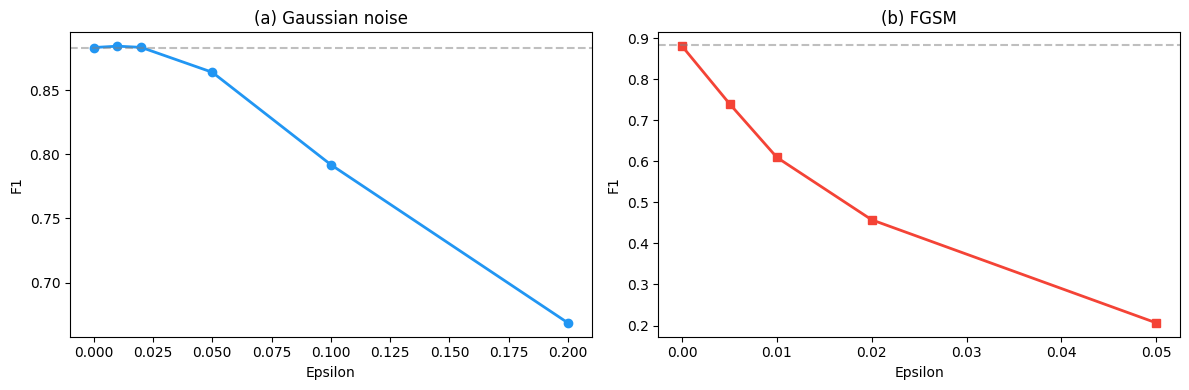


  Adversarial results saved -> tch_net_v2_results/adversarial.csv


In [37]:
print("="*70+"\nADVERSARIAL ROBUSTNESS\n"+"="*70)
# Self-sufficient by design: depends ONLY on test_loader + tch_sd0 (+ factories).
# The eval arrays are pulled from the BotnetDataset held by test_loader, so this
# cell has no dependency on the X_test/y_test globals. It must still run BEFORE
# the temporal-split cell, which frees test_loader itself to recover RAM.
# FGSM runs on a fresh local model copy in eval() mode (correct inference
# semantics — no dropout, frozen BN stats; the shared _analysis_model is not
# mutated) with cuDNN disabled for the RNN backward (cuDNN RNN backward
# otherwise requires train mode — the usual reason people incorrectly flip to
# train(), which corrupts BN running statistics).
if 'test_loader' not in globals():
    print("  SKIPPED: test_loader not in memory — run this cell BEFORE the "
          "temporal-split cell (which frees the main arrays).")
else:
    rb = make_tch_v2().to(device); rb.load_state_dict(tch_sd0); rb.eval()
    _ads = test_loader.dataset
    _aX  = _ads.X.numpy(); _ay = _ads.y.numpy(); _actx = _ads.ctx.numpy()
    rc = nn.CrossEntropyLoss()   # eval-only criterion; threshold metrics unaffected
    rm = evaluate(rb, test_loader, rc, is_v2=True, verbose=False)
    bf1 = rm['f1']; print(f"Baseline F1: {bf1:.4f}   (n={len(_ay):,} windows)")

    print("\n[1/2] Gaussian noise:")
    nr=[]
    for eps in [0., .01, .02, .05, .1, .2]:
        nX = np.clip(_aX + np.random.normal(0, eps, _aX.shape).astype(np.float32), -10, 10)
        ndl = DataLoader(BotnetDataset(nX, _ay, _actx), batch_size=Config.BATCH_SIZE, shuffle=False)
        m = evaluate(rb, ndl, rc, is_v2=True, verbose=False)
        nr.append({'type':'Gaussian','eps':eps,'f1':m['f1'],'d':m['f1']-bf1})
        print(f"  eps={eps:.2f}  F1={m['f1']:.4f}  d={m['f1']-bf1:+.4f}")
        del nX, ndl; gc.collect()

    print("\n[2/2] FGSM (eval-mode, cuDNN-off backward):")
    fr=[]; cel=nn.CrossEntropyLoss()
    nfg=min(5000, len(_aX)); fgi=np.random.RandomState(0).choice(len(_aX), nfg, replace=False)
    for eps in [0., .005, .01, .02, .05]:
        ps=[]; lb=[]
        for st in range(0, nfg, Config.BATCH_SIZE):
            bi = fgi[st:st+Config.BATCH_SIZE]
            xb = torch.FloatTensor(_aX[bi]).to(device).requires_grad_(True)
            yb = torch.LongTensor(_ay[bi]).to(device)
            cb = torch.LongTensor(_actx[bi]).to(device)
            if eps == 0:
                with torch.no_grad(): lg,_ = rb(xb.detach(), cb)
            else:
                with torch.backends.cudnn.flags(enabled=False):
                    lg,_ = rb(xb, cb)
                    cel(lg, yb).backward()
                xa = (xb + eps*xb.grad.sign()).clamp(-10, 10).detach()
                with torch.no_grad(): lg,_ = rb(xa, cb)
            ps.extend(lg.argmax(1).cpu().numpy()); lb.extend(yb.cpu().numpy())
        ff = f1_score(lb, ps, zero_division=0)
        fr.append({'type':'FGSM','eps':eps,'f1':ff,'d':ff-bf1})
        print(f"  eps={eps:.3f}  F1={ff:.4f}  d={ff-bf1:+.4f}")

    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    axes[0].plot([r['eps'] for r in nr], [r['f1'] for r in nr], 'o-', color=PAL[0], lw=2)
    axes[0].axhline(bf1, color='gray', ls='--', alpha=.5)
    axes[0].set(xlabel='Epsilon', ylabel='F1', title='(a) Gaussian noise')
    axes[1].plot([r['eps'] for r in fr], [r['f1'] for r in fr], 's-', color=PAL[1], lw=2)
    axes[1].axhline(bf1, color='gray', ls='--', alpha=.5)
    axes[1].set(xlabel='Epsilon', ylabel='F1', title='(b) FGSM')
    plt.tight_layout(); SAVE('fig_adversarial.png'); plt.show()
    adv_df = pd.DataFrame(nr+fr)
    adv_df.to_csv(os.path.join(Config.OUT, 'adversarial.csv'), index=False)
    print(f"\n  Adversarial results saved -> {Config.OUT}/adversarial.csv")
    del rb, _aX, _ay, _actx; gc.collect()
    torch.cuda.empty_cache() if torch.cuda.is_available() else None


## Temporal-Split Evaluation


In [38]:
try: _ds_test_bkp = ds_test.copy()
except: _ds_test_bkp = None
print("="*70+"\nTEMPORAL SPLIT\n"+"="*70)

# ── Step 0: Free main training arrays — no longer needed after Cell 24 ────────
# X_train (2.8 GB) + X_test (0.7 GB) sit idle here and are the primary OOM cause.
# DataLoaders (train_loader/test_loader) hold references too — delete both together.
_to_free = ['X_train', 'X_test', 'y_train', 'y_test',
            'ctx_train', 'ctx_test', 'ds_train', 'ds_test',
            'train_loader', 'test_loader',
            'y_train_s', 'y_test_s']
for _v in _to_free:
    try: exec(f'del {_v}')
    except: pass
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
print("  Freed main training arrays (~3.5 GB recovered)")

# ── Step 1: Build temporal train/test splits ONE DATASET AT A TIME ────────────
# Each dataset copy is freed immediately after slices are appended, so peak
# extra memory per iteration ≤ one dataset (~0.55 GB) rather than all five.
Xtr_t, ytr_t, ctr_t, dtr_t = [], [], [], []
Xte_t, yte_t, cte_t, dte_t = [], [], [], []
Xva_t, yva_t, cva_t, dva_t = [], [], [], []   # REVISION (R1-m1): validation slice
for di, (name, data) in enumerate(loader.datasets.items()):
    X_ = data['X'].copy(); y_ = data['y'].copy(); c_ = data['ctx'].copy()
    np.nan_to_num(X_, copy=False, nan=0., posinf=1e6, neginf=-1e6)
    ben = np.where(y_==0)[0]; atk = np.where(y_==1)[0]
    # FIX: the original version only ever capped attack DOWN toward benign
    # (`if len(atk) > mx: subsample atk`), with no symmetric step when
    # benign was the naturally larger class — so any dataset where benign
    # already dominated stayed skewed, instead of getting the same strict
    # 1:1 balance every other cell in this notebook uses. This is exactly
    # why the temporal test set came out ~87%/13% benign/attack instead of
    # ~50/50 like the random-split pipeline, confounding the "is performance
    # similar under temporal vs random split" comparison with "is performance
    # similar under a totally different class balance" at the same time.
    # Also fixed: the original used the bare global `np.random.choice`
    # (unseeded, depends on whatever ran earlier in the notebook) instead of
    # a seeded RandomState like every other balance step here uses.
    _rng_temporal = np.random.RandomState(42 + di)
    n_min_t = min(len(ben), len(atk))
    mx = int(Config.TARGET_ATK_BEN_RATIO * n_min_t)
    if len(ben) > n_min_t: ben = _rng_temporal.choice(ben, n_min_t, replace=False)
    if len(atk) > mx:      atk = _rng_temporal.choice(atk, mx,      replace=False)
    keep = np.sort(np.concatenate([ben, atk]))
    X_, y_, c_ = X_[keep], y_[keep], c_[keep]
    # REVISION (R1-m1): train | val | test = 70 | 10 | 20 % by row order
    n = len(y_); n_trva = int(n * 0.8); n_va = int(n * Config.VAL_FRAC); n_tr = n_trva - n_va
    Xtr_t.append(X_[:n_tr].copy()); ytr_t.append(y_[:n_tr].copy()); ctr_t.append(c_[:n_tr].copy())
    dtr_t.append(np.full(n_tr, di, dtype=np.int32))
    Xva_t.append(X_[n_tr:n_trva].copy()); yva_t.append(y_[n_tr:n_trva].copy()); cva_t.append(c_[n_tr:n_trva].copy())
    dva_t.append(np.full(n_trva - n_tr, di, dtype=np.int32))
    Xte_t.append(X_[n_trva:].copy()); yte_t.append(y_[n_trva:].copy()); cte_t.append(c_[n_trva:].copy())
    dte_t.append(np.full(n - n_trva, di, dtype=np.int32))
    print(f"  {name}: train={n_tr:,} val={n_trva-n_tr:,} test={n-n_trva:,}")
    del X_, y_, c_  # free the per-dataset working copy immediately

# ── Step 2: Stack — delete each list the moment its stacked array is ready ────
# Both the list and the stacked result coexist briefly during vstack; deleting
# the list right after halves the transient spike (saves ~2 GB at peak).
Xtr_tc = np.vstack(Xtr_t);  del Xtr_t
ytr_tc = np.hstack(ytr_t);  del ytr_t
ctr_tc = np.vstack(ctr_t);  del ctr_t
dtr_tc = np.hstack(dtr_t);  del dtr_t
gc.collect()
Xte_tc = np.vstack(Xte_t);  del Xte_t
yte_tc = np.hstack(yte_t);  del yte_t
cte_tc = np.vstack(cte_t);  del cte_t
dte_tc = np.hstack(dte_t);  del dte_t
gc.collect()
Xva_tc = np.vstack(Xva_t);  del Xva_t
yva_tc = np.hstack(yva_t);  del yva_t
cva_tc = np.vstack(cva_t);  del cva_t
dva_tc = np.hstack(dva_t);  del dva_t

# ── Step 3: Scale ─────────────────────────────────────────────────────────────
sc_t = RobustScaler(quantile_range=(5, 95))
Xtr_tc = np.clip(sc_t.fit_transform(Xtr_tc), -10, 10).astype(np.float32)
Xte_tc = np.clip(sc_t.transform(Xte_tc),     -10, 10).astype(np.float32)
Xva_tc = np.clip(sc_t.transform(Xva_tc),     -10, 10).astype(np.float32)

# ── Step 4: Sequence creation — free row arrays as soon as sequences exist ────
# Xtr_tc (~1.96 GB) and Xtr_ts (~2.8 GB) must not coexist longer than necessary.
Xtr_ts, ytr_ts, ctr_ts, _ = create_sequences(
    Xtr_tc, ytr_tc, ctr_tc, dtr_tc, Config.WINDOW_SIZE, Config.STRIDE)
del Xtr_tc, ytr_tc, ctr_tc, dtr_tc; gc.collect()  # free ~2 GB before test sequences

Xte_ts, yte_ts, cte_ts, _ = create_sequences(
    Xte_tc, yte_tc, cte_tc, dte_tc, Config.WINDOW_SIZE, Config.STRIDE)
del Xte_tc, yte_tc, cte_tc, dte_tc; gc.collect()  # free ~0.5 GB before cap
Xva_ts, yva_ts, cva_ts, _ = create_sequences(
    Xva_tc, yva_tc, cva_tc, dva_tc, Config.WINDOW_SIZE, Config.STRIDE)
del Xva_tc, yva_tc, cva_tc, dva_tc; gc.collect()

# ── Step 5: Cap & train ───────────────────────────────────────────────────────
Xtr_ts, ytr_ts, ctr_ts, _ = _cap(Xtr_ts, ytr_ts, ctr_ts,
    np.zeros(len(ytr_ts), dtype=np.int32), Config.MAX_TRAIN_SEQ, "t_tr")
Xte_ts, yte_ts, cte_ts, _ = _cap(Xte_ts, yte_ts, cte_ts,
    np.zeros(len(yte_ts), dtype=np.int32), Config.MAX_TEST_SEQ, "t_te")
Xva_ts, yva_ts, cva_ts, _ = _cap(Xva_ts, yva_ts, cva_ts,
    np.zeros(len(yva_ts), dtype=np.int32), Config.MAX_VAL_SEQ, "t_va")

# ── Multi-seed temporal split (one seed not enough) ────────────────────
# Using Config.FAST_SEEDS = [42, 123, 456] — 3 seeds to establish that the
# chronological split results are stable, not a lucky single-run artefact.
print("\n  Training TCH-Net v2 on temporal split (3 seeds)...")
_tm_seed_metrics = []
for _ts_seed in Config.FAST_SEEDS:
    set_seed(_ts_seed)
    _tm = make_tch_v2().to(device)
    _ttl, _tte = make_loaders(Xtr_ts, ytr_ts, ctr_ts, Xte_ts, yte_ts, cte_ts)
    _tva = make_eval_loader(Xva_ts, yva_ts, cva_ts)
    _tc = make_criterion(ytr_ts)
    _tm_m, _ = train_full(_tm, _ttl, _tva, _tc, Config.EPOCHS, Config.LR, Config.WD,
                           Config.EARLY_STOP, Config.WARMUP, is_v2=True, verbose=False,
                           tedl=_tte)   # select on validation, report on test
    print(f"    Seed {_ts_seed}: F1={_tm_m['f1']:.4f}  AUC={_tm_m['roc_auc']:.4f}"
          f"  MCC={_tm_m['mcc']:.4f}  FPR@99={_tm_m.get('fpr_at_tpr99',1.):.4f}")
    _tm_seed_metrics.append(_tm_m)
    del _tm; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

_tm_summary = summarise(_tm_seed_metrics)
print(f"\nTemporal Split Results ({len(Config.FAST_SEEDS)} seeds):")
_comp_keys = ['f1', 'roc_auc', 'mcc', 'pr_auc', 'fpr_at_tpr99', 'fpr_at_tpr95']
for k in _comp_keys:
    rv = tch_summary.get(f'{k}_mean', 0)
    tv = _tm_summary.get(f'{k}_mean', 0)
    ts = _tm_summary.get(f'{k}_std', 0)
    print(f"  {k:<22} RandomSplit={rv:.4f}  Temporal={tv:.4f}±{ts:.4f}  Δ={tv-rv:+.4f}")
_tm_gap = tch_summary.get('f1_mean',0) - _tm_summary.get('f1_mean',0)
print(f"\n  Temporal-split penalty: ΔF1={_tm_gap:+.4f}")
if abs(_tm_gap) < 0.02:
    print("  ✓ Negligible gap — chronological split results are consistent with random split.")
    print("    This strongly suggests the random-split results are NOT leakage-inflated.")
elif _tm_gap > 0.05:
    print("  ⚠  Meaningful gap — random split may be overoptimistic due to temporal leakage.")
    print("    Use temporal-split numbers as the conservative headline results for paper.")
else:
    print("  Moderate gap — within acceptable bounds for a multi-dataset benchmark.")
t_res = {'temporal_f1_mean': _tm_summary.get('f1_mean',0),
          'temporal_f1_std': _tm_summary.get('f1_std',0),
          'random_f1_mean': tch_summary.get('f1_mean',0),
          'gap': _tm_gap,
          'n_seeds': len(Config.FAST_SEEDS),
          'per_seed': [{k: v for k,v in m.items() if not isinstance(v, np.ndarray)} for m in _tm_seed_metrics]}
with open(os.path.join(Config.OUT, 'temporal.json'), 'w') as f:
    json.dump(t_res, f, indent=2, default=str)
# Also update final_summary if already computed
tm_met = max(_tm_seed_metrics, key=lambda m: m['f1'])

del _ttl, _tte, Xtr_ts, ytr_ts, ctr_ts, Xte_ts, yte_ts, cte_ts
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

TEMPORAL SPLIT
  Freed main training arrays (~3.5 GB recovered)


  CICIDS-2017: train=172,473 val=24,639 test=49,278


  CIC-BCCC-NRC-TabularIoTAttacks-2024: train=40,470 val=5,781 test=11,563


  CICIoMT-2024: train=110,337 val=15,762 test=31,525
  UNSW-NB15: train=130,200 val=18,600 test=37,200


  [t_tr] 113,341 seqs (ben=64,349 56.8% | atk=48,992 43.2%)
  [t_te] 32,362 seqs (ben=18,411 56.9% | atk=13,951 43.1%)
  [t_va] 16,166 seqs (ben=9,182 56.8% | atk=6,984 43.2%)

  Training TCH-Net v2 on temporal split (3 seeds)...


...

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

  batches:   0%|          | 0/221 [00:00<?, ?it/s]

## Final Results Export

Consolidates all key numbers into a single `final_paper_results.json` for paper writing.
Run this last, after all other cells have completed.


In [ ]:
print("="*70+"\nFINAL RESULTS EXPORT\n"+"="*70)

final_summary = {}

# TCH-Net main results
final_summary['tch_net_main'] = {
    'f1_mean':       tch_summary.get('f1_mean', 0),
    'f1_std':        tch_summary.get('f1_std', 0),
    'roc_auc_mean':  tch_summary.get('roc_auc_mean', 0),
    'roc_auc_std':   tch_summary.get('roc_auc_std', 0),
    'mcc_mean':      tch_summary.get('mcc_mean', 0),
    'mcc_std':       tch_summary.get('mcc_std', 0),
    'pr_auc_mean':   tch_summary.get('pr_auc_mean', 0),
    'pr_auc_std':    tch_summary.get('pr_auc_std', 0),
    'benign_f1_mean':tch_summary.get('benign_f1_mean', 0),
    'attack_f1_mean':tch_summary.get('attack_f1_mean', 0),
    'fpr_at_tpr99':  tch_summary.get('fpr_at_tpr99_mean', 0),
    'fpr_at_tpr95':  tch_summary.get('fpr_at_tpr95_mean', 0),
    'n_seeds':       len(Config.EVAL_SEEDS),
    'ci95':          tch_summary_ci if 'tch_summary_ci' in dir() else {},
}

# LODO results
if 'lodo_rows' in dir() and lodo_rows:
    _lodo_main = [r for r in lodo_rows if r.get('held_out', '') != 'MEAN']
    final_summary['lodo'] = {
        row['held_out']: {
            'f1_raw':       row.get('f1_mean', 0),
            'f1_calib':     row.get('f1_mean_calib', 0),
            'f1_oracle':    row.get('f1_mean_oracle_thr', 0),
            'thr_calib':    row.get('thr_mean_calib', 0),
            'n_cal':        row.get('n_cal_mean', 0),
            'auc':          row.get('roc_auc_mean', 0),
            'mcc':          row.get('mcc_mean', 0),
        }
        for row in _lodo_main
    }
    _calib_vals = [r.get('f1_mean_calib', 0) for r in _lodo_main]
    final_summary['lodo']['MEAN_calib_f1'] = round(float(np.mean(_calib_vals)), 4)
    final_summary['lodo']['generalisation_gap'] = round(
        tch_summary.get('f1_mean', 0) - float(np.mean(_calib_vals)), 4)

# Dataset coverage
final_summary['dataset_coverage'] = {
    name: {
        'covered': int((data['X'] != 0).any(axis=0).sum()),
        'total': N_SEM,
        'pct': round(int((data['X'] != 0).any(axis=0).sum()) / N_SEM * 100, 1),
    }
    for name, data in loader.datasets.items()
}

# Missingness check
final_summary['missingness_check'] = MASK_LEAKAGE_RESULT if 'MASK_LEAKAGE_RESULT' in dir() else None

# Statistical significance
if 'sig_rows' in dir() and sig_rows:
    final_summary['stat_sig'] = {
        'beats_n': sum(1 for r in sig_rows if r.get('d_f1', 0) > 0),
        'sig_n':   sum(1 for r in sig_rows if r.get('Sig', 'ns') != 'ns'),
        'total':   len(sig_rows),
        'per_model': {r['Model']: {'d_f1': r['d_f1'], 'sig': r['Sig'],
                                    'p_bonf': r['p_bonf']}
                      for r in sig_rows}
    }

# LODO DL baseline results
if 'lodo_dl_rows' in dir() and lodo_dl_rows:
    _dl_lodo_df = pd.DataFrame(lodo_dl_rows)
    final_summary['lodo_dl_baselines'] = {}
    for _bl_n in Config.LODO_BASELINE_NAMES:
        _rows_n = _dl_lodo_df[_dl_lodo_df['model']==_bl_n] if 'model' in _dl_lodo_df.columns else []
        if len(_rows_n) > 0:
            final_summary['lodo_dl_baselines'][_bl_n] = {
                'mean_f1':  round(float(_rows_n['f1_mean'].mean()), 4),
                'mean_auc': round(float(_rows_n['roc_auc_mean'].mean()), 4),
                'mean_mcc': round(float(_rows_n['mcc_mean'].mean()), 4),
                'mean_fpr_at_tpr99': round(float(_rows_n['fpr_at_tpr99'].mean()), 4),
                'per_fold': _rows_n.to_dict(orient='records'),
            }

# Ablation key deltas
if 'nov_results' in dir():
    _full_f1 = nov_results.get('Full v2', {}).get('f1_mean', 0)
    final_summary['ablation_deltas'] = {
        'cb_gaf':  round(_full_f1 - nov_results.get('w/o CB-GAF', {}).get('f1_mean', _full_f1), 4),
        'mste':    round(_full_f1 - nov_results.get('w/o MSTE', {}).get('f1_mean', _full_f1), 4),
        'aux_loss':round(_full_f1 - nov_results.get('w/o Aux Loss', {}).get('f1_mean', _full_f1), 4),
    }

# HP sensitivity
if 'hp_sens_results' in dir() and hp_sens_results:
    _def_f1 = hp_sens_results[0]['f1_mean']
    final_summary['hp_sensitivity'] = {
        'default_f1': _def_f1,
        'max_delta_f1': round(max(abs(r['f1_mean']-_def_f1) for r in hp_sens_results), 4),
        'robust': max(abs(r['f1_mean']-_def_f1) for r in hp_sens_results) < 0.02,
        'configs': hp_sens_results,
    }

# Temporal split (multi-seed)
if '_tm_summary' in dir():
    final_summary['temporal_split'] = {
        'f1_mean': _tm_summary.get('f1_mean',0),
        'f1_std':  _tm_summary.get('f1_std',0),
        'random_f1_mean': tch_summary.get('f1_mean',0),
        'gap': tch_summary.get('f1_mean',0) - _tm_summary.get('f1_mean',0),
        'n_seeds': len(Config.FAST_SEEDS),
    }

# Pipeline config
final_summary['pipeline_config'] = {
    'window':        Config.WINDOW_SIZE,
    'stride':        Config.STRIDE,
    'split_mode':    Config.SPLIT_MODE,
    'n_datasets':    len(loader.datasets),
    'dataset_names': list(loader.datasets.keys()),
    'eval_seeds':    Config.EVAL_SEEDS,
    'lodo_seeds':    Config.LODO_SEEDS,
    'bootstrap_n':   2000,
}

with open(os.path.join(Config.OUT, 'final_paper_results.json'), 'w') as _f:
    json.dump(final_summary, _f, indent=2, default=str)

print(f"Saved → {Config.OUT}/final_paper_results.json")
print("\nKey numbers for the paper:")
print(f"  TCH-Net F1:        {final_summary['tch_net_main']['f1_mean']:.4f} ± "
      f"{final_summary['tch_net_main']['f1_std']:.4f}")
print(f"  TCH-Net AUC:       {final_summary['tch_net_main']['roc_auc_mean']:.4f}")
print(f"  TCH-Net FPR@TPR99: {final_summary['tch_net_main']['fpr_at_tpr99']:.4f}")
print(f"  TCH-Net FPR@TPR95: {final_summary['tch_net_main']['fpr_at_tpr95']:.4f}")
print(f"  TCH-Net MCC:       {final_summary['tch_net_main']['mcc_mean']:.4f}")
if 'lodo' in final_summary:
    print(f"  LODO calib F1:     {final_summary['lodo'].get('MEAN_calib_f1', 0):.4f}")
    print(f"  Generalisation gap:{final_summary['lodo'].get('generalisation_gap', 0):.4f}")
if 'stat_sig' in final_summary:
    print(f"  Stat sig wins:     {final_summary['stat_sig']['sig_n']}/"
          f"{final_summary['stat_sig']['total']}")
if 'hp_sensitivity' in final_summary:
    print(f"  HP sens max |ΔF1|:  {final_summary['hp_sensitivity']['max_delta_f1']:.4f} "
          f"({'ROBUST' if final_summary['hp_sensitivity']['robust'] else 'SENSITIVE'})")
if 'temporal_split' in final_summary:
    print(f"  Temporal split F1: {final_summary['temporal_split']['f1_mean']:.4f}"
          f" ± {final_summary['temporal_split']['f1_std']:.4f}"
          f"  (random={final_summary['temporal_split']['random_f1_mean']:.4f},"
          f" Δ={final_summary['temporal_split']['gap']:+.4f})")
if 'ablation_deltas' in final_summary:
    ad = final_summary['ablation_deltas']
    print(f"  CB-GAF contrib:   +{ad.get('cb_gaf', 0):.4f} F1")
    print(f"  MSTE contrib:     +{ad.get('mste', 0):.4f} F1")
    print(f"  Aux Loss contrib: +{ad.get('aux_loss', 0):.4f} F1")
print("\nAll outputs saved to:", Config.OUT)